#**스마트폰 센서 데이터 기반 모션 분류**
# 단계1 : 탐색적 데이터 분석

## 0.미션

### (1) 미션①
수많은 feature들을 모두 살펴보는 것은 과도한 시간과 노력이 필요합니다. 그래서 여러분은 **선택과 집중**을 해야 합니다.
* 1) **기본 모델을 생성**한 후 **변수 중요도**를 구합니다.   
    * random forest 알고리즘 사용을 권장합니다.
* 2) **중요한 feature와 중요하지 않은 feature 상위 N개를 선정**하고, 이들을 대상으로 EDA 수행.
* 3) **각 feature 그룹별 중요도**도 파악해보며 EDA를 수행  
    * Feature 이름에는 계층구조를 담고 있습니다. 그렇다 보니 feature들을 적절하게 그룹으로 묶을 수 있습니다.
    * 참고로, feature 그룹의 중요도는 개별 feature 중요도의 합으로 계산할 수 있습니다.


### (2) 미션②  
다음의 case에 맞게 feature 및 feature 그룹 중요도를 기반으로 탐색적 데이터 분석을 수행하시오.
* 1) Target을 **정적/동적 행동**으로 구분
    * 6개의 행동은 2개의 그룹(정적행동, 동적행동)으로 나뉩니다.  
    * 어떤 feature(혹은 feature 그룹)이 2개 class 그룹(정적행동, 동적행동)를 구분하는데 중요한지를 찾아보고 탐색해봅시다.
* 2) Target을 **개별 행동 여부**로 구분
    * 6가지의 행동을 분류하는 분석도 중요하지만, 개별 행동에만 특별히 영향을 받는 feature들도 있습니다.
    * 예를 들어, 계단을 오르는 행동(Walking_upstairs)과 관련이 큰 feature가 있을 것입니다. [계단을 오르는 행동]인지 아닌지로 구분하는 targe을 추가하여 EDA를 수행해 봅시다.


## 1.환경설정

### (1) 라이브러리 불러오기

* 세부 요구사항
    - 기본적으로 필요한 라이브러리를 import 하도록 코드가 작성되어 있습니다.
    - 필요하다고 판단되는 라이브러리를 추가하세요.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree
from sklearn.metrics import *

* 변수 중요도 함수 생성
    * 변수 중요도를 시각화할 수 있는 함수를 제공합니다.
    * 입력 :
        * importance : 트리모델의 변수 중요도(예: model.feature_importances_)
        * names : 변수 이름 목록(예 : x_train.columns
        * result_only  : 변수 중요도 순으로 데이터프레임만 return할지, 그래프도 포함할지 결정. False이면 결과 데이터프레임 + 그래프
        * topn : 중요도 상위 n개만 표시. all 이면 전체.
    * 출력 :
        * 중요도 그래프 : 중요도 내림차순으로 정렬
        * 중요도 데이터프레임 : 중요도 내림차순으로 정렬

In [2]:
# 변수의 특성 중요도 계산하기
def plot_feature_importance(importance, names, result_only = False, topn = 'all'):
    feature_importance = np.array(importance)
    feature_name = np.array(names)

    data={'feature_name':feature_name,'feature_importance':feature_importance}
    fi_temp = pd.DataFrame(data)

    #변수의 특성 중요도 순으로 정렬하기
    fi_temp.sort_values(by=['feature_importance'], ascending=False,inplace=True)
    fi_temp.reset_index(drop=True, inplace = True)

    if topn == 'all' :
        fi_df = fi_temp.copy()
    else :
        fi_df = fi_temp.iloc[:topn]

    #변수의 특성 중요도 그래프로 그리기
    if result_only == False :
        plt.figure(figsize=(10,100))
        sns.barplot(x='feature_importance', y='feature_name', data = fi_df)

        plt.xlabel('importance', fontsize=20, fontweight='bold')
        plt.ylabel('feature name', fontsize=20, fontweight='bold')
        plt.grid()

    return fi_df

### (2) 데이터 불러오기

* 주어진 데이터셋
    * data01_train.csv : 학습 및 검증용 데이터셋
    * feature.csv : feature 이름을 계층구조로 정리한 데이터  
 <br/>
    

* 세부 요구사항
    - 전체 데이터 'data01_train.csv' 를 불러와 'data' 변수에 저장합니다.
    - 센서 그룹 데이터 'feature.csv' 를 불러와 'features' 변수에 저장합니다.

In [3]:
data = pd.read_csv('data01_train.csv')
features = pd.read_csv('features.csv')

## 2.데이터 분석 : 기본정보 살펴보기

### (1) 기본정보 확인하기 (data 로 진행)


* **세부 요구사항**
    - 불러온 데이터의 형태, 기초통계량, 정보 등을 확인합니다.
    - 데이터의 단변량 그래프를 그려서 데이터의 단변량 분석을 해 봅니다.

In [4]:
#전체 데이터의 행,열 개수 확인
data.shape

(5881, 563)

In [5]:
#전체 데이터의 상위 5개 행 확인
data.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.288508,-0.009196,-0.103362,-0.988986,-0.962797,-0.967422,-0.989000,-0.962596,-0.965650,-0.929747,...,-0.816696,-0.042494,-0.044218,0.307873,0.072790,-0.601120,0.331298,0.165163,21,STANDING
1,0.265757,-0.016576,-0.098163,-0.989551,-0.994636,-0.987435,-0.990189,-0.993870,-0.987558,-0.937337,...,-0.693515,-0.062899,0.388459,-0.765014,0.771524,0.345205,-0.769186,-0.147944,15,LAYING
2,0.278709,-0.014511,-0.108717,-0.997720,-0.981088,-0.994008,-0.997934,-0.982187,-0.995017,-0.942584,...,-0.829311,0.000265,-0.525022,-0.891875,0.021528,-0.833564,0.202434,-0.032755,11,STANDING
3,0.289795,-0.035536,-0.150354,-0.231727,-0.006412,-0.338117,-0.273557,0.014245,-0.347916,0.008288,...,-0.408956,-0.255125,0.612804,0.747381,-0.072944,-0.695819,0.287154,0.111388,17,WALKING
4,0.394807,0.034098,0.091229,0.088489,-0.106636,-0.388502,-0.010469,-0.109680,-0.346372,0.584131,...,-0.563437,-0.044344,-0.845268,-0.974650,-0.887846,-0.705029,0.264952,0.137758,17,WALKING_DOWNSTAIRS


In [6]:
# subject(피실험자 ID) 제거
data.drop('subject', axis=1, inplace=True)

In [7]:
#전체 데이터의 수치형 변수 분포 확인
data.describe()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
count,5881.000000,5881.000000,5881.000000,5881.000000,5881.000000,5881.000000,5881.000000,5881.000000,5881.000000,5881.000000,...,5881.000000,5881.000000,5881.000000,5881.000000,5881.000000,5881.000000,5881.000000,5881.000000,5881.000000,5881.000000
mean,0.274811,-0.017799,-0.109396,-0.603138,-0.509815,-0.604058,-0.628151,-0.525944,-0.605374,-0.465490,...,0.126955,-0.305883,-0.623548,0.008524,-0.001185,0.009340,-0.007099,-0.491501,0.059299,-0.054594
std,0.067614,0.039422,0.058373,0.448807,0.501815,0.417319,0.424345,0.485115,0.413043,0.544995,...,0.249176,0.322808,0.310371,0.339730,0.447197,0.608190,0.476738,0.509069,0.297340,0.278479
min,-0.503823,-0.684893,-1.000000,-1.000000,-0.999844,-0.999667,-1.000000,-0.999419,-1.000000,-1.000000,...,-0.965725,-0.979261,-0.999765,-0.976580,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-0.980143
25%,0.262919,-0.024877,-0.121051,-0.992774,-0.977680,-0.980127,-0.993602,-0.977865,-0.980112,-0.936067,...,-0.021610,-0.541969,-0.845985,-0.122361,-0.294369,-0.481718,-0.373345,-0.811397,-0.018203,-0.141555
50%,0.277154,-0.017221,-0.108781,-0.943933,-0.844575,-0.856352,-0.948501,-0.849266,-0.849896,-0.878729,...,0.133887,-0.342923,-0.712677,0.010278,0.005146,0.011448,-0.000847,-0.709441,0.182893,0.003951
75%,0.288526,-0.010920,-0.098163,-0.242130,-0.034499,-0.262690,-0.291138,-0.068857,-0.268539,-0.013690,...,0.288944,-0.127371,-0.501158,0.154985,0.285030,0.499857,0.356236,-0.511330,0.248435,0.111932
max,1.000000,1.000000,1.000000,1.000000,0.916238,1.000000,1.000000,0.967664,1.000000,1.000000,...,0.946700,0.989538,0.956845,1.000000,1.000000,0.998702,0.996078,0.977344,0.478157,1.000000


In [8]:
#전체 데이터의 모든 변수 확인
data.columns

Index(['tBodyAcc-mean()-X', 'tBodyAcc-mean()-Y', 'tBodyAcc-mean()-Z',
       'tBodyAcc-std()-X', 'tBodyAcc-std()-Y', 'tBodyAcc-std()-Z',
       'tBodyAcc-mad()-X', 'tBodyAcc-mad()-Y', 'tBodyAcc-mad()-Z',
       'tBodyAcc-max()-X',
       ...
       'fBodyBodyGyroJerkMag-skewness()', 'fBodyBodyGyroJerkMag-kurtosis()',
       'angle(tBodyAccMean,gravity)', 'angle(tBodyAccJerkMean),gravityMean)',
       'angle(tBodyGyroMean,gravityMean)',
       'angle(tBodyGyroJerkMean,gravityMean)', 'angle(X,gravityMean)',
       'angle(Y,gravityMean)', 'angle(Z,gravityMean)', 'Activity'],
      dtype='object', length=562)

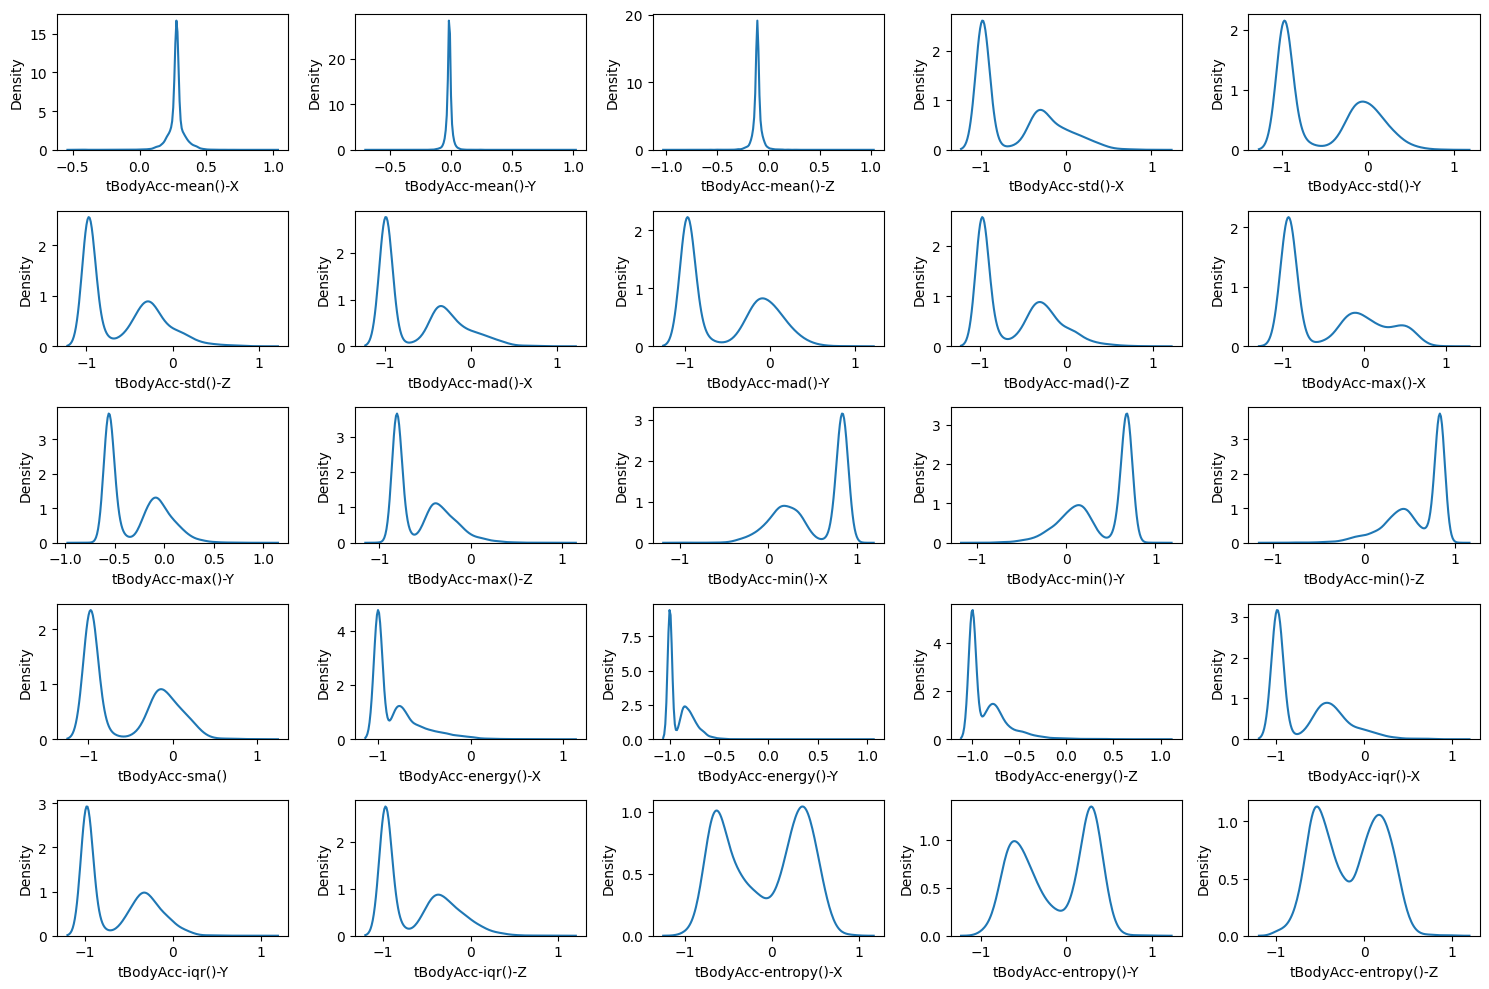

In [9]:
# kde로 tBodyAcc-mean()-X 분포 확인하기 (단변량 분석) - 예제 일뿐 다양한 방법과 다양한 변수로 단변량 그래프를 그려보세요.
fig, axes = plt.subplots(5, 5, figsize=(15,10))
idx = 0
for i in range(5):
    for j in range(5):
        sns.kdeplot(data[data.columns[idx]], ax=axes[i,j])
        idx += 1
plt.tight_layout()
plt.show()

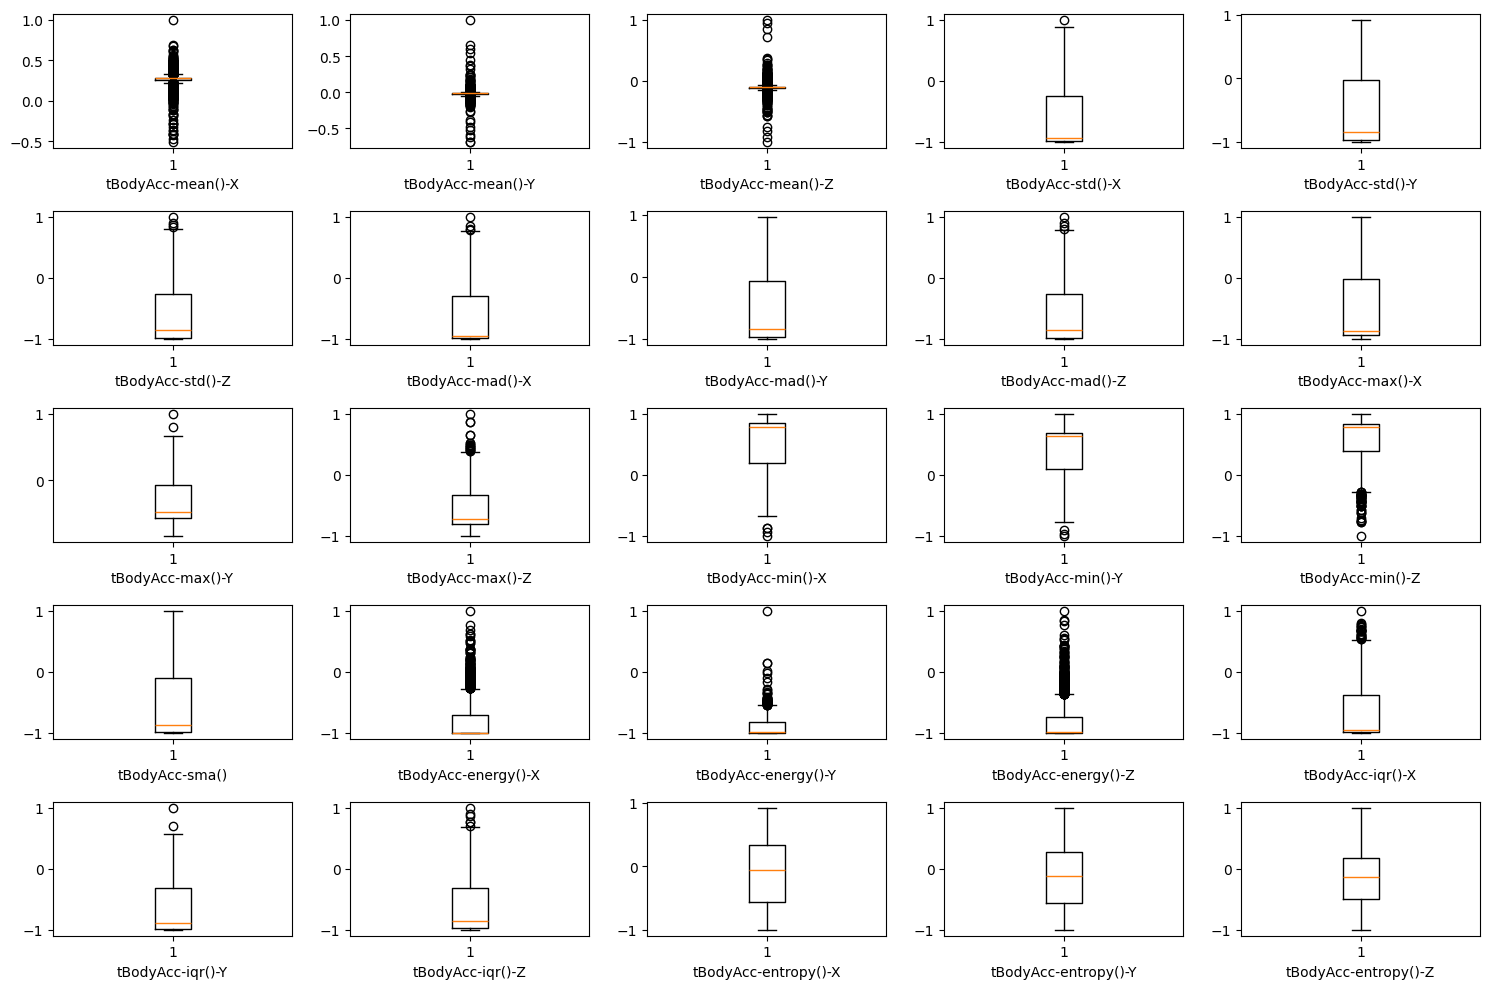

In [10]:
# boxplot() 이용
fig, axes = plt.subplots(5, 5, figsize=(15,10))
idx = 0
for i in range(5):
    for j in range(5):
        axes[i,j].boxplot(data[data.columns[idx]])
        axes[i,j].set_xlabel(data.columns[idx])
        idx += 1
plt.tight_layout()
plt.show()

In [11]:
# 전체 데이터의 이변량 분석 (corr)
data.iloc[:, :-1].corr()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
tBodyAcc-mean()-X,1.000000,0.203297,-0.266383,0.012067,-0.018489,-0.040405,0.018367,-0.019752,-0.043303,0.048725,...,0.023137,-0.012101,-0.011490,-0.567455,0.019251,0.034065,0.030968,-0.027010,0.028177,0.019025
tBodyAcc-mean()-Y,0.203297,1.000000,-0.145709,-0.049467,-0.052489,-0.058499,-0.048703,-0.053018,-0.058559,-0.038544,...,-0.015872,-0.003101,-0.003467,0.076995,-0.013001,0.019670,0.074955,0.000039,0.002376,-0.022329
tBodyAcc-mean()-Z,-0.266383,-0.145709,1.000000,-0.024839,-0.017613,-0.016924,-0.023323,-0.015794,-0.012575,-0.040397,...,-0.017359,0.018155,0.018234,0.056806,-0.036749,-0.054069,-0.035593,0.007045,-0.017900,-0.019169
tBodyAcc-std()-X,0.012067,-0.049467,-0.024839,1.000000,0.927809,0.851841,0.998656,0.921154,0.846308,0.981190,...,-0.070634,0.151555,0.116425,-0.043069,-0.032145,0.016542,-0.024749,-0.373500,0.470834,0.392843
tBodyAcc-std()-Y,-0.018489,-0.052489,-0.017613,0.927809,1.000000,0.893995,0.923386,0.997320,0.892843,0.916853,...,-0.107573,0.209119,0.177232,-0.027671,-0.022181,-0.012927,-0.015237,-0.380258,0.521249,0.429141
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"angle(tBodyGyroMean,gravityMean)",0.034065,0.019670,-0.054069,0.016542,-0.012927,-0.016674,0.016846,-0.015394,-0.021836,0.021599,...,-0.027836,0.029841,0.019651,-0.003279,0.000576,1.000000,-0.113677,-0.001992,-0.013863,-0.021702
"angle(tBodyGyroJerkMean,gravityMean)",0.030968,0.074955,-0.035593,-0.024749,-0.015237,-0.004077,-0.025205,-0.013152,-0.004784,-0.028239,...,-0.004927,-0.018015,-0.015179,-0.027075,0.029856,-0.113677,1.000000,0.012598,0.005132,0.001242
"angle(X,gravityMean)",-0.027010,0.000039,0.007045,-0.373500,-0.380258,-0.346237,-0.370024,-0.376665,-0.348279,-0.385300,...,0.077532,-0.088810,-0.080113,0.012382,0.020700,-0.001992,0.012598,1.000000,-0.783107,-0.639201
"angle(Y,gravityMean)",0.028177,0.002376,-0.017900,0.470834,0.521249,0.473572,0.466287,0.522401,0.474880,0.478832,...,-0.097644,0.092383,0.080726,-0.000955,-0.013508,-0.013863,0.005132,-0.783107,1.000000,0.590883


In [12]:
# 이변량 시각화 하기  (변수를 줄여서 해보는 것도 의미 있겠죠?)
# correlation_matrix = data.iloc[:, :-1].corr()

# plt.figure(figsize=(12, 10))
# sns.heatmap(correlation_matrix, annot=True, cmap='Blues', fmt=".2f")
# plt.title("Correlation Matrix")
# plt.show()

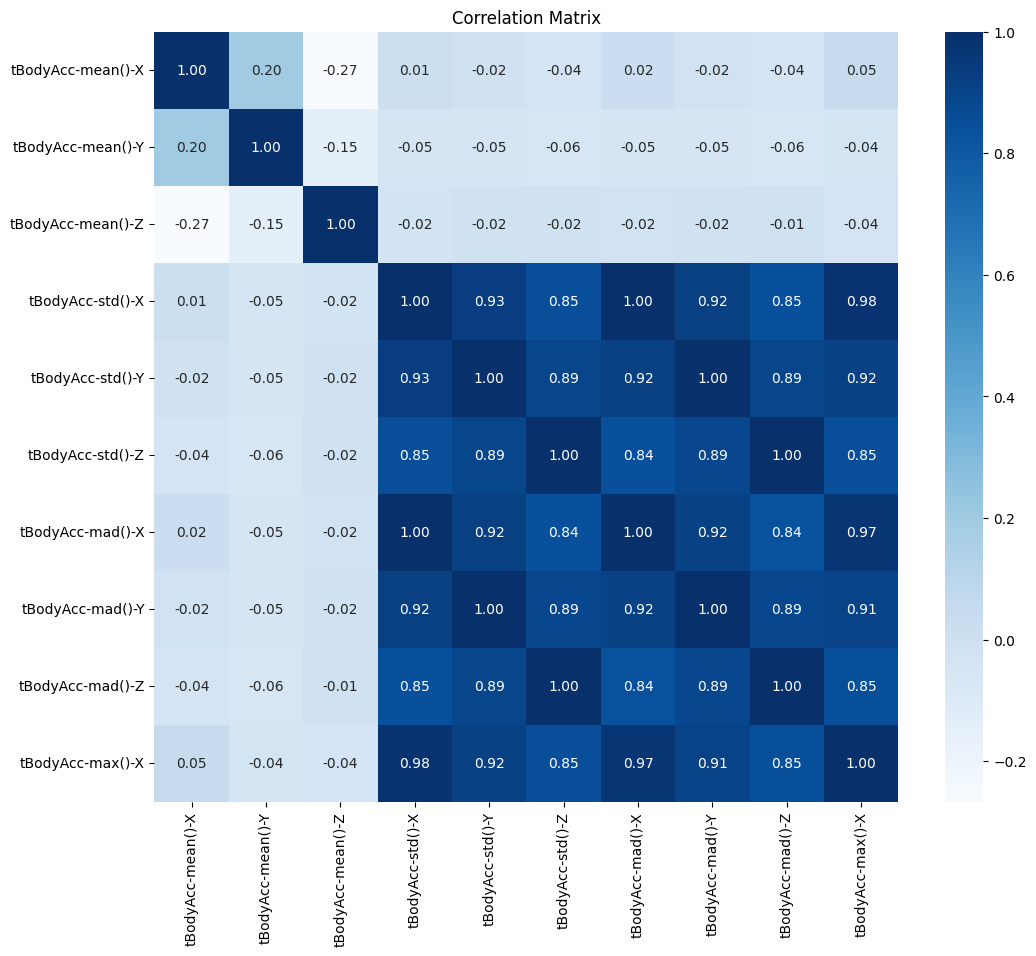

In [13]:
# 이변량 시각화(변수 10개만 선택하여 표현).
correlation_matrix = data.iloc[:, :10].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='Blues', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

### (2) 목표 변수 확인하기

* **세부 요구사항**
    - target인 'Activity'에 대해 단변량 분석을 수행합니다.
    - 범주의 종류, 범주별 빈도수 및 비율 등

In [14]:
target = data.loc[:, 'Activity']

In [15]:
# 범주의 종류
target.unique()

array(['STANDING', 'LAYING', 'WALKING', 'WALKING_DOWNSTAIRS',
       'WALKING_UPSTAIRS', 'SITTING'], dtype=object)

In [16]:
# 범주별 빈도수
target.value_counts()

,count
Activity,
LAYING,1115
STANDING,1087
SITTING,1032
WALKING,998
WALKING_UPSTAIRS,858
WALKING_DOWNSTAIRS,791


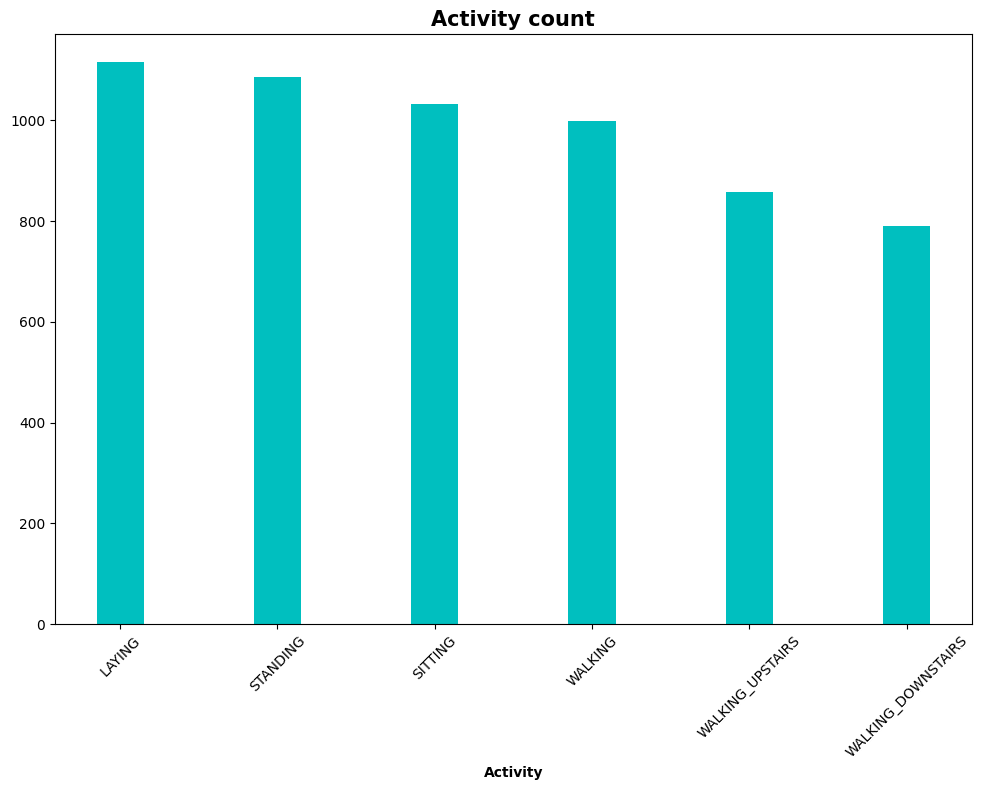

In [17]:
fig, ax = plt.subplots(figsize=(10, 8))
ax.bar(target.value_counts().index, target.value_counts(), width=0.3, color='c')
ax.set_title('Activity count', fontsize=15, fontweight='bold')
ax.set_xlabel('Activity', fontweight='bold')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
# 범주별 비율
target_proportion = target.value_counts(normalize=True)*100
target_proportion

,proportion
Activity,
LAYING,18.959361
STANDING,18.483251
SITTING,17.548036
WALKING,16.969903
WALKING_UPSTAIRS,14.589356
WALKING_DOWNSTAIRS,13.450094


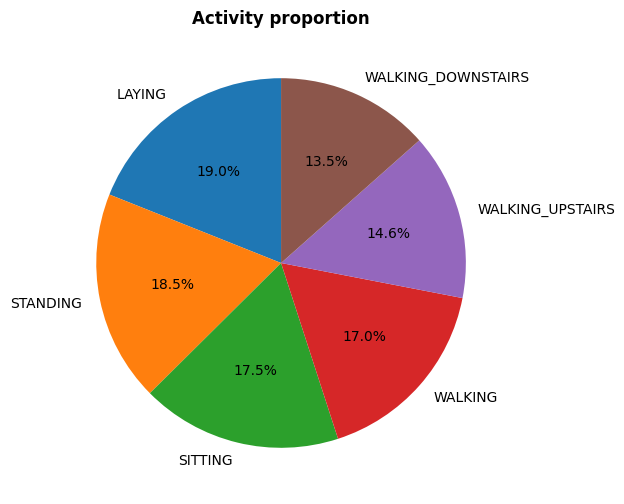

In [19]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.pie(target_proportion, labels=target_proportion.index, startangle=90, autopct='%.1f%%')
ax.set_title('Activity proportion', fontweight='bold')
plt.show()

### (3) 센서 그룹 데이터: features

* **세부 요구사항**
    - feature 이름에 대한 계층 구조별로 변수의 수를 카운트 해 봅시다.
        - sensor 별 변수의 개수
        - agg(regation) 별 변수의 개수
        - axis 별 변수의 개수

In [20]:
#센서 그룹 데이터의 'sensor'변수의 값 확인
features['sensor'].value_counts()

,count
sensor,
fBodyGyro,79
fBodyAccJerk,79
fBodyAcc,79
tBodyAcc,40
tGravityAcc,40
tBodyAccJerk,40
tBodyGyroJerk,40
tBodyGyro,40
tGravityAccMag,13


In [21]:
#센서 그룹 데이터의 'agg'변수의 값 확인
features['agg'].value_counts()

,count
agg,
bandsEnergy(),126
arCoeff(),60
std(),33
mad(),33
max(),33
energy(),33
min(),33
entropy(),33
iqr(),33


In [22]:
#센서 그룹 데이터의 'axis'변수의 값 확인
features['axis'].value_counts()

,count
axis,
X,76
Y,76
Z,76
gravityMean,6
"X,2",5
...,...
"17,32.2",2
"49,64.2",2
"1,24.2",2


## 3.데이터 분석 : 미션1

수많은 feature들을 모두 살펴보는 것은 과도한 시간과 노력이 필요합니다. 그래서 여러분은 **선택과 집중**을 해야 합니다.
* 1) **기본 모델을 생성**한 후 **변수 중요도**를 구합니다.   
    * random forest 알고리즘 사용을 권장합니다.
* 2) **중요한 feature와 중요하지 않은 feature 상위 N개를 선정**하고, 이들을 대상으로 EDA 수행.
* 3) **각 feature 그룹별 중요도**도 파악해보며 EDA를 수행  
    * Feature 이름에는 계층구조를 담고 있습니다. 그렇다 보니 feature들을 적절하게 그룹으로 묶을 수 있습니다.
    * 참고로, feature 그룹의 중요도는 개별 feature 중요도의 합으로 계산할 수 있습니다.

### (1) 기본모델링 + 변수중요도 추출

* **세부 요구사항**
    - 모델링을 위한 기본 전처리를 수행합니다.
        - 주어진 데이터에서는 x, y로 나누고 train과 validation 분할 수행
    - 트리기반 알고리즘을 이용하여 모델링을 합니다.
        - 랜덤포레스트 권장 : 랜덤포레스트는 튜닝 없이 하이퍼파리미터의 기본값로도 적절한 성능의 모델을 생성할 수 있습니다.
    - 변수 중요도 추출
        - 사용자정의함수로 생성한 plot_feature_importance 을 이용
        - 변수중요도 파악및 결과 저장

#### 1) 데이터 전처리

In [23]:
# 데이터 분할을 위한 전처리
non_feature_list = [] # 훈련 시 feature데이터에서 제외해야 할 컬럼의 리스트

target = 'Activity'
non_feature_list.append(target)

x = data.drop(non_feature_list, axis = 1)
y = data.loc[:, target]

x_train, x_val, y_train, y_val = train_test_split(x, y, test_size = .3, random_state=42)

#### 2) 모델링

In [24]:
#생성
model_01 = RandomForestClassifier(random_state=42)

#학습
model_01.fit(x_train, y_train)
pred = model_01.predict(x_val)

#평가
print('accuracy :',accuracy_score(y_val, pred))
print('='*60)
print(confusion_matrix(y_val, pred))
print('='*60)
print(classification_report(y_val, pred))

accuracy : 0.973371104815864
[[334   0   0   0   0   0]
 [  0 301   9   0   0   0]
 [  0  14 299   0   0   0]
 [  0   0   0 286   3   3]
 [  0   0   0   5 229   5]
 [  0   0   0   1   7 269]]
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       334
           SITTING       0.96      0.97      0.96       310
          STANDING       0.97      0.96      0.96       313
           WALKING       0.98      0.98      0.98       292
WALKING_DOWNSTAIRS       0.96      0.96      0.96       239
  WALKING_UPSTAIRS       0.97      0.97      0.97       277

          accuracy                           0.97      1765
         macro avg       0.97      0.97      0.97      1765
      weighted avg       0.97      0.97      0.97      1765



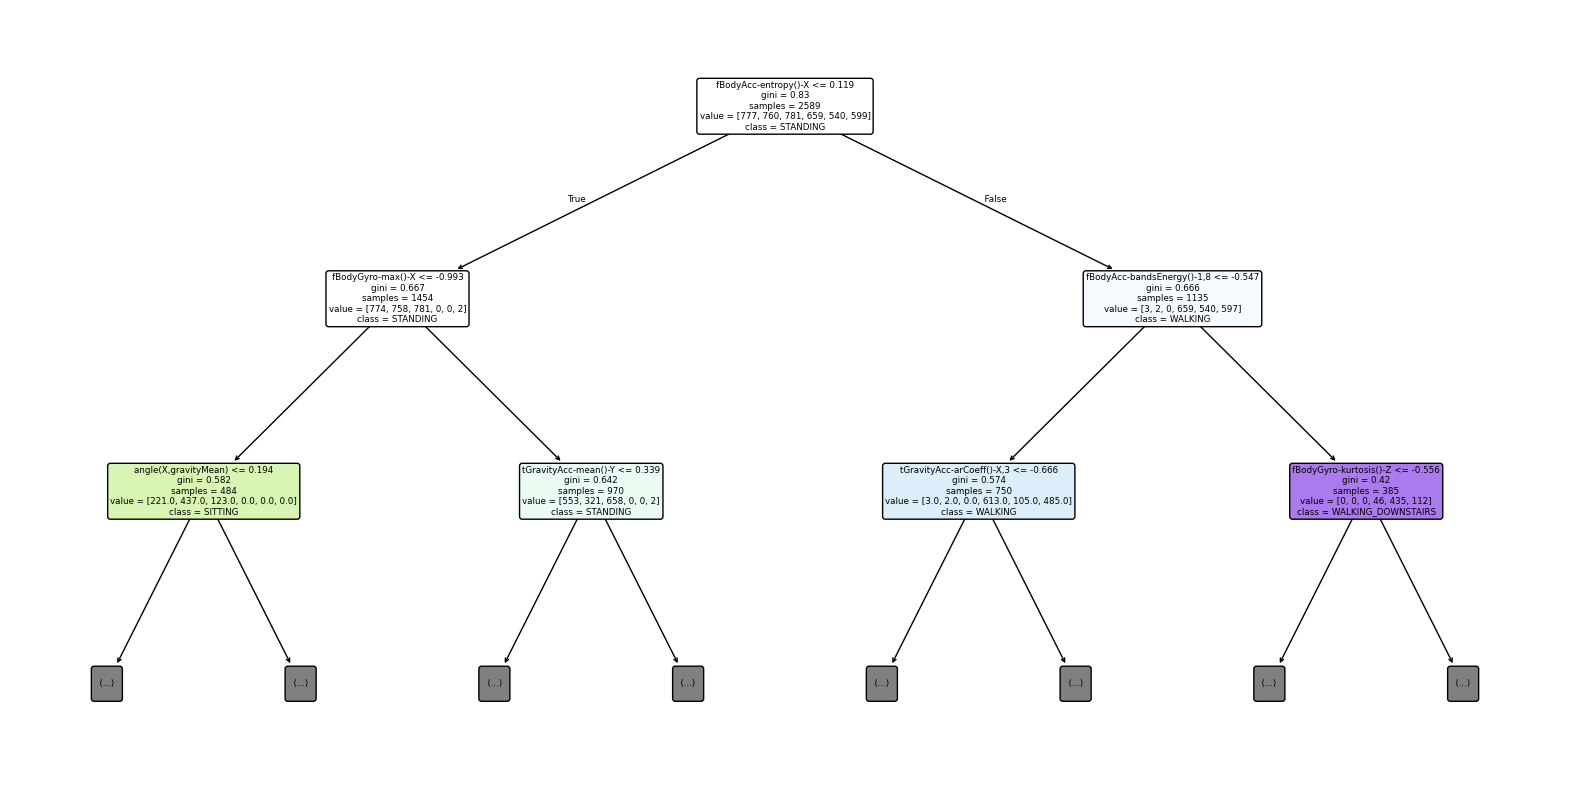

In [25]:
plt.figure(figsize=(20, 10))
plot_tree(model_01.estimators_[0], filled=True, rounded=True,
          feature_names=x_train.columns, class_names=model_01.classes_.astype(str), max_depth=2)
plt.show()

#### 3) 변수 중요도 추출

In [26]:
# 변수 중요도 추출
r1 = plot_feature_importance(model_01.feature_importances_, list(x_train), False)
r1

Output hidden; open in https://colab.research.google.com to view.

#### 4) feature importance 데이터 가져오기
위 모델링을 통해 생성한 feature별 중요도 데이터를 제공해 드립니다. random forest 모델링이 너무 어렵다면, 해당 데이터를 활용해도 무방합니다.

In [27]:
#fi_analysis 데이터 불러오기
# data_path = "./fi_analysis.csv"
# fi_analysis = pd.read_csv(data_path)
# r0 = fi_analysis.filter(items=['feature_name','fi_all'])
# r0.rename(columns={'fi_all':'feature_importance'}, inplace=True)
# r0.sort_values(by=['feature_importance'], axis=0, ascending=False)

### (2) 중요도 기반 feature 분석

* **세부 요구사항**
    - 상위 n, 하위 m 개의 변수를 선정
    - 선정된 변수(feature)와 target 간의 관계를 kdeplot으로 그리기

In [28]:
# 중요도 상위 top5
r1.head(5)

,feature_name,feature_importance
0,tGravityAcc-mean()-X,0.033954
1,"angle(X,gravityMean)",0.030501
2,tGravityAcc-mean()-Y,0.028108
3,tGravityAcc-energy()-X,0.027765
4,tGravityAcc-max()-X,0.027145


In [29]:
# 중요도 하위 top5
r1.tail(5)

,feature_name,feature_importance
556,"fBodyAccJerk-bandsEnergy()-57,64.2",0.000076
557,fBodyAcc-maxInds-Z,0.000076
558,"fBodyAccJerk-bandsEnergy()-49,64",0.000064
559,fBodyBodyGyroJerkMag-entropy(),0.000063
560,"fBodyAcc-bandsEnergy()-33,48",0.000048


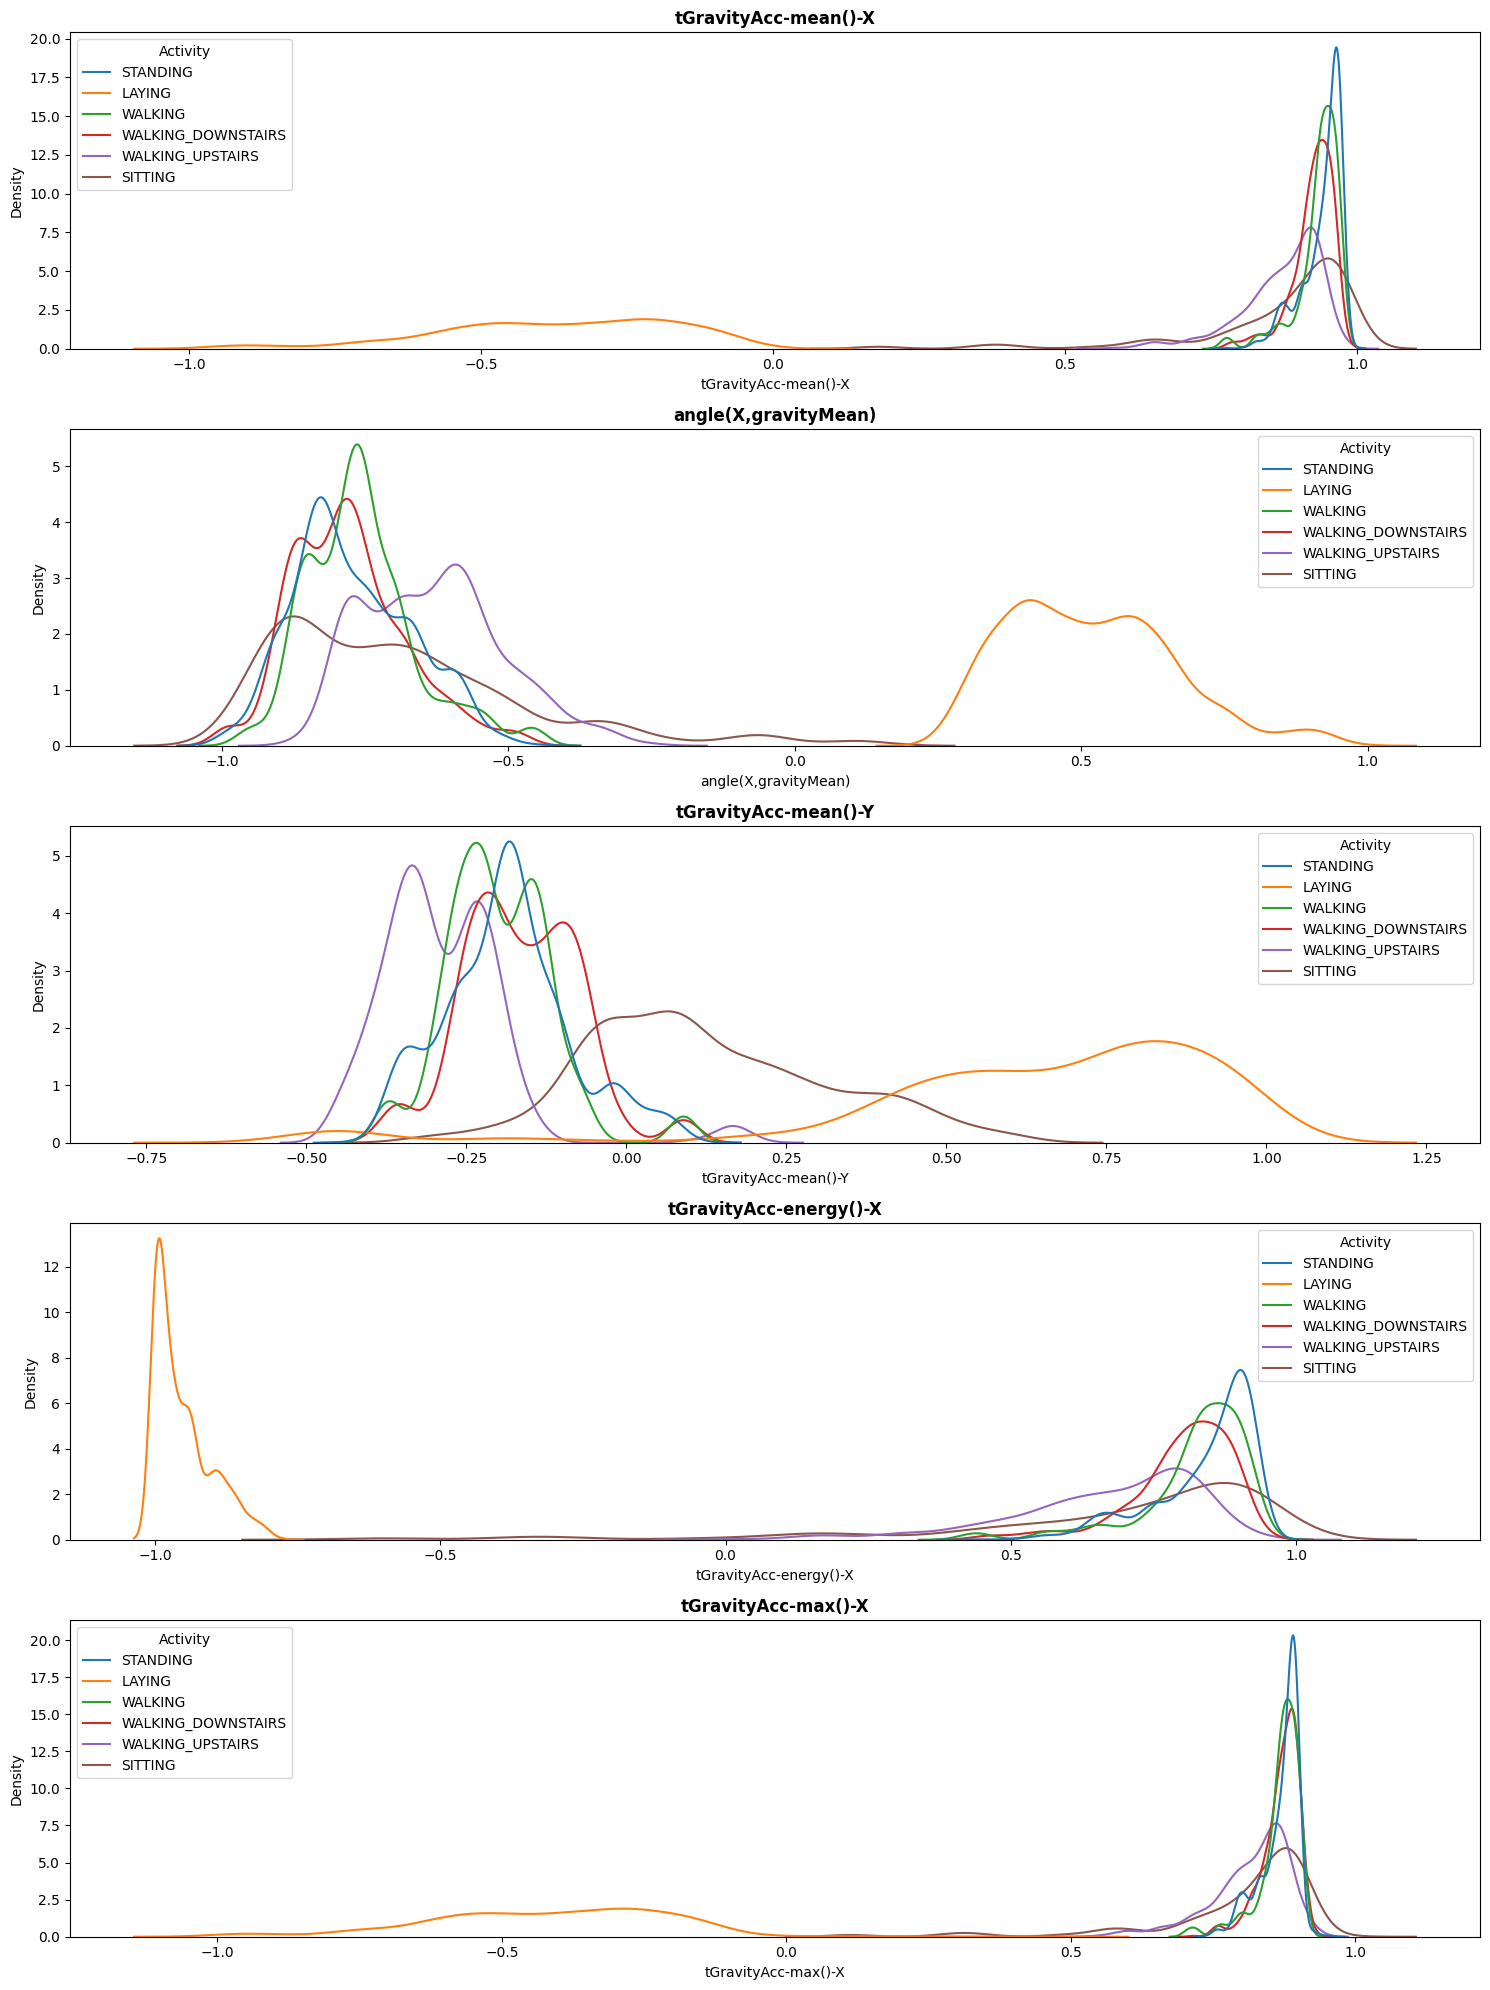

In [30]:
# 중요도 상위 5개 정보에 대한 분석
fig, ax = plt.subplots(5, figsize=(15,20))
for i in range(5):
    var = r1.iloc[i, 0]
    sns.kdeplot(x=var, data=data, hue=target, common_norm=False, ax=ax[i])
    ax[i].set_title(f'{var}', fontweight='bold')
plt.tight_layout()
plt.show()

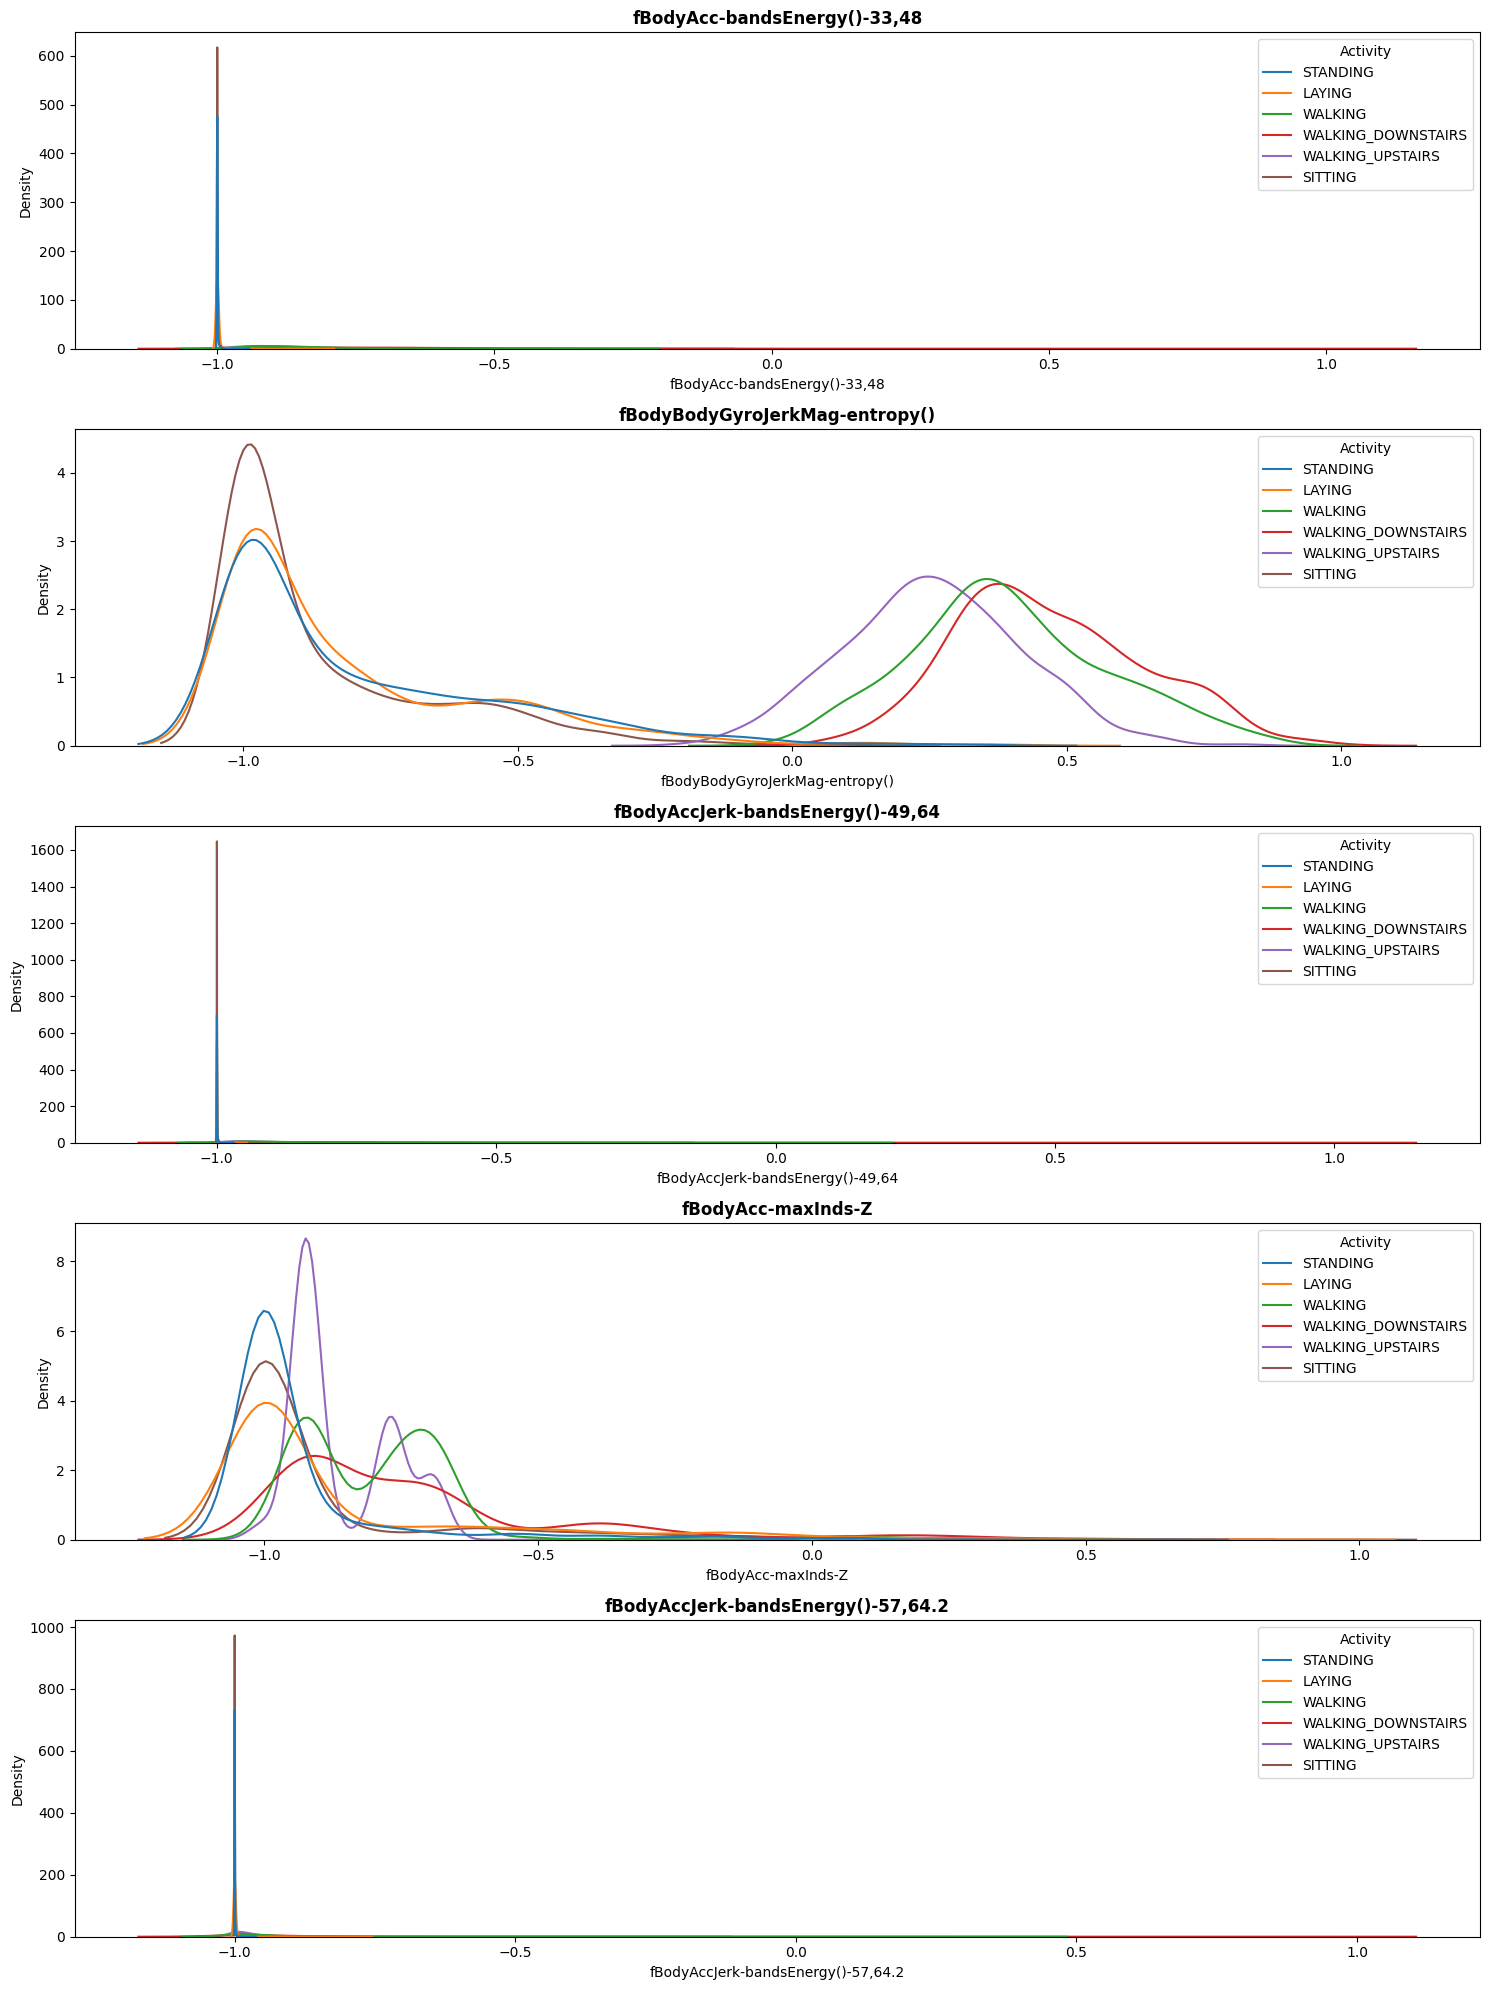

In [31]:
# 중요도 하위 5개 정보에 대한 분석
fig, ax = plt.subplots(5, figsize=(15,20))
for i in range(1,6):
    var = r1.iloc[-i, 0]
    sns.kdeplot(x=var, data=data, hue=target, common_norm=False, ax=ax[i-1])
    ax[i-1].set_title(f'{var}', fontweight='bold')

plt.tight_layout()
plt.show()

### (3) feature 그룹별 분석

* **세부 요구사항**
    - 제공된 features.csv 에는 feature에 대한 계층구조를 정리해 놓았습니다.
    - features와 변수중요도 결과를 merge 하시오.
    - sensor 별 중요도 합계를 구하고 상위 변수 그룹별 비교 분석을 수행 하시오.
    - sensor + agg 별 중요도 합계를 구하고 상위 변수 그룹별 비교 분석을 수행 하시오.


#### 1) 결과 merge

In [32]:
result = pd.merge(features, r1, how='inner', on='feature_name')
result

,sensor,agg,axis,feature_name,feature_importance
0,tBodyAcc,mean(),X,tBodyAcc-mean()-X,0.000266
1,tBodyAcc,mean(),Y,tBodyAcc-mean()-Y,0.000264
2,tBodyAcc,mean(),Z,tBodyAcc-mean()-Z,0.000279
3,tBodyAcc,std(),X,tBodyAcc-std()-X,0.003377
4,tBodyAcc,std(),Y,tBodyAcc-std()-Y,0.000393
...,...,...,...,...,...
556,angle,tBodyGyroMean,gravityMean,"angle(tBodyGyroMean,gravityMean)",0.000528
557,angle,tBodyGyroJerkMean,gravityMean,"angle(tBodyGyroJerkMean,gravityMean)",0.000538
558,angle,X,gravityMean,"angle(X,gravityMean)",0.030501
559,angle,Y,gravityMean,"angle(Y,gravityMean)",0.021600


#### 2) sensor 별 중요도

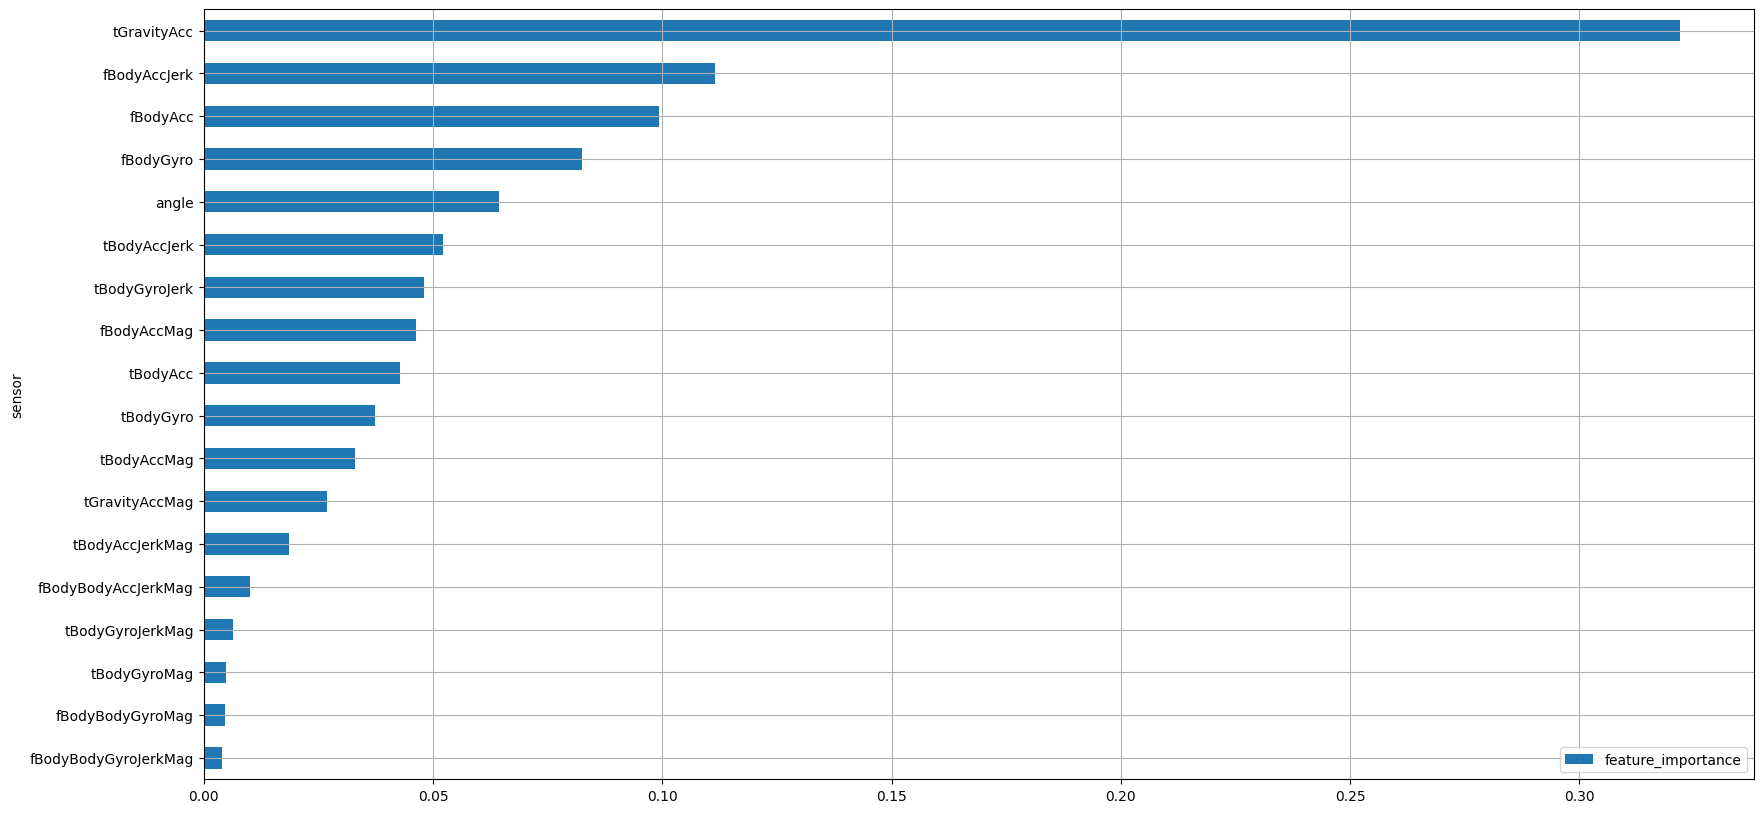

In [33]:
result.groupby('sensor')[['feature_importance']].sum().sort_values('feature_importance').plot.barh(figsize=(20,10))
plt.grid()
plt.show()

#### 3) sensor + agg 별 중요도

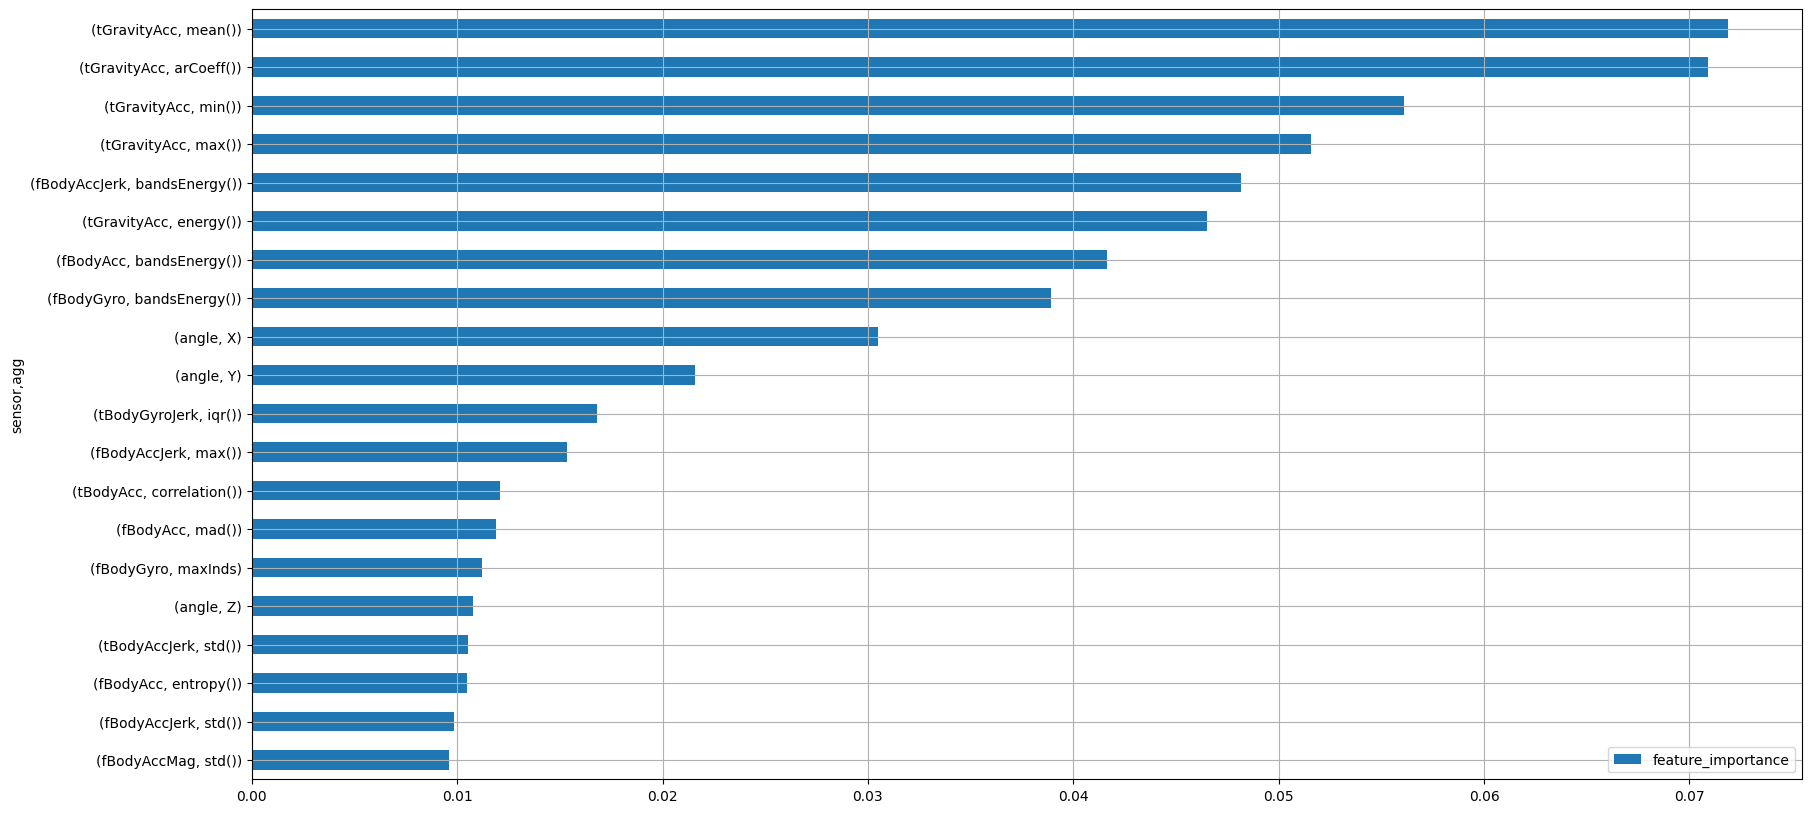

In [34]:
temp = result.groupby(['sensor', 'agg'])[['feature_importance']].sum().sort_values('feature_importance')
temp.tail(20).plot.barh(figsize=(20,10))
plt.grid()
plt.show()

#### 3-1) sensor 별, agg로 나눠서 분석하기


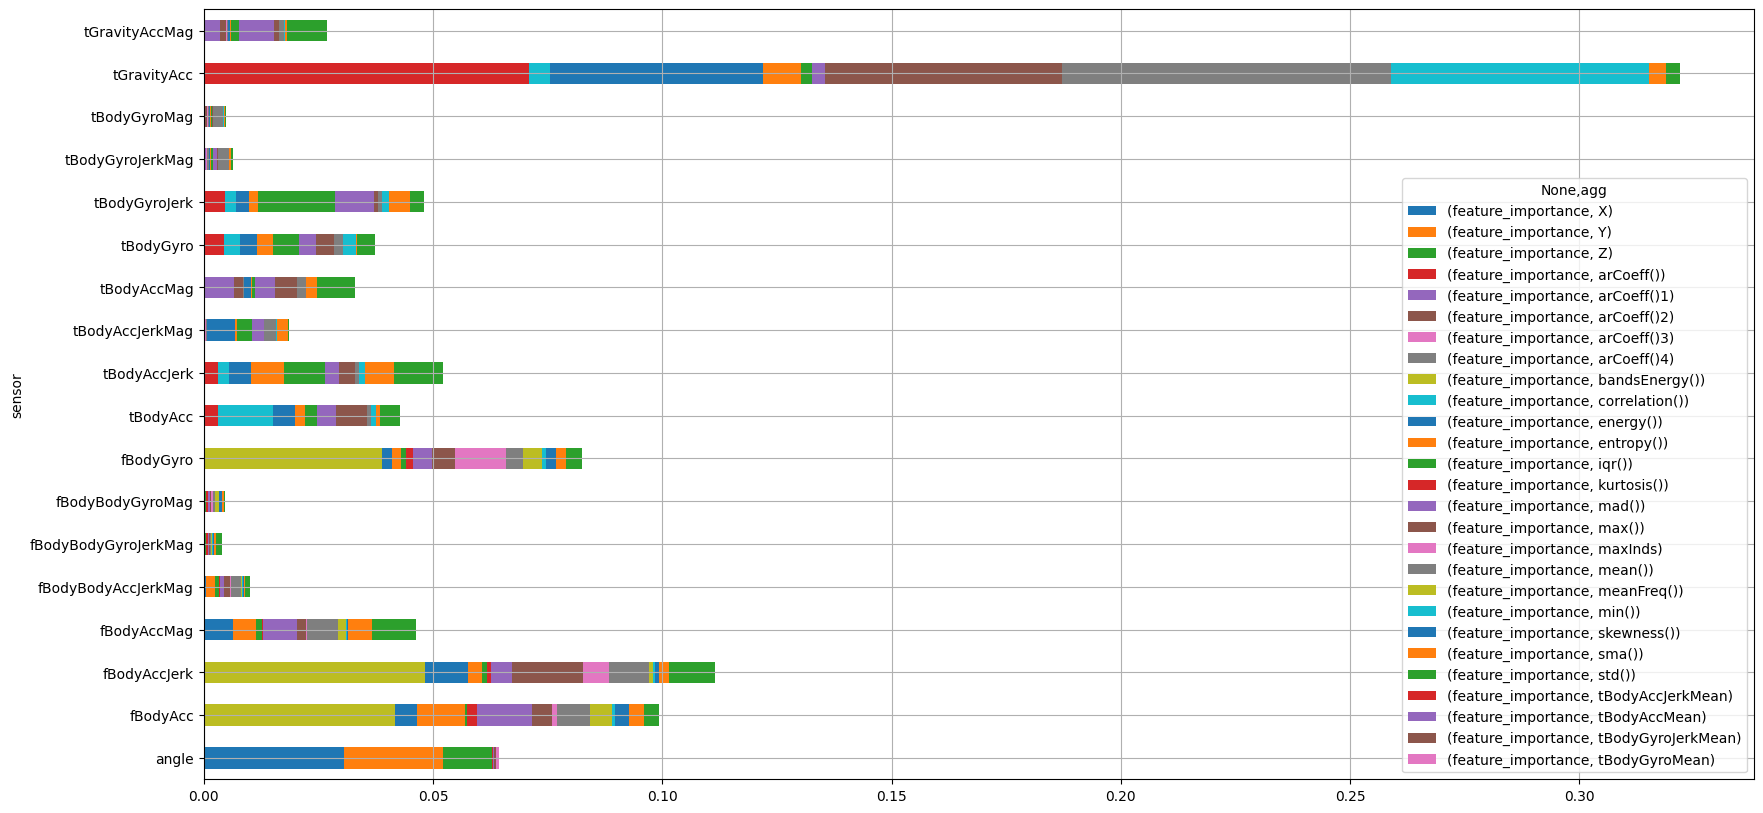

In [35]:
result.groupby(['sensor', 'agg'])[['feature_importance']].sum().unstack().plot(kind='barh', stacked=True, figsize=(20,10))
plt.grid()
plt.show()

In [36]:
# 중요도 상위 변수 몇개만 가지고 다시 모델링

# 데이터 분할을 위한 전처리
target = 'Activity'
non_feature_list.append(target)

x = data[r1.iloc[:10, 0]]
y = data.loc[:, target]

x_train, x_val, y_train, y_val = train_test_split(x, y, test_size = .3, random_state=42)

#생성
model_01 = RandomForestClassifier(random_state=42)

#학습
model_01.fit(x_train, y_train)
pred = model_01.predict(x_val)

#평가
print('accuracy :',accuracy_score(y_val, pred))
print('='*60)
print(confusion_matrix(y_val, pred))
print('='*60)
print(classification_report(y_val, pred))

accuracy : 0.9393767705382436
[[334   0   0   0   0   0]
 [  0 302   8   0   0   0]
 [  0  21 292   0   0   0]
 [  0   0   0 270  15   7]
 [  0   0   0  18 201  20]
 [  0   0   2   6  10 259]]
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       334
           SITTING       0.93      0.97      0.95       310
          STANDING       0.97      0.93      0.95       313
           WALKING       0.92      0.92      0.92       292
WALKING_DOWNSTAIRS       0.89      0.84      0.86       239
  WALKING_UPSTAIRS       0.91      0.94      0.92       277

          accuracy                           0.94      1765
         macro avg       0.94      0.93      0.93      1765
      weighted avg       0.94      0.94      0.94      1765



## 4.데이터 분석 : 미션2

다음의 case에 맞게 feature 및 feature 그룹 중요도를 기반으로 탐색적 데이터 분석을 수행하시오.
* 1) Target을 **정적/동적 행동**으로 구분
    * 6개의 행동은 2개의 그룹(정적행동, 동적행동)으로 나뉩니다.  
    * 어떤 feature(혹은 feature 그룹)이 2개 class 그룹(정적행동, 동적행동)를 구분하는데 중요한지를 찾아보고 탐색해봅시다.
* 2) Target을 **개별 행동 여부**로 구분
    * 6가지의 행동을 분류하는 분석도 중요하지만, 개별 행동에만 특별히 영향을 받는 feature들도 있습니다.
    * 예를 들어, 계단을 오르는 행동(Walking_upstairs)과 관련이 큰 feature가 있을 것입니다. [계단을 오르는 행동]인지 아닌지로 구분하는 targe을 추가하여 EDA를 수행해 봅시다.

### (1) 정적/동적 행동으로 구분하여 분석하기

* **세부 요구사항**
    - Target인 Activity를 is_dynamic 변수로 변경하시오.
        * 값 0 : STANDING, SITTING, LAYING
        * 값 1 : WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS
    - is_dynamic을 예측하기 위한 기본 모델을 생성하시오.
        * x, is_dynamic을 이용하여 train과 validation으로 데이터 분할
        * 기본 모델링
    - is_dynamic 을 구분하는데 중요한 변수 상위 5를 분석하시오.
    - is_dynamic 을 구분하는데 중요한 변수 그룹을 분석하시오.
        * sensor별
        * sensor+agg 별


#### 1) is_dynamic 추가 (옵션)

In [37]:
dynamic_dict = {
    'STANDING': 0,
    'SITTING': 0,
    'LAYING': 0,
    'WALKING': 1,
    'WALKING_UPSTAIRS': 1,
    'WALKING_DOWNSTAIRS': 1
}

In [38]:
data['is_dynamic'] = data['Activity'].map(dynamic_dict)
data

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity,is_dynamic
0,0.288508,-0.009196,-0.103362,-0.988986,-0.962797,-0.967422,-0.989000,-0.962596,-0.965650,-0.929747,...,-0.816696,-0.042494,-0.044218,0.307873,0.072790,-0.601120,0.331298,0.165163,STANDING,0
1,0.265757,-0.016576,-0.098163,-0.989551,-0.994636,-0.987435,-0.990189,-0.993870,-0.987558,-0.937337,...,-0.693515,-0.062899,0.388459,-0.765014,0.771524,0.345205,-0.769186,-0.147944,LAYING,0
2,0.278709,-0.014511,-0.108717,-0.997720,-0.981088,-0.994008,-0.997934,-0.982187,-0.995017,-0.942584,...,-0.829311,0.000265,-0.525022,-0.891875,0.021528,-0.833564,0.202434,-0.032755,STANDING,0
3,0.289795,-0.035536,-0.150354,-0.231727,-0.006412,-0.338117,-0.273557,0.014245,-0.347916,0.008288,...,-0.408956,-0.255125,0.612804,0.747381,-0.072944,-0.695819,0.287154,0.111388,WALKING,1
4,0.394807,0.034098,0.091229,0.088489,-0.106636,-0.388502,-0.010469,-0.109680,-0.346372,0.584131,...,-0.563437,-0.044344,-0.845268,-0.974650,-0.887846,-0.705029,0.264952,0.137758,WALKING_DOWNSTAIRS,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5876,0.277194,-0.012389,-0.131974,-0.994046,-0.940578,-0.917337,-0.994261,-0.932830,-0.908088,-0.936219,...,-0.690363,-0.034888,-0.261437,-0.391477,-0.877612,-0.912365,0.114009,0.080146,SITTING,0
5877,0.191568,0.013328,-0.105174,-0.126969,-0.121729,-0.327480,-0.192523,-0.109923,-0.295286,0.078644,...,-0.879215,0.721718,0.623151,0.866858,-0.445660,-0.690278,0.303194,-0.044188,WALKING_UPSTAIRS,1
5878,0.267981,-0.018348,-0.107440,-0.991303,-0.989881,-0.990313,-0.992386,-0.988852,-0.991237,-0.936099,...,-0.886851,0.060173,0.228739,0.684400,-0.216665,0.620363,-0.437247,-0.571840,LAYING,0
5879,0.212787,-0.048130,-0.121001,-0.041373,0.052449,-0.585361,-0.100714,0.023353,-0.554707,0.219814,...,-0.053556,0.260880,0.551742,-0.943773,-0.862899,-0.718009,0.292856,0.024920,WALKING_UPSTAIRS,1


#### 2) 기본모델 생성 (옵션)

In [39]:
# 데이터 분할을 위한 전처리
target = 'is_dynamic'
non_feature_list.append(target)

x = data.drop(non_feature_list, axis = 1)
y = data.loc[:, target]

x_train, x_val, y_train, y_val = train_test_split(x, y, test_size = .3, random_state=42)

In [40]:
#생성
model_02 = RandomForestClassifier(random_state=42)

#학습
model_02.fit(x_train, y_train)
pred = model_02.predict(x_val)

#평가
print('accuracy :',accuracy_score(y_val, pred))
print('='*60)
print(confusion_matrix(y_val, pred))
print('='*60)
print(classification_report(y_val, pred))

accuracy : 1.0
[[957   0]
 [  0 808]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       957
           1       1.00      1.00      1.00       808

    accuracy                           1.00      1765
   macro avg       1.00      1.00      1.00      1765
weighted avg       1.00      1.00      1.00      1765



#### 3) 변수중요도 상위 5개 분석 (옵션)

In [41]:
r2 = plot_feature_importance(model_02.feature_importances_, list(x_train), False)
r2

Output hidden; open in https://colab.research.google.com to view.

In [42]:
r2.head()

,feature_name,feature_importance
0,fBodyAccJerk-max()-X,0.060310
1,tBodyGyroJerk-iqr()-Z,0.059794
2,"fBodyAccJerk-bandsEnergy()-1,16",0.050049
3,tBodyAccJerk-std()-X,0.050000
4,fBodyAcc-entropy()-X,0.049745


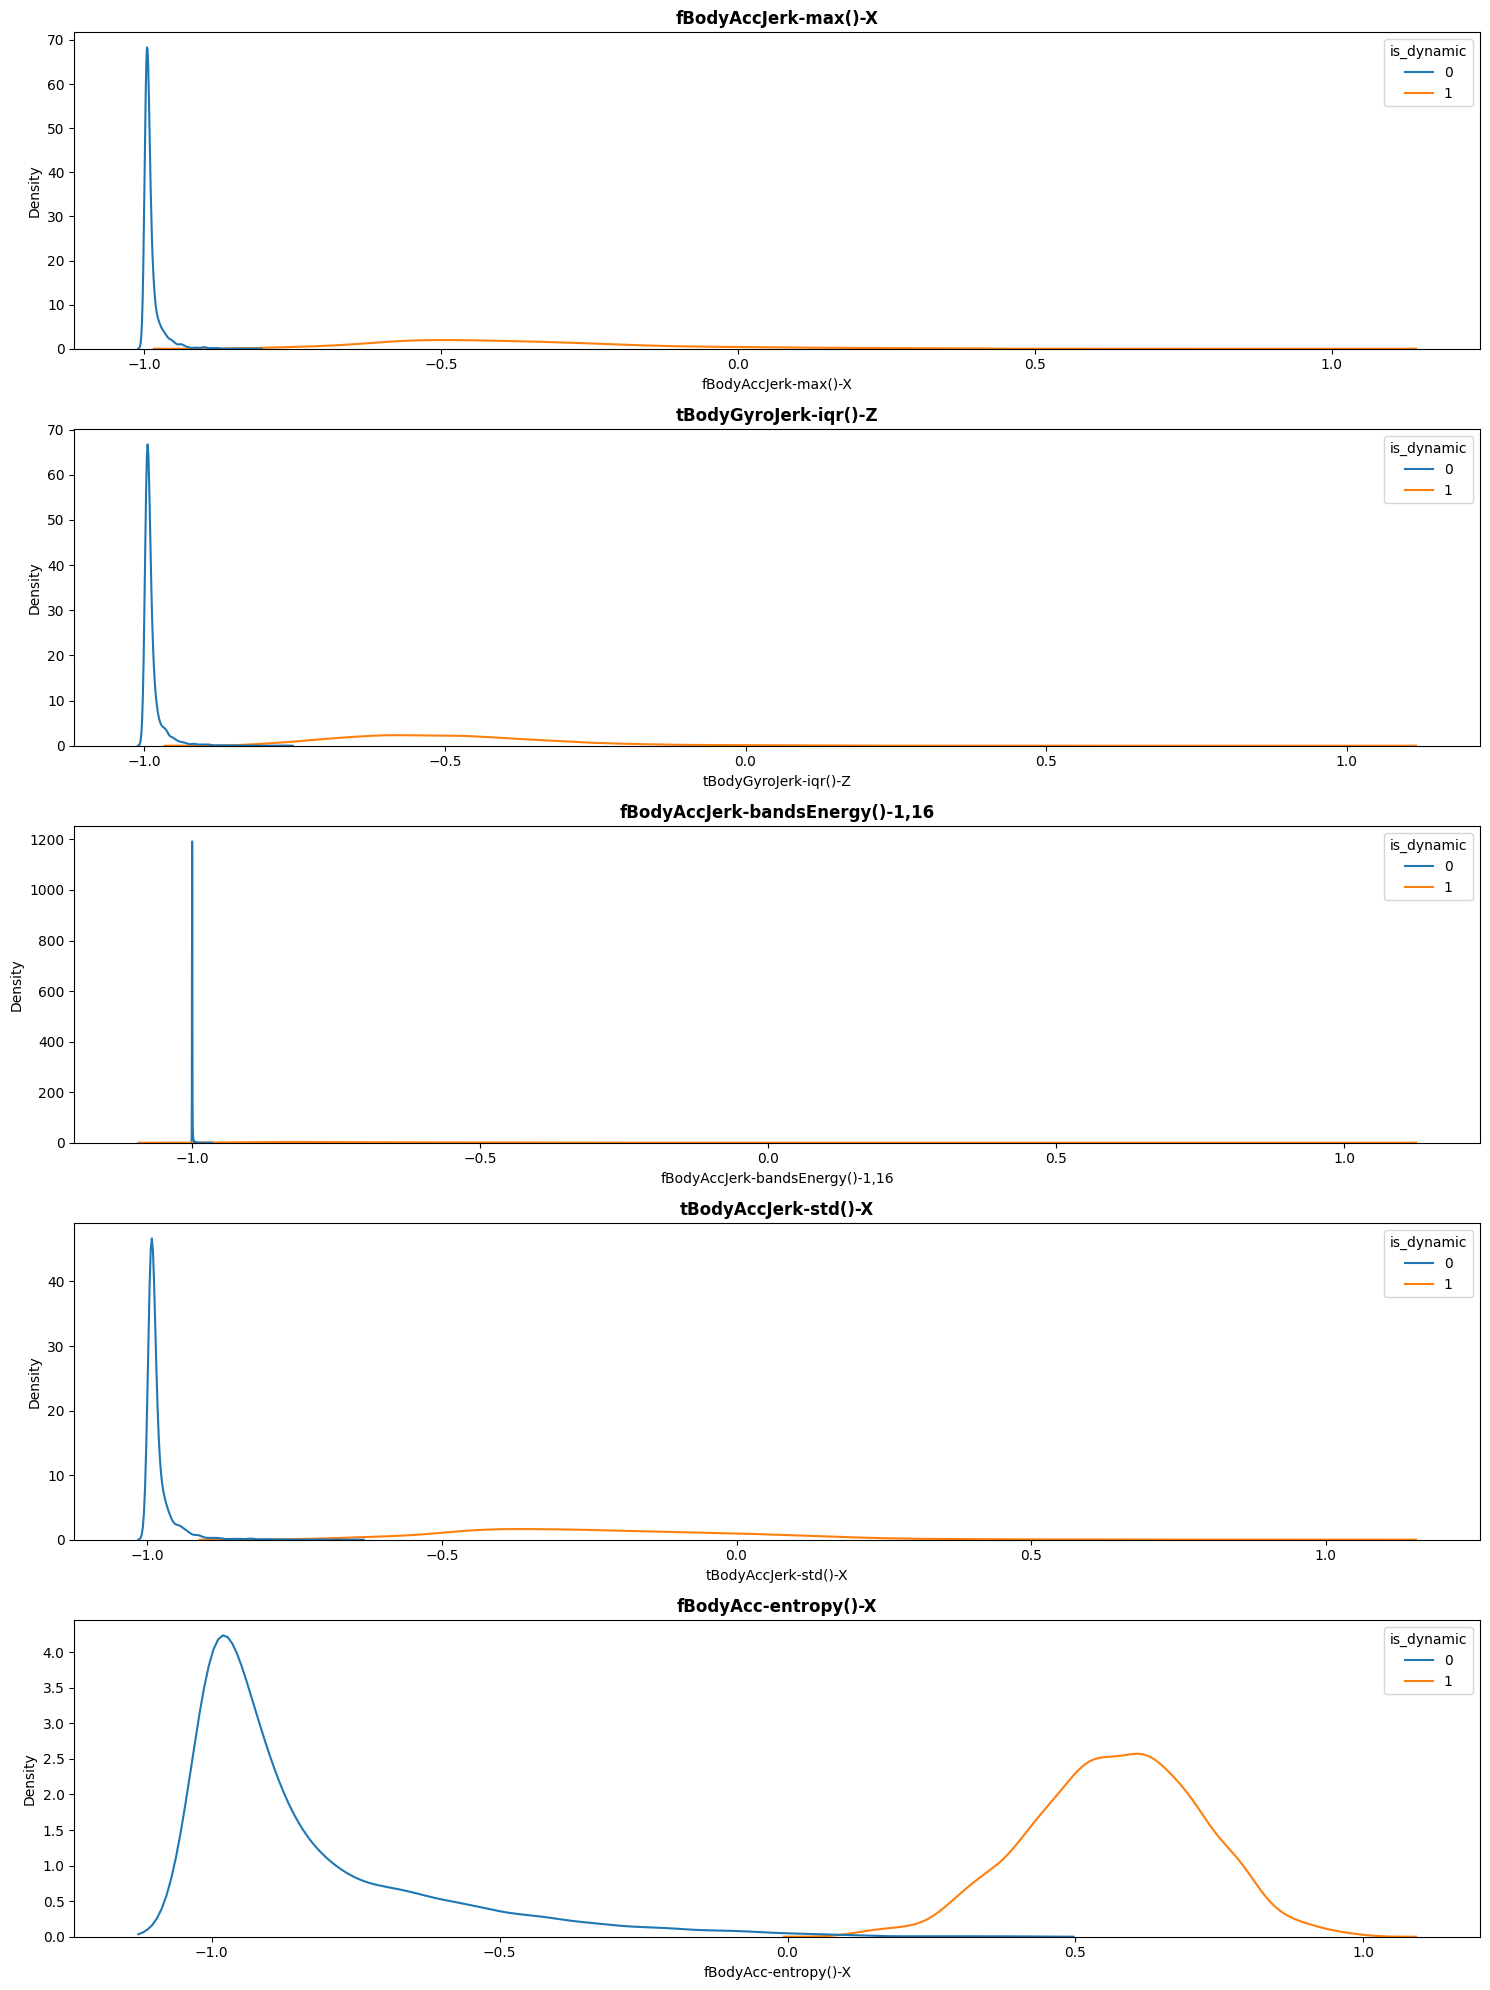

In [43]:
# 중요도 상위 5개 정보에 대한 분석
fig, ax = plt.subplots(5, figsize=(15,20))
for i in range(5):
    var = r2.iloc[i, 0]
    sns.kdeplot(x=var, data=data, hue=target, common_norm=False, ax=ax[i])
    ax[i].set_title(f'{var}', fontweight='bold')
plt.tight_layout()
plt.show()

#### 데이터 가져오기로 1), 2), 3) 대체 가능

In [44]:
#fi_analysis 데이터 불러오기
#data_path = "./fi_analysis.csv"
#fi_analysis = pd.read_csv(data_path)
#r_dyn = fi_analysis.filter(items=['feature_name','fi_all'])
#r_dyn.rename(columns={'fi_dynamic':'feature_importance'}, inplace=True)
#r_dyn.sort_values(by=['feature_importance'], axis=0, ascending=False)

#### 4) feature 그룹별 분석

In [45]:
is_dynamic_result = pd.merge(features, r2, how='inner', on='feature_name')
is_dynamic_result

,sensor,agg,axis,feature_name,feature_importance
0,tBodyAcc,mean(),X,tBodyAcc-mean()-X,0.000029
1,tBodyAcc,mean(),Y,tBodyAcc-mean()-Y,0.000035
2,tBodyAcc,mean(),Z,tBodyAcc-mean()-Z,0.000030
3,tBodyAcc,std(),X,tBodyAcc-std()-X,0.000098
4,tBodyAcc,std(),Y,tBodyAcc-std()-Y,0.000038
...,...,...,...,...,...
556,angle,tBodyGyroMean,gravityMean,"angle(tBodyGyroMean,gravityMean)",0.000000
557,angle,tBodyGyroJerkMean,gravityMean,"angle(tBodyGyroJerkMean,gravityMean)",0.000000
558,angle,X,gravityMean,"angle(X,gravityMean)",0.000166
559,angle,Y,gravityMean,"angle(Y,gravityMean)",0.000000


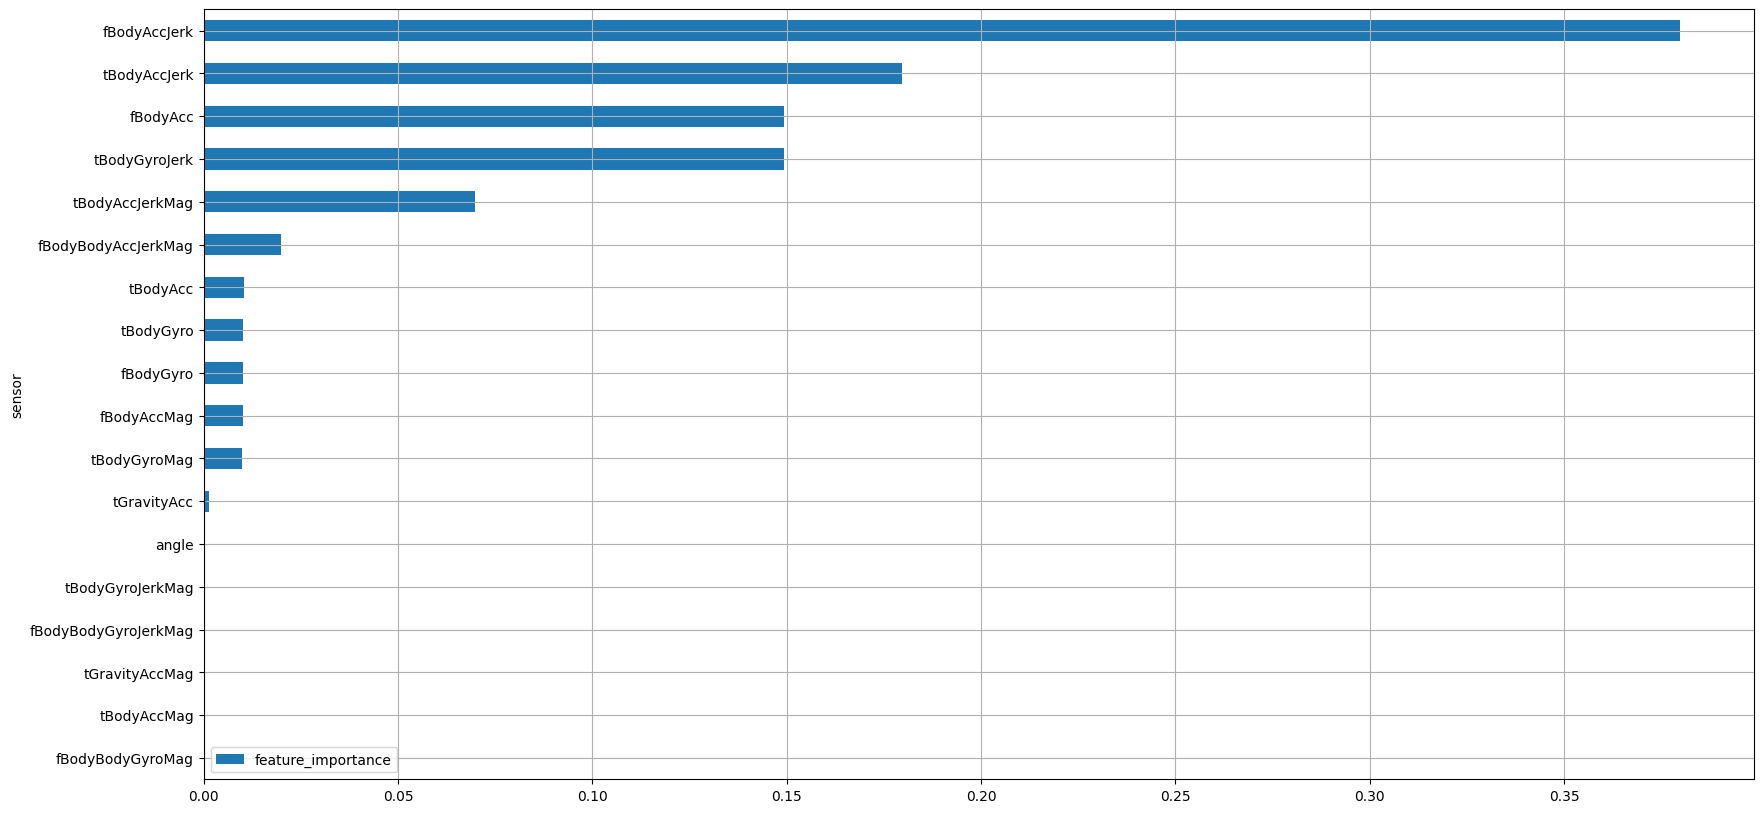

In [46]:
is_dynamic_result.groupby('sensor')[['feature_importance']].sum().sort_values('feature_importance').plot.barh(figsize=(20,10))
plt.grid()
plt.show()

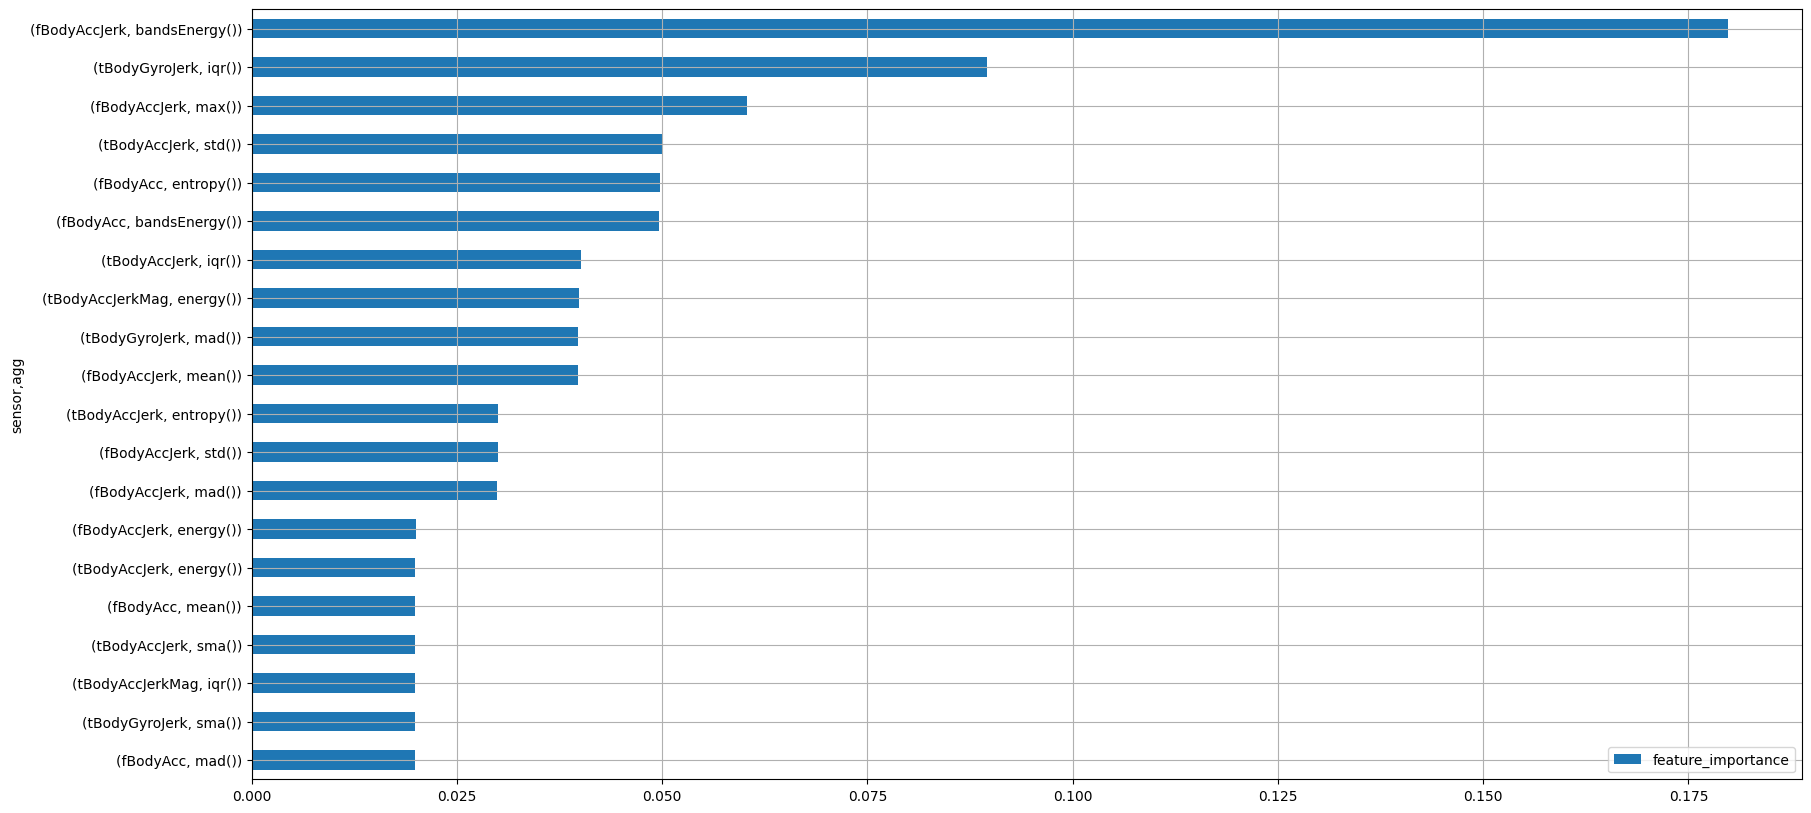

In [47]:
temp = is_dynamic_result.groupby(['sensor', 'agg'])[['feature_importance']].sum().sort_values('feature_importance')
temp.tail(20).plot.barh(figsize=(20,10))
plt.grid()
plt.show()

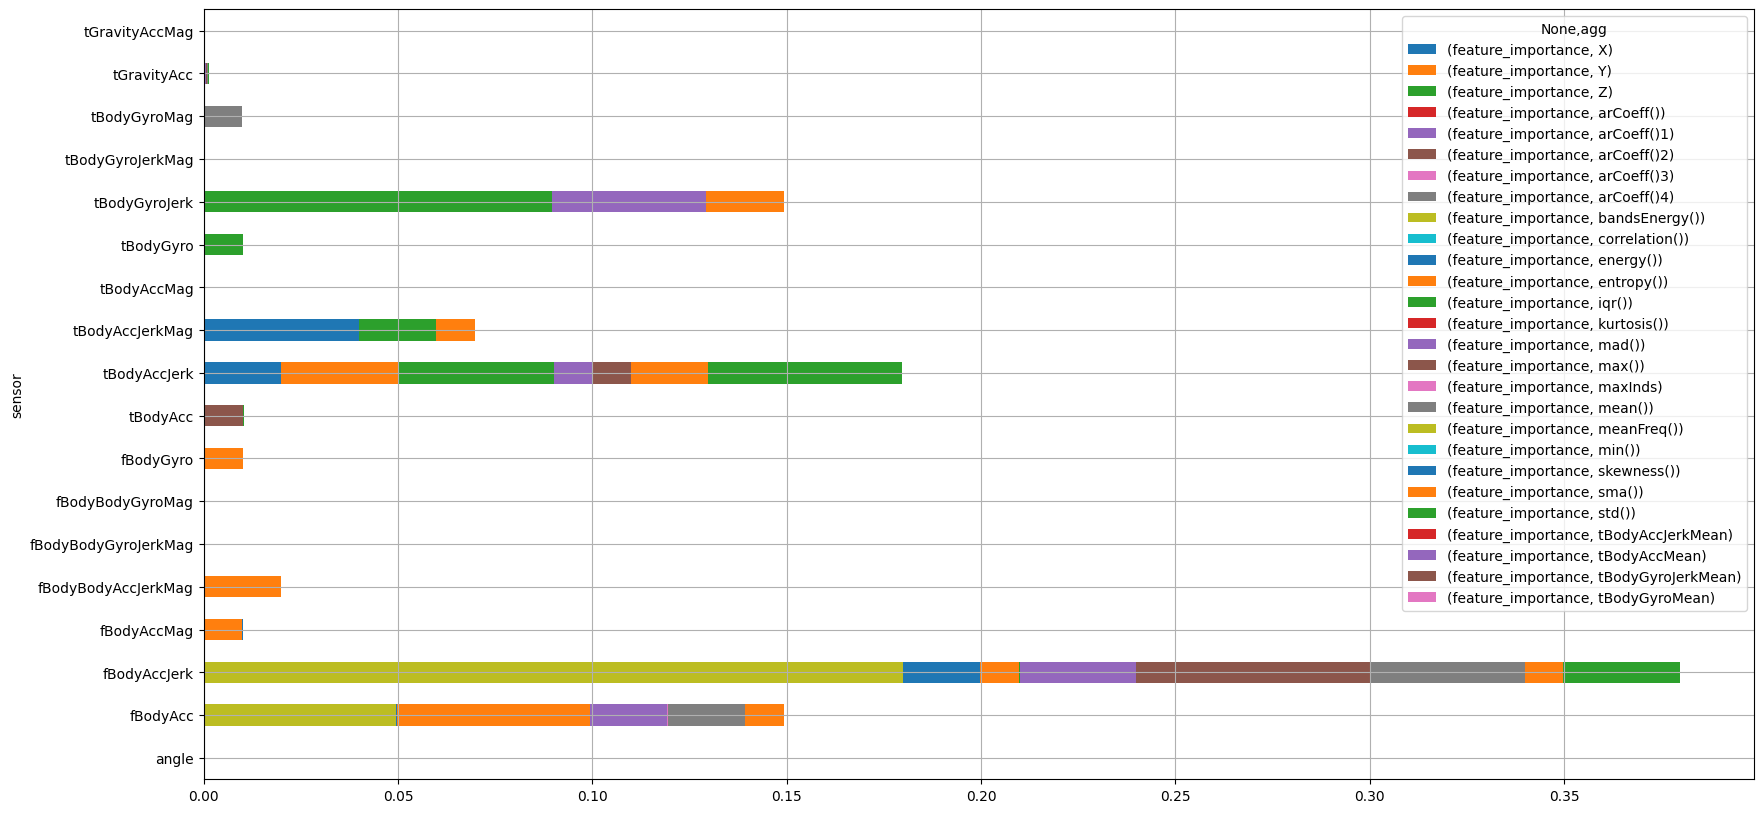

In [48]:
is_dynamic_result.groupby(['sensor', 'agg'])[['feature_importance']].sum().unstack().plot(kind='barh', stacked=True, figsize=(20,10))
plt.grid()
plt.show()

In [49]:
# 중요도 상위 변수 몇개만 가지고 다시 모델링

# 데이터 분할을 위한 전처리
target = 'is_dynamic'
non_feature_list.append(target)

x = data[r2.iloc[:10, 0]]
y = data.loc[:, target]

x_train, x_val, y_train, y_val = train_test_split(x, y, test_size = .3, random_state=42)

#생성
model_02 = RandomForestClassifier(random_state=42)

#학습
model_02.fit(x_train, y_train)
pred = model_02.predict(x_val)

#평가
print('accuracy :',accuracy_score(y_val, pred))
print('='*60)
print(confusion_matrix(y_val, pred))
print('='*60)
print(classification_report(y_val, pred))

accuracy : 0.9988668555240793
[[957   0]
 [  2 806]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       957
           1       1.00      1.00      1.00       808

    accuracy                           1.00      1765
   macro avg       1.00      1.00      1.00      1765
weighted avg       1.00      1.00      1.00      1765



### (2) 개별 동작 분석 : is_standing


* **세부 요구사항**
    - Target인 Activity를 is_standing 변수로 변경하시오.
        * 값 1 : STANDING
        * 값 0 : 나머지
    - is_standing 을 예측하기 위한 기본 모델을 생성하시오.
        * x, is_standing 을 이용하여 train과 validation으로 데이터 분할
        * 기본 모델링
    - is_standing 을 구분하는데 중요한 변수 상위 5를 분석하시오.
    - is_standing 을 구분하는데 중요한 변수 그룹을 분석하시오.
        * sensor별
        * sensor+agg 별


1) is_standing 추가

In [50]:
data['is_standing'] = data['Activity'].map(lambda x: 1 if x == 'STANDING' else 0)
data

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity,is_dynamic,is_standing
0,0.288508,-0.009196,-0.103362,-0.988986,-0.962797,-0.967422,-0.989000,-0.962596,-0.965650,-0.929747,...,-0.042494,-0.044218,0.307873,0.072790,-0.601120,0.331298,0.165163,STANDING,0,1
1,0.265757,-0.016576,-0.098163,-0.989551,-0.994636,-0.987435,-0.990189,-0.993870,-0.987558,-0.937337,...,-0.062899,0.388459,-0.765014,0.771524,0.345205,-0.769186,-0.147944,LAYING,0,0
2,0.278709,-0.014511,-0.108717,-0.997720,-0.981088,-0.994008,-0.997934,-0.982187,-0.995017,-0.942584,...,0.000265,-0.525022,-0.891875,0.021528,-0.833564,0.202434,-0.032755,STANDING,0,1
3,0.289795,-0.035536,-0.150354,-0.231727,-0.006412,-0.338117,-0.273557,0.014245,-0.347916,0.008288,...,-0.255125,0.612804,0.747381,-0.072944,-0.695819,0.287154,0.111388,WALKING,1,0
4,0.394807,0.034098,0.091229,0.088489,-0.106636,-0.388502,-0.010469,-0.109680,-0.346372,0.584131,...,-0.044344,-0.845268,-0.974650,-0.887846,-0.705029,0.264952,0.137758,WALKING_DOWNSTAIRS,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5876,0.277194,-0.012389,-0.131974,-0.994046,-0.940578,-0.917337,-0.994261,-0.932830,-0.908088,-0.936219,...,-0.034888,-0.261437,-0.391477,-0.877612,-0.912365,0.114009,0.080146,SITTING,0,0
5877,0.191568,0.013328,-0.105174,-0.126969,-0.121729,-0.327480,-0.192523,-0.109923,-0.295286,0.078644,...,0.721718,0.623151,0.866858,-0.445660,-0.690278,0.303194,-0.044188,WALKING_UPSTAIRS,1,0
5878,0.267981,-0.018348,-0.107440,-0.991303,-0.989881,-0.990313,-0.992386,-0.988852,-0.991237,-0.936099,...,0.060173,0.228739,0.684400,-0.216665,0.620363,-0.437247,-0.571840,LAYING,0,0
5879,0.212787,-0.048130,-0.121001,-0.041373,0.052449,-0.585361,-0.100714,0.023353,-0.554707,0.219814,...,0.260880,0.551742,-0.943773,-0.862899,-0.718009,0.292856,0.024920,WALKING_UPSTAIRS,1,0


2) 기본모델 생성

In [51]:
# 데이터 분할을 위한 전처리
target = 'is_standing'
non_feature_list.append(target)

x = data.drop(non_feature_list, axis = 1)
y = data.loc[:, target]

x_train, x_val, y_train, y_val = train_test_split(x, y, test_size = .3, random_state=42)

In [52]:
# is_standing 을 예측하기 위한 기본 모델을 생성

#생성
model_03 = RandomForestClassifier(random_state=42)

#학습
model_03.fit(x_train, y_train)
pred = model_03.predict(x_val)

#평가
print('accuracy :',accuracy_score(y_val, pred))
print('='*60)
print(confusion_matrix(y_val, pred))
print('='*60)
print(classification_report(y_val, pred))

accuracy : 0.9818696883852691
[[1445    7]
 [  25  288]]
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1452
           1       0.98      0.92      0.95       313

    accuracy                           0.98      1765
   macro avg       0.98      0.96      0.97      1765
weighted avg       0.98      0.98      0.98      1765



3) 변수중요도 상위 5개 분석

In [53]:
# is_standing 을 구분하는데 중요한 변수 상위 5를 분석
r3 = plot_feature_importance(model_03.feature_importances_, list(x_train), False)
r3

Output hidden; open in https://colab.research.google.com to view.

In [54]:
r3.head()

,feature_name,feature_importance
0,tGravityAcc-min()-Y,0.057925
1,tGravityAcc-mean()-Y,0.052878
2,"angle(Y,gravityMean)",0.052407
3,tGravityAcc-max()-Y,0.044504
4,"angle(Z,gravityMean)",0.027937


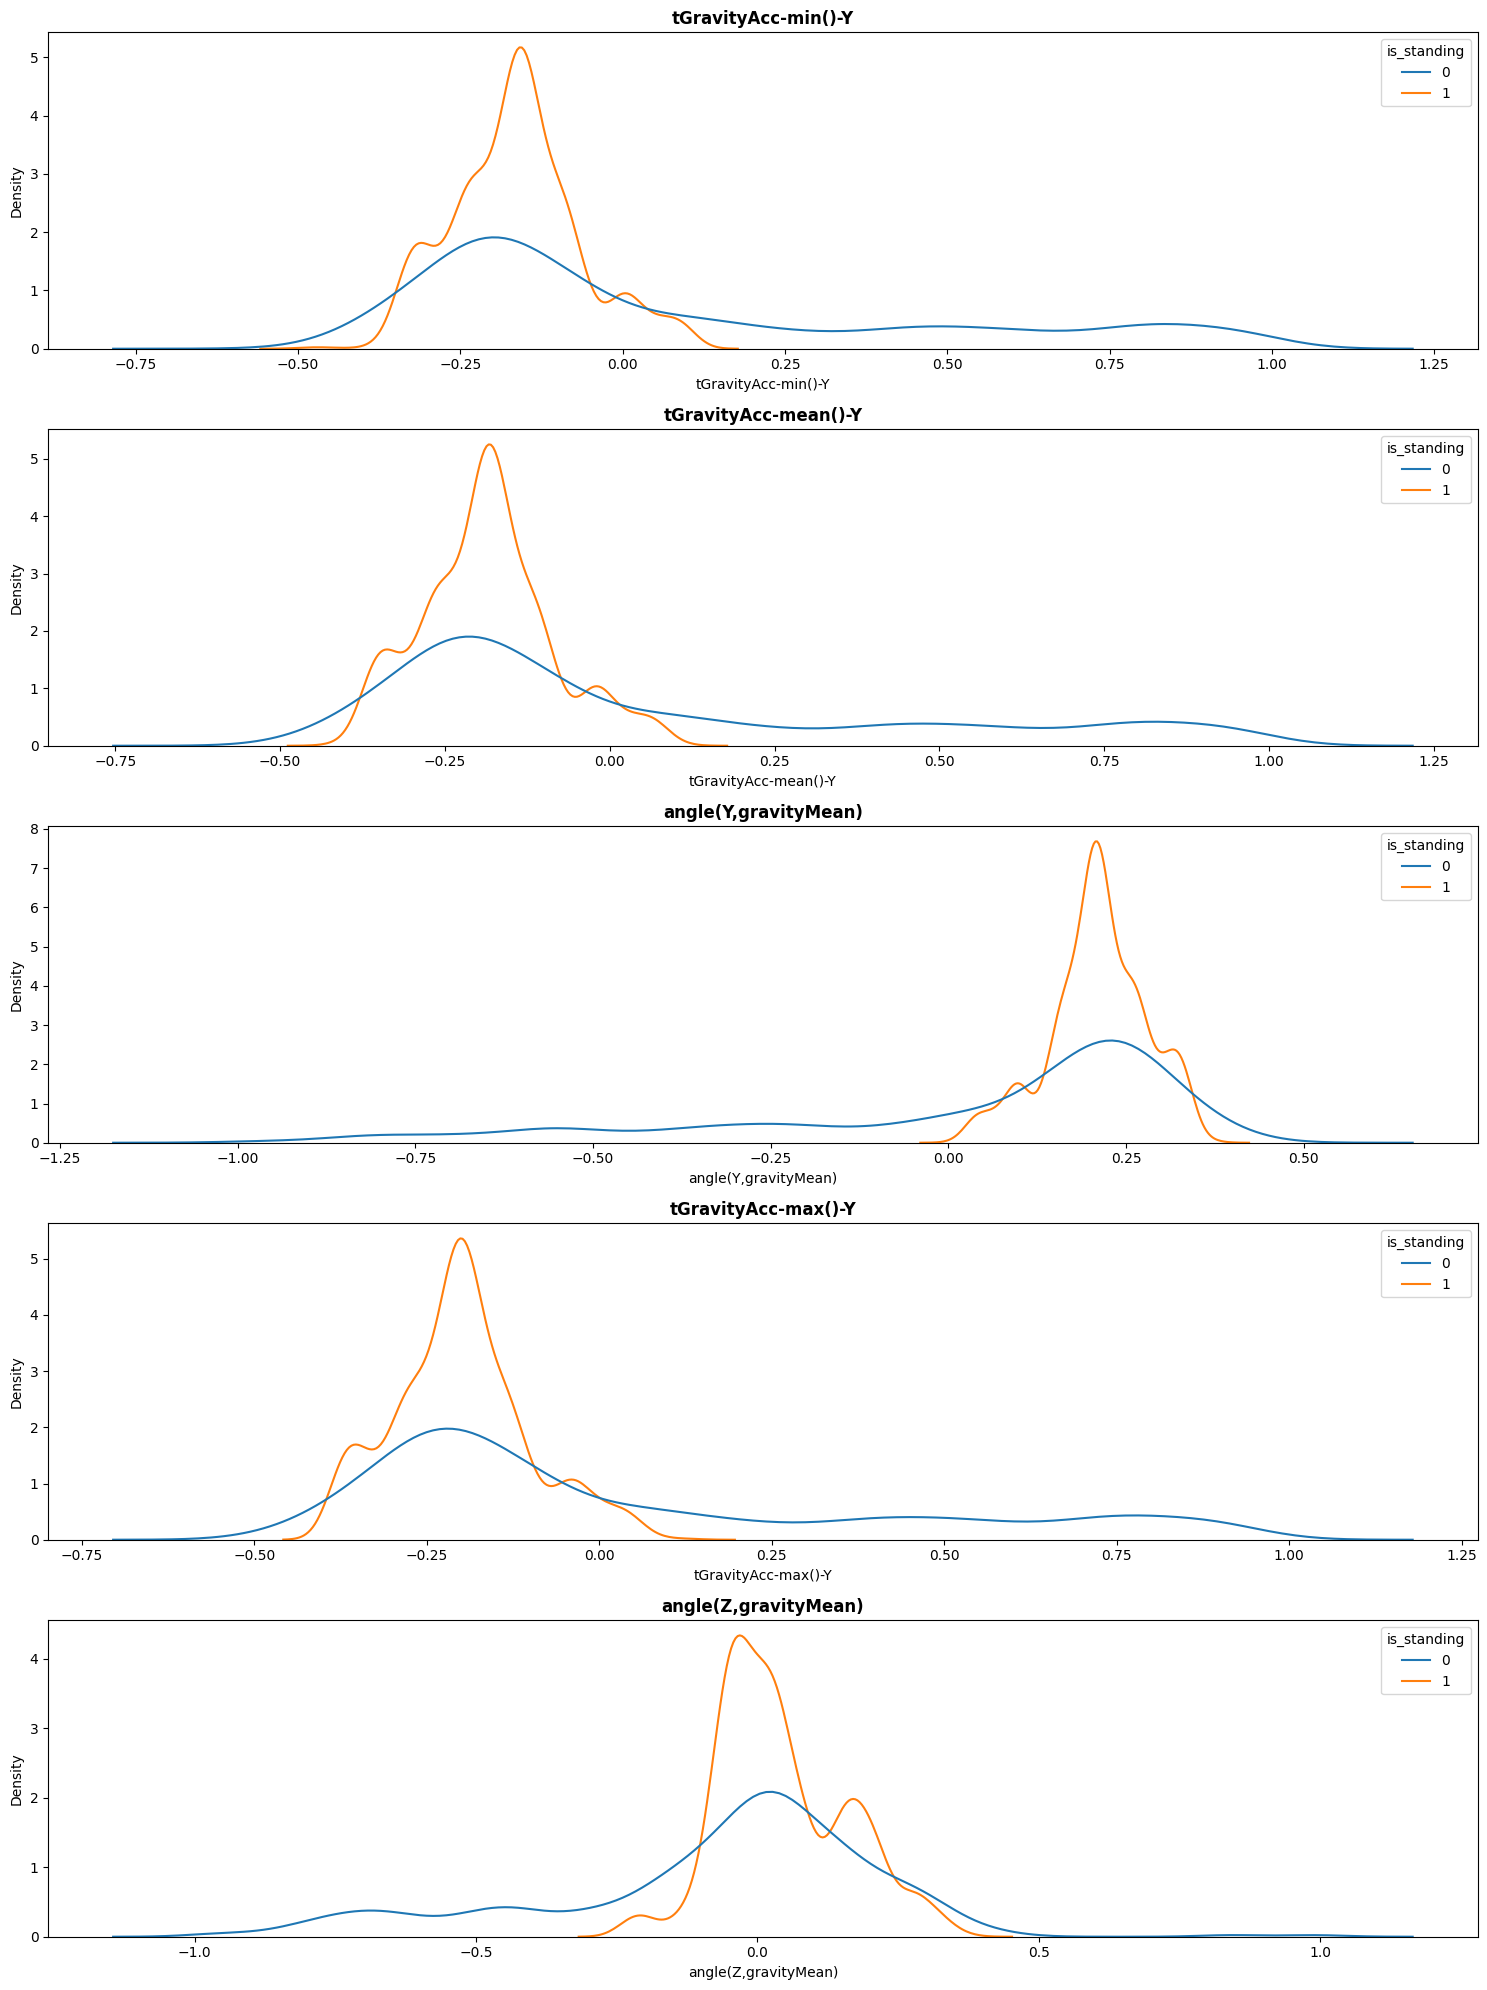

In [55]:
fig, ax = plt.subplots(5, figsize=(15,20))
for i in range(5):
    var = r3.iloc[i, 0]
    sns.kdeplot(x=var, data=data, hue=target, common_norm=False, ax=ax[i])
    ax[i].set_title(f'{var}', fontweight='bold')
plt.tight_layout()
plt.show()

4) is_standing 을 구분하는데 중요한 변수 그룹을 분석

In [56]:
is_standing_result = pd.merge(features, r3, how='inner', on='feature_name')
is_standing_result

,sensor,agg,axis,feature_name,feature_importance
0,tBodyAcc,mean(),X,tBodyAcc-mean()-X,0.000443
1,tBodyAcc,mean(),Y,tBodyAcc-mean()-Y,0.000687
2,tBodyAcc,mean(),Z,tBodyAcc-mean()-Z,0.000222
3,tBodyAcc,std(),X,tBodyAcc-std()-X,0.005230
4,tBodyAcc,std(),Y,tBodyAcc-std()-Y,0.004602
...,...,...,...,...,...
556,angle,tBodyGyroMean,gravityMean,"angle(tBodyGyroMean,gravityMean)",0.000631
557,angle,tBodyGyroJerkMean,gravityMean,"angle(tBodyGyroJerkMean,gravityMean)",0.001468
558,angle,X,gravityMean,"angle(X,gravityMean)",0.012541
559,angle,Y,gravityMean,"angle(Y,gravityMean)",0.052407


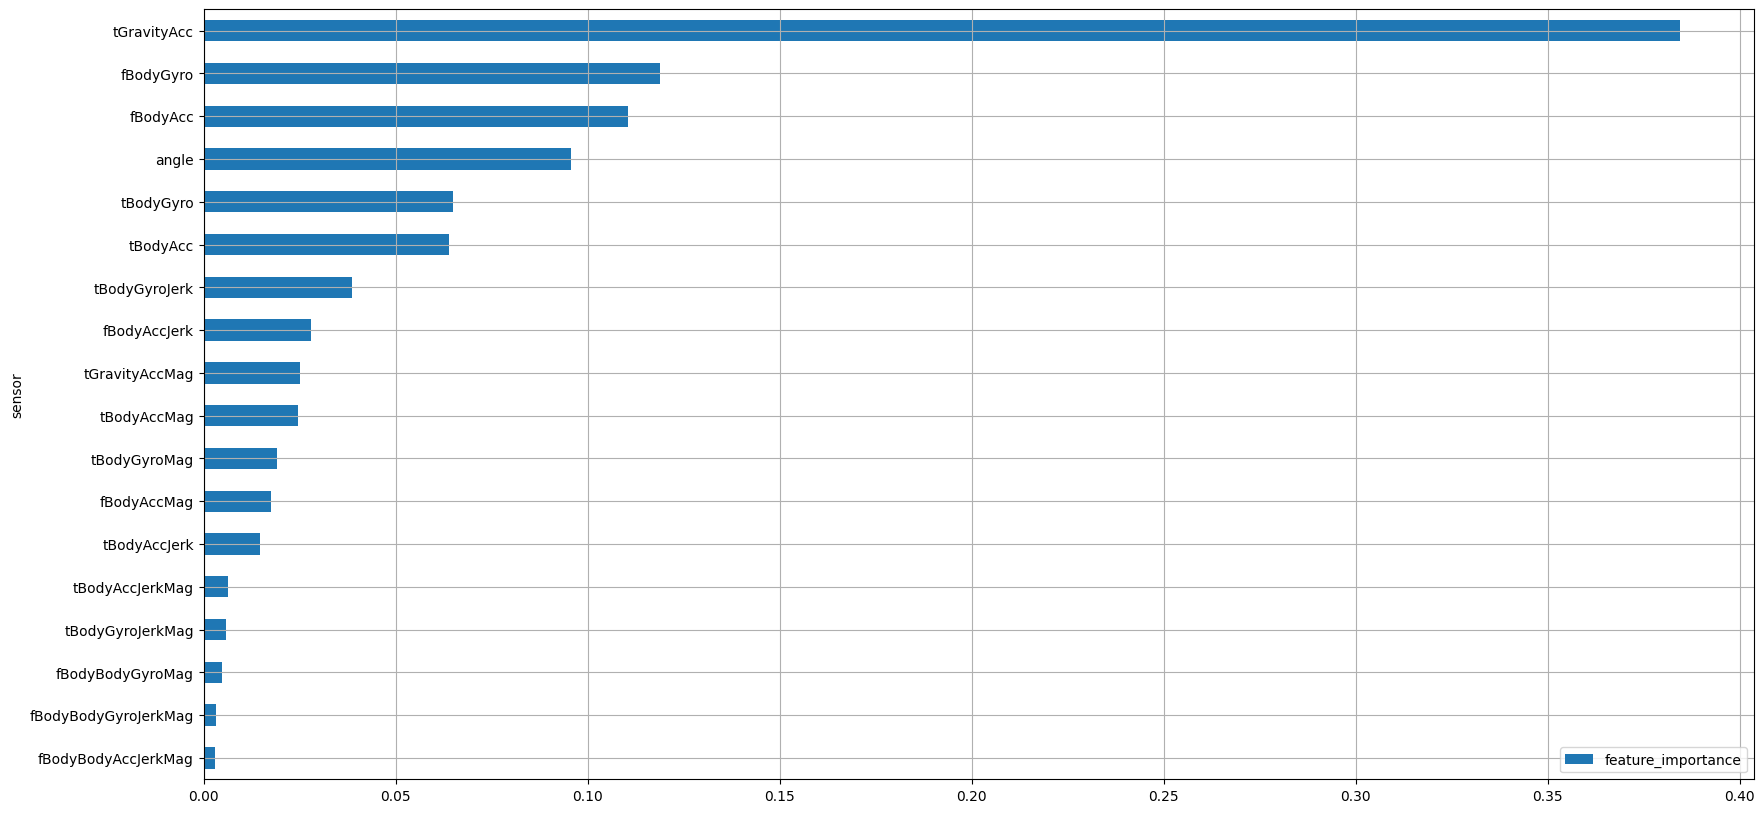

In [57]:
# sensor별
is_standing_result.groupby('sensor')[['feature_importance']].sum().sort_values('feature_importance').plot.barh(figsize=(20,10))
plt.grid()
plt.show()

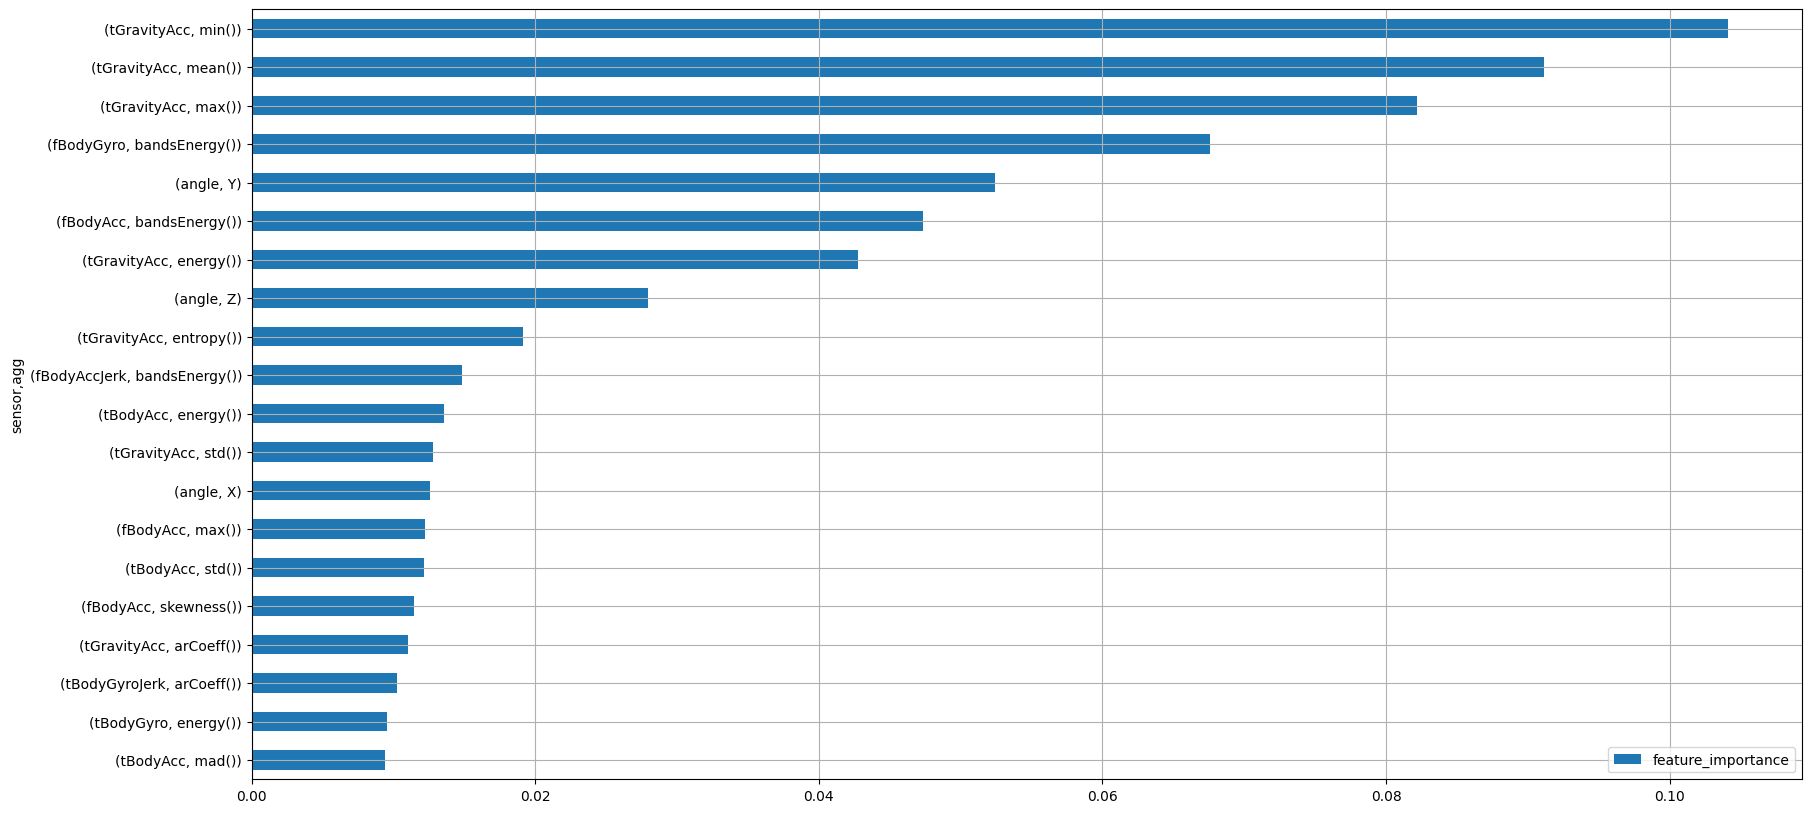

In [58]:
# sensor+agg 별
temp = is_standing_result.groupby(['sensor', 'agg'])[['feature_importance']].sum().sort_values('feature_importance')
temp.tail(20).plot.barh(figsize=(20,10))
plt.grid()
plt.show()

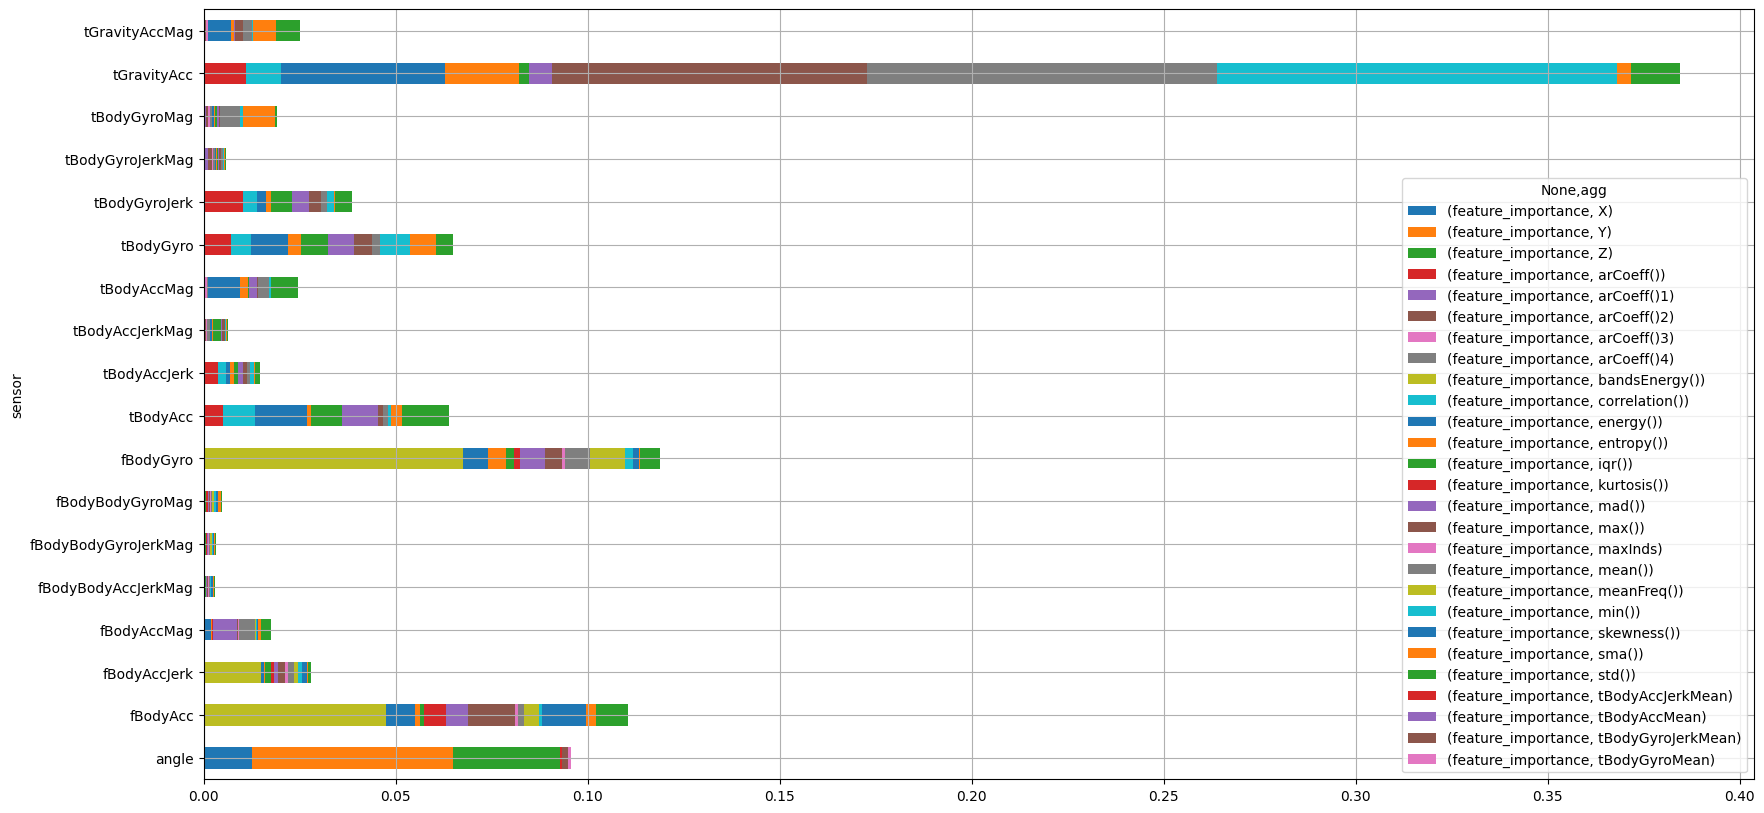

In [59]:
is_standing_result.groupby(['sensor', 'agg'])[['feature_importance']].sum().unstack().plot(kind='barh', stacked=True, figsize=(20,10))
plt.grid()
plt.show()

In [60]:
# 중요도 상위 변수 몇개만 가지고 다시 모델링

# 데이터 분할을 위한 전처리
target = 'is_standing'
non_feature_list.append(target)

x = data[r3.iloc[:10, 0]]
y = data.loc[:, target]

x_train, x_val, y_train, y_val = train_test_split(x, y, test_size = .3, random_state=42)

#생성
model_03 = RandomForestClassifier(random_state=42)

#학습
model_03.fit(x_train, y_train)
pred = model_03.predict(x_val)

#평가
print('accuracy :',accuracy_score(y_val, pred))
print('='*60)
print(confusion_matrix(y_val, pred))
print('='*60)
print(classification_report(y_val, pred))

accuracy : 0.9614730878186969
[[1448    4]
 [  64  249]]
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      1452
           1       0.98      0.80      0.88       313

    accuracy                           0.96      1765
   macro avg       0.97      0.90      0.93      1765
weighted avg       0.96      0.96      0.96      1765



### (3) 개별 동작 분석 : is_sitting


* **세부 요구사항**
    - Target인 Activity를 is_sitting 변수로 변경하시오.
        * 값 1 : SITTING
        * 값 0 : 나머지
    - is_sitting 을 예측하기 위한 기본 모델을 생성하시오.
        * x, is_sitting 을 이용하여 train과 validation으로 데이터 분할
        * 기본 모델링
    - is_sitting 을 구분하는데 중요한 변수 상위 5를 분석하시오.
    - is_sitting 을 구분하는데 중요한 변수 그룹을 분석하시오.
        * sensor별
        * sensor+agg 별


1) is_sitting 추가

In [61]:
data['is_sitting'] = data['Activity'].map(lambda x: 1 if x == 'SITTING' else 0)
data

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,"angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity,is_dynamic,is_standing,is_sitting
0,0.288508,-0.009196,-0.103362,-0.988986,-0.962797,-0.967422,-0.989000,-0.962596,-0.965650,-0.929747,...,-0.044218,0.307873,0.072790,-0.601120,0.331298,0.165163,STANDING,0,1,0
1,0.265757,-0.016576,-0.098163,-0.989551,-0.994636,-0.987435,-0.990189,-0.993870,-0.987558,-0.937337,...,0.388459,-0.765014,0.771524,0.345205,-0.769186,-0.147944,LAYING,0,0,0
2,0.278709,-0.014511,-0.108717,-0.997720,-0.981088,-0.994008,-0.997934,-0.982187,-0.995017,-0.942584,...,-0.525022,-0.891875,0.021528,-0.833564,0.202434,-0.032755,STANDING,0,1,0
3,0.289795,-0.035536,-0.150354,-0.231727,-0.006412,-0.338117,-0.273557,0.014245,-0.347916,0.008288,...,0.612804,0.747381,-0.072944,-0.695819,0.287154,0.111388,WALKING,1,0,0
4,0.394807,0.034098,0.091229,0.088489,-0.106636,-0.388502,-0.010469,-0.109680,-0.346372,0.584131,...,-0.845268,-0.974650,-0.887846,-0.705029,0.264952,0.137758,WALKING_DOWNSTAIRS,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5876,0.277194,-0.012389,-0.131974,-0.994046,-0.940578,-0.917337,-0.994261,-0.932830,-0.908088,-0.936219,...,-0.261437,-0.391477,-0.877612,-0.912365,0.114009,0.080146,SITTING,0,0,1
5877,0.191568,0.013328,-0.105174,-0.126969,-0.121729,-0.327480,-0.192523,-0.109923,-0.295286,0.078644,...,0.623151,0.866858,-0.445660,-0.690278,0.303194,-0.044188,WALKING_UPSTAIRS,1,0,0
5878,0.267981,-0.018348,-0.107440,-0.991303,-0.989881,-0.990313,-0.992386,-0.988852,-0.991237,-0.936099,...,0.228739,0.684400,-0.216665,0.620363,-0.437247,-0.571840,LAYING,0,0,0
5879,0.212787,-0.048130,-0.121001,-0.041373,0.052449,-0.585361,-0.100714,0.023353,-0.554707,0.219814,...,0.551742,-0.943773,-0.862899,-0.718009,0.292856,0.024920,WALKING_UPSTAIRS,1,0,0


2) 기본모델 생성

In [62]:
# 데이터 분할을 위한 전처리
target = 'is_sitting'
non_feature_list.append(target)

x = data.drop(non_feature_list, axis = 1)
y = data.loc[:, target]

x_train, x_val, y_train, y_val = train_test_split(x, y, test_size = .3, random_state=42)

In [63]:
#생성
model_04 = RandomForestClassifier(random_state=42)

#학습
model_04.fit(x_train, y_train)
pred = model_04.predict(x_val)

#평가
print('accuracy :',accuracy_score(y_val, pred))
print('='*60)
print(confusion_matrix(y_val, pred))
print('='*60)
print(classification_report(y_val, pred))

accuracy : 0.9869688385269122
[[1446    9]
 [  14  296]]
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1455
           1       0.97      0.95      0.96       310

    accuracy                           0.99      1765
   macro avg       0.98      0.97      0.98      1765
weighted avg       0.99      0.99      0.99      1765



In [64]:
r4 = plot_feature_importance(model_04.feature_importances_, list(x_train), False)
r4

Output hidden; open in https://colab.research.google.com to view.

In [65]:
r4.head()

,feature_name,feature_importance
0,tGravityAcc-mean()-Y,0.056311
1,tGravityAcc-min()-Y,0.032818
2,tGravityAcc-mean()-X,0.032278
3,"angle(X,gravityMean)",0.028789
4,tGravityAcc-energy()-X,0.028504


3) 변수중요도 상위 5개 분석

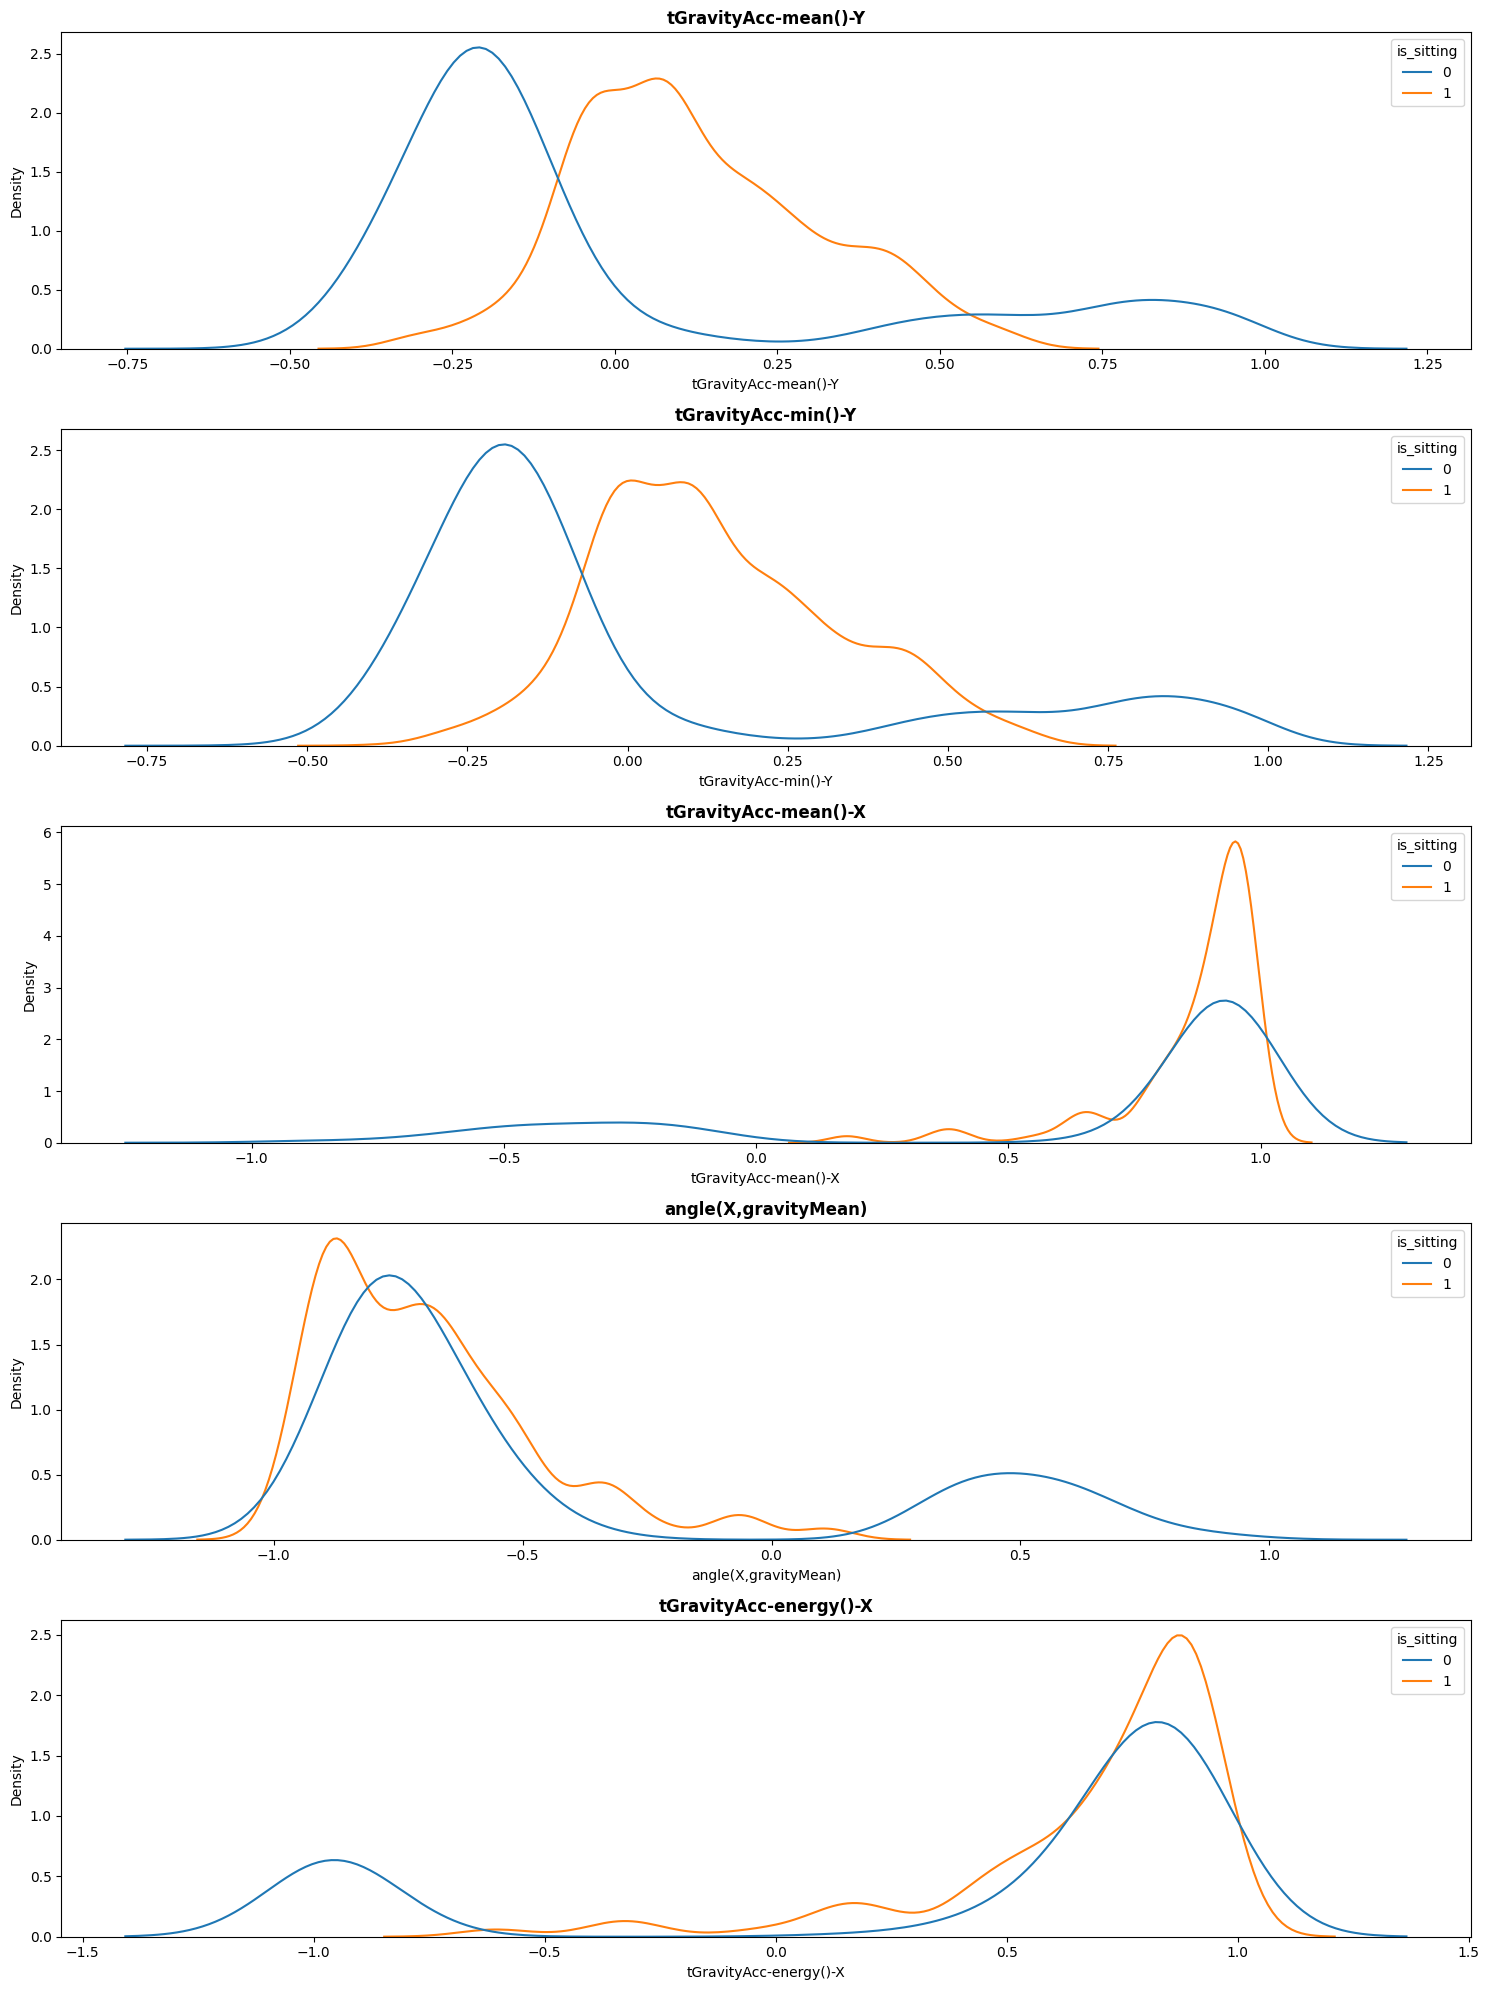

In [66]:
# 중요도 상위 5개 정보에 대한 분석
fig, ax = plt.subplots(5, figsize=(15,20))
for i in range(5):
    var = r4.iloc[i, 0]
    sns.kdeplot(x=var, data=data, hue=target, common_norm=False, ax=ax[i])
    ax[i].set_title(f'{var}', fontweight='bold')
plt.tight_layout()
plt.show()

In [67]:
is_sitting_result = pd.merge(features, r4, how='inner', on='feature_name')
is_sitting_result

,sensor,agg,axis,feature_name,feature_importance
0,tBodyAcc,mean(),X,tBodyAcc-mean()-X,0.000540
1,tBodyAcc,mean(),Y,tBodyAcc-mean()-Y,0.001017
2,tBodyAcc,mean(),Z,tBodyAcc-mean()-Z,0.000246
3,tBodyAcc,std(),X,tBodyAcc-std()-X,0.000867
4,tBodyAcc,std(),Y,tBodyAcc-std()-Y,0.000511
...,...,...,...,...,...
556,angle,tBodyGyroMean,gravityMean,"angle(tBodyGyroMean,gravityMean)",0.000799
557,angle,tBodyGyroJerkMean,gravityMean,"angle(tBodyGyroJerkMean,gravityMean)",0.002341
558,angle,X,gravityMean,"angle(X,gravityMean)",0.028789
559,angle,Y,gravityMean,"angle(Y,gravityMean)",0.023809


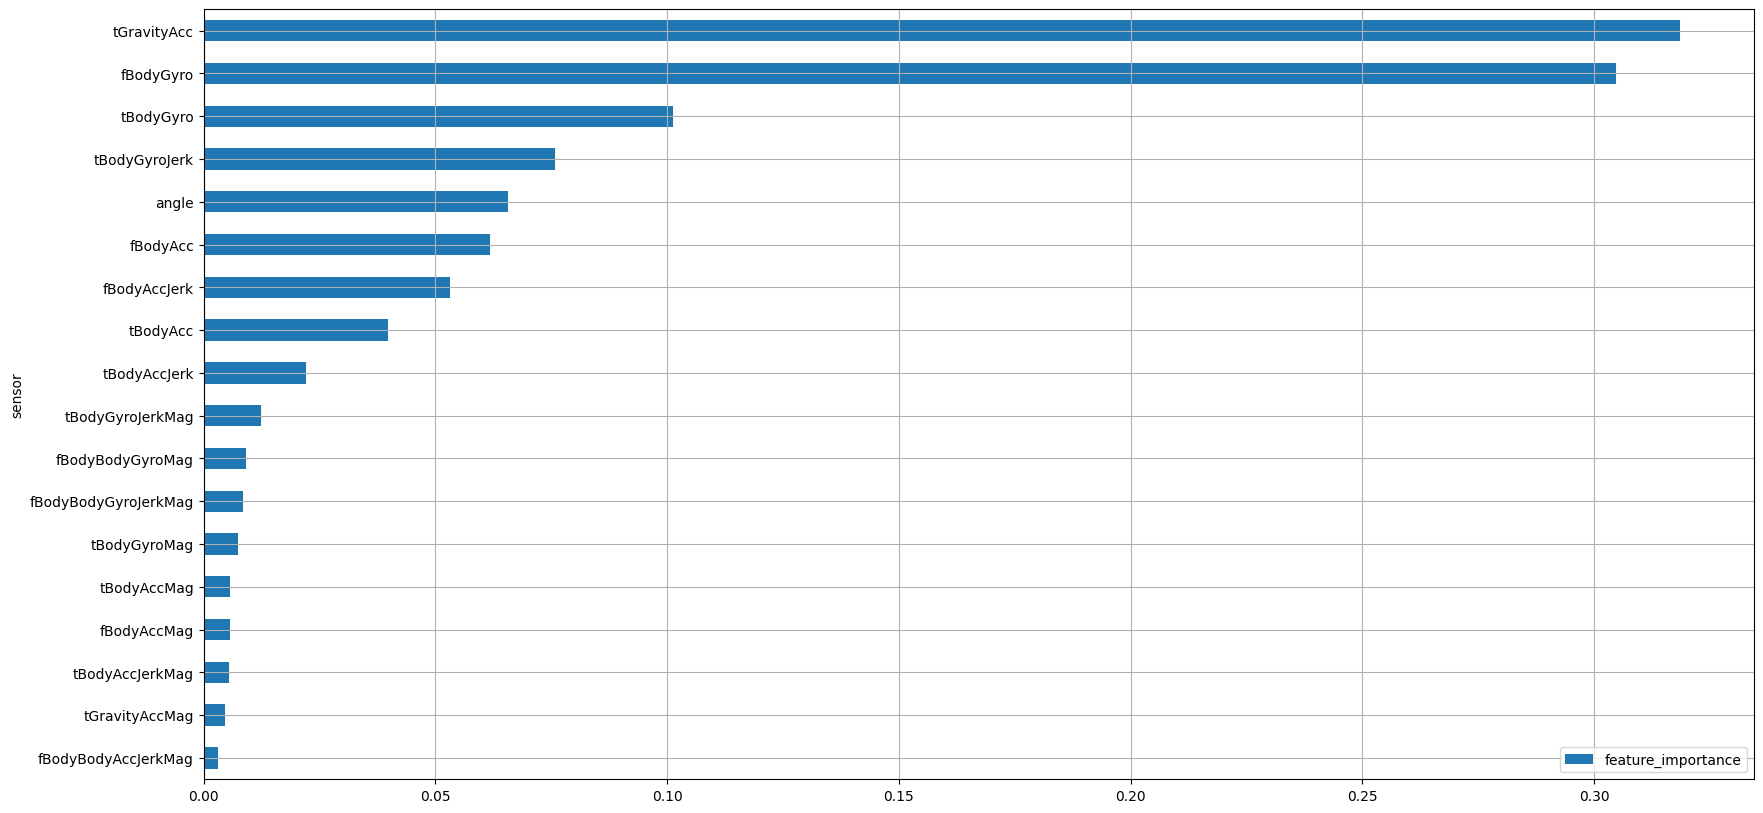

In [68]:
is_sitting_result.groupby('sensor')[['feature_importance']].sum().sort_values('feature_importance').plot.barh(figsize=(20,10))
plt.grid()
plt.show()

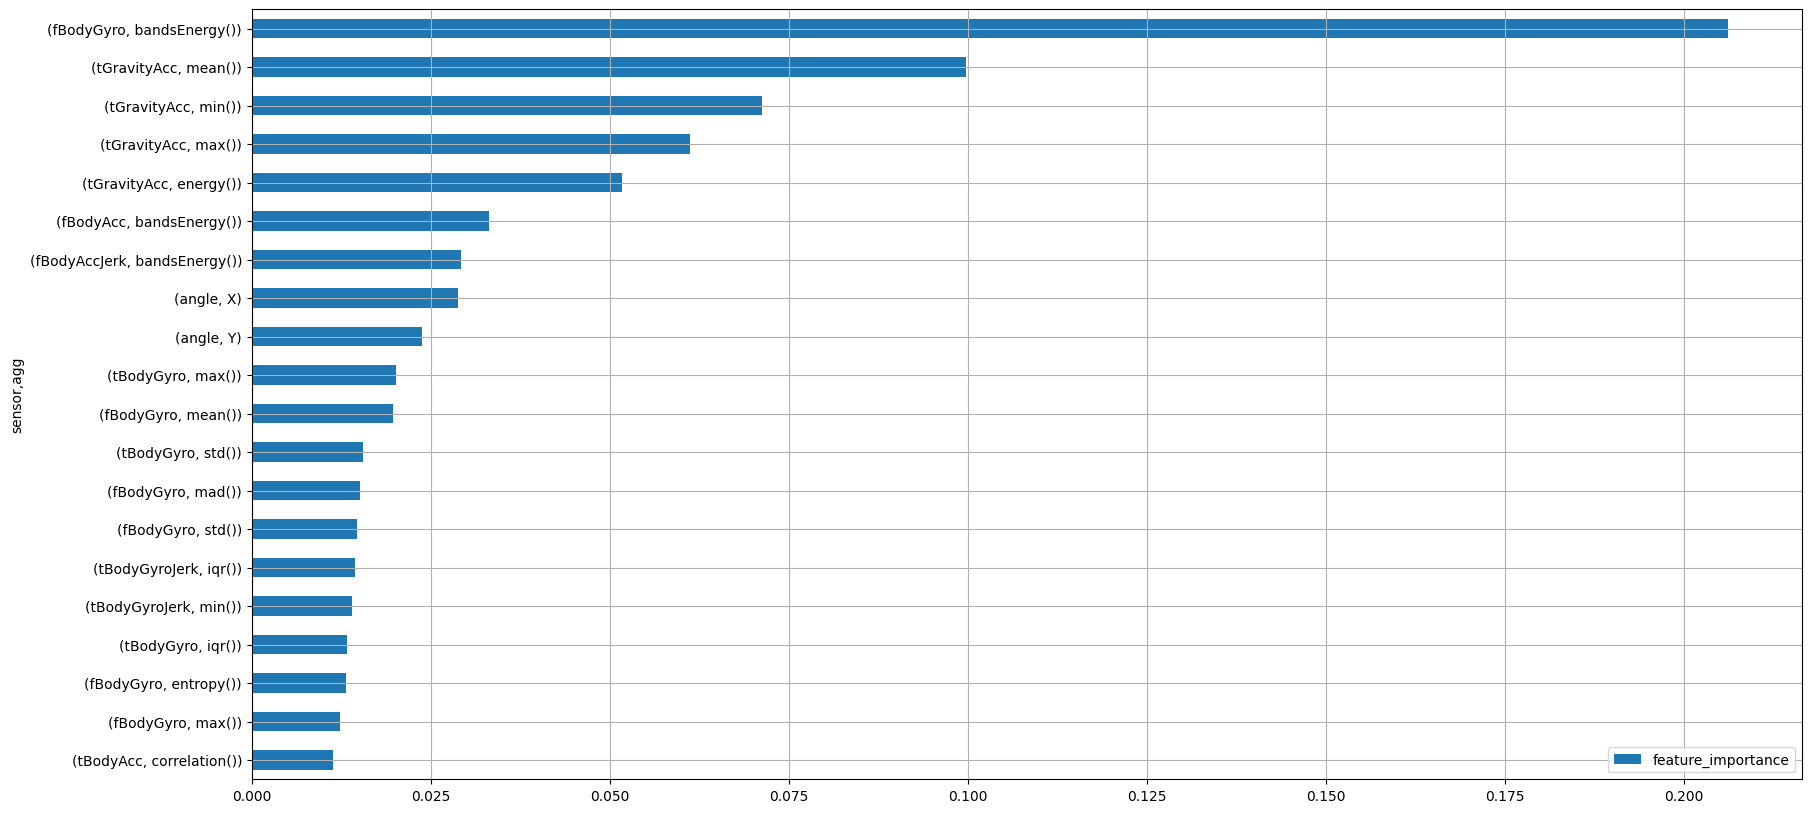

In [69]:
temp = is_sitting_result.groupby(['sensor', 'agg'])[['feature_importance']].sum().sort_values('feature_importance')
temp.tail(20).plot.barh(figsize=(20,10))
plt.grid()
plt.show()

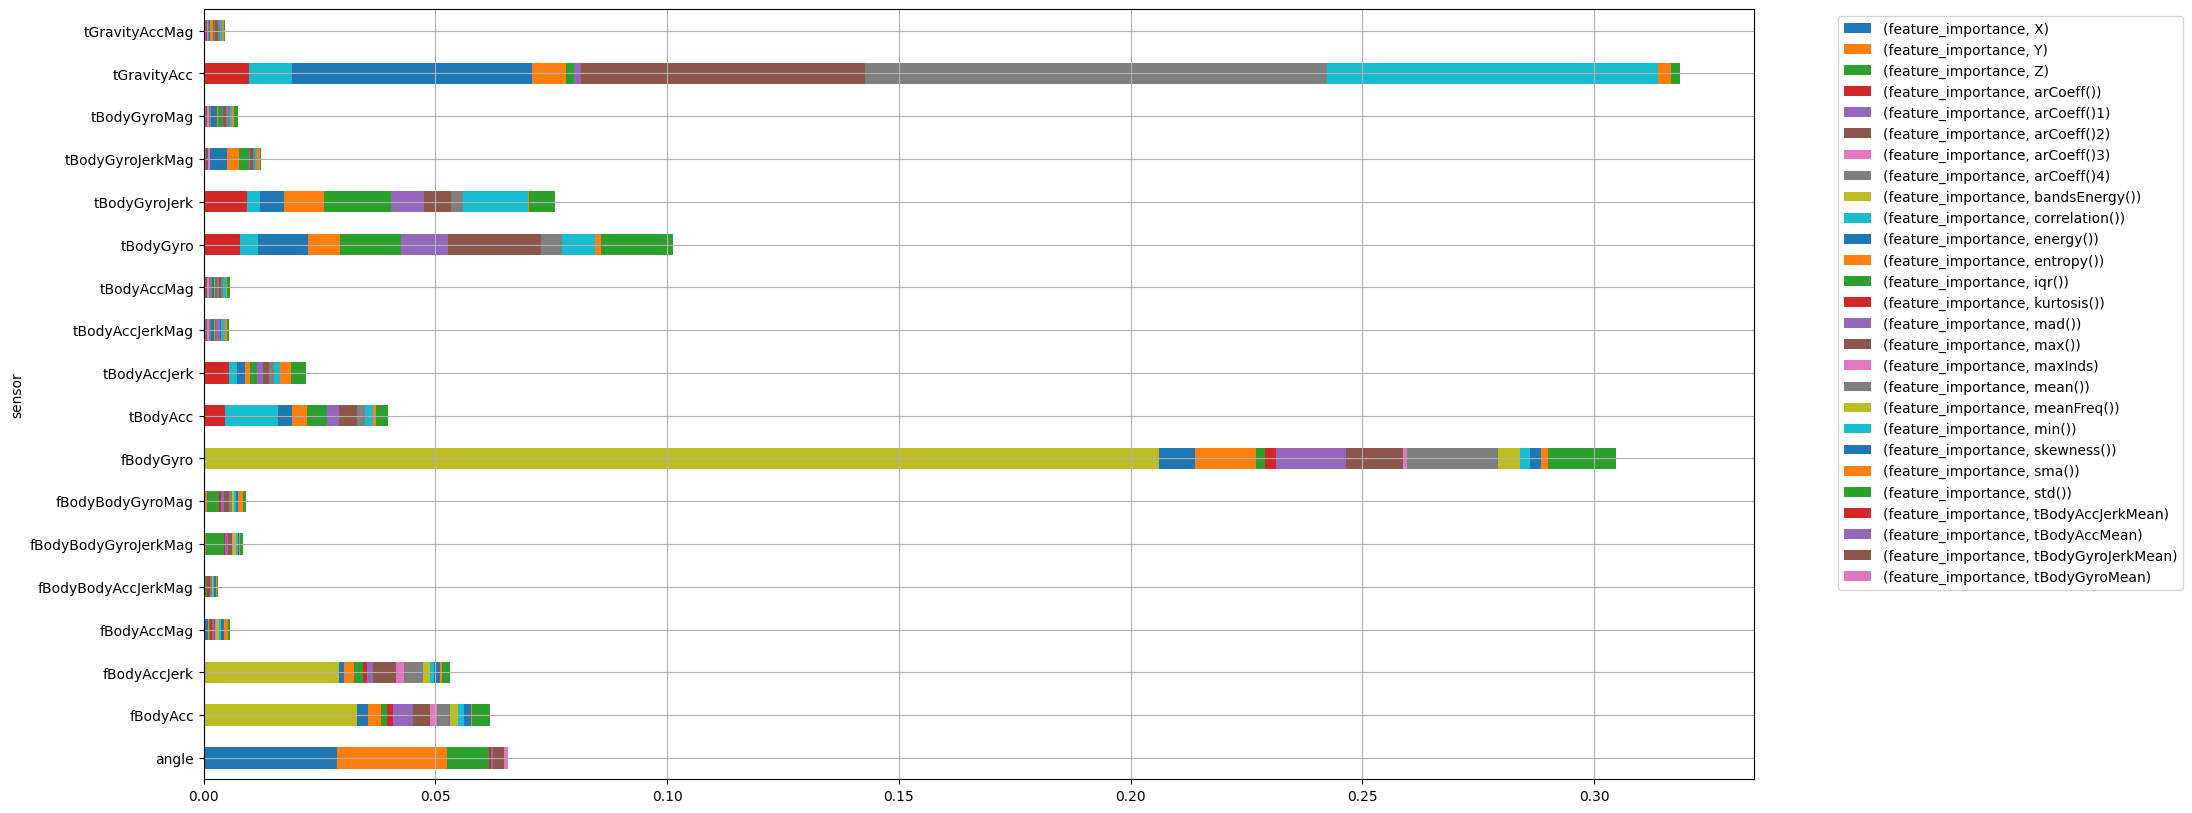

In [70]:
is_sitting_result.groupby(['sensor', 'agg'])[['feature_importance']].sum().unstack().plot(kind='barh', stacked=True, figsize=(20,10))
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid()
plt.show()

In [71]:
# 중요도 상위 변수 몇개만 가지고 다시 모델링

# 데이터 분할을 위한 전처리
target = 'is_sitting'
non_feature_list.append(target)

x = data[r4.iloc[:10, 0]]
y = data.loc[:, target]

x_train, x_val, y_train, y_val = train_test_split(x, y, test_size = .3, random_state=42)

#생성
model_04 = RandomForestClassifier(random_state=42)

#학습
model_04.fit(x_train, y_train)
pred = model_04.predict(x_val)

#평가
print('accuracy :',accuracy_score(y_val, pred))
print('='*60)
print(confusion_matrix(y_val, pred))
print('='*60)
print(classification_report(y_val, pred))

accuracy : 0.9858356940509915
[[1443   12]
 [  13  297]]
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1455
           1       0.96      0.96      0.96       310

    accuracy                           0.99      1765
   macro avg       0.98      0.97      0.98      1765
weighted avg       0.99      0.99      0.99      1765



### (4) 개별 동작 분석 : is_laying


* **세부 요구사항**
    - Target인 Activity를 is_laying 변수로 변경하시오.
        * 값 1 : LAYING
        * 값 0 : 나머지
    - is_laying 을 예측하기 위한 기본 모델을 생성하시오.
        * x, is_laying 을 이용하여 train과 validation으로 데이터 분할
        * 기본 모델링
    - is_laying 을 구분하는데 중요한 변수 상위 5를 분석하시오.
    - is_laying 을 구분하는데 중요한 변수 그룹을 분석하시오.
        * sensor별
        * sensor+agg 별


1) is_laying 추가

In [72]:
data['is_laying'] = data['Activity'].map(lambda x: 1 if x == 'LAYING' else 0)
data

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,"angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity,is_dynamic,is_standing,is_sitting,is_laying
0,0.288508,-0.009196,-0.103362,-0.988986,-0.962797,-0.967422,-0.989000,-0.962596,-0.965650,-0.929747,...,0.307873,0.072790,-0.601120,0.331298,0.165163,STANDING,0,1,0,0
1,0.265757,-0.016576,-0.098163,-0.989551,-0.994636,-0.987435,-0.990189,-0.993870,-0.987558,-0.937337,...,-0.765014,0.771524,0.345205,-0.769186,-0.147944,LAYING,0,0,0,1
2,0.278709,-0.014511,-0.108717,-0.997720,-0.981088,-0.994008,-0.997934,-0.982187,-0.995017,-0.942584,...,-0.891875,0.021528,-0.833564,0.202434,-0.032755,STANDING,0,1,0,0
3,0.289795,-0.035536,-0.150354,-0.231727,-0.006412,-0.338117,-0.273557,0.014245,-0.347916,0.008288,...,0.747381,-0.072944,-0.695819,0.287154,0.111388,WALKING,1,0,0,0
4,0.394807,0.034098,0.091229,0.088489,-0.106636,-0.388502,-0.010469,-0.109680,-0.346372,0.584131,...,-0.974650,-0.887846,-0.705029,0.264952,0.137758,WALKING_DOWNSTAIRS,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5876,0.277194,-0.012389,-0.131974,-0.994046,-0.940578,-0.917337,-0.994261,-0.932830,-0.908088,-0.936219,...,-0.391477,-0.877612,-0.912365,0.114009,0.080146,SITTING,0,0,1,0
5877,0.191568,0.013328,-0.105174,-0.126969,-0.121729,-0.327480,-0.192523,-0.109923,-0.295286,0.078644,...,0.866858,-0.445660,-0.690278,0.303194,-0.044188,WALKING_UPSTAIRS,1,0,0,0
5878,0.267981,-0.018348,-0.107440,-0.991303,-0.989881,-0.990313,-0.992386,-0.988852,-0.991237,-0.936099,...,0.684400,-0.216665,0.620363,-0.437247,-0.571840,LAYING,0,0,0,1
5879,0.212787,-0.048130,-0.121001,-0.041373,0.052449,-0.585361,-0.100714,0.023353,-0.554707,0.219814,...,-0.943773,-0.862899,-0.718009,0.292856,0.024920,WALKING_UPSTAIRS,1,0,0,0


2) 기본모델 생성

In [73]:
# 데이터 분할을 위한 전처리
target = 'is_laying'
non_feature_list.append(target)

x = data.drop(non_feature_list, axis = 1)
y = data.loc[:, target]

x_train, x_val, y_train, y_val = train_test_split(x, y, test_size = .3, random_state=42)

In [74]:
#생성
model_05 = RandomForestClassifier(random_state=42)

#학습
model_05.fit(x_train, y_train)
pred = model_05.predict(x_val)

#평가
print('accuracy :',accuracy_score(y_val, pred))
print('='*60)
print(confusion_matrix(y_val, pred))
print('='*60)
print(classification_report(y_val, pred))

accuracy : 1.0
[[1431    0]
 [   0  334]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1431
           1       1.00      1.00      1.00       334

    accuracy                           1.00      1765
   macro avg       1.00      1.00      1.00      1765
weighted avg       1.00      1.00      1.00      1765



In [75]:
r5 = plot_feature_importance(model_05.feature_importances_, list(x_train), False)
r5

Output hidden; open in https://colab.research.google.com to view.

In [76]:
r5.head()

,feature_name,feature_importance
0,tGravityAcc-mean()-X,0.101994
1,"angle(X,gravityMean)",0.101940
2,tGravityAcc-max()-X,0.088779
3,tGravityAcc-min()-X,0.076688
4,"angle(Z,gravityMean)",0.075663


3) 변수중요도 상위 5개 분석

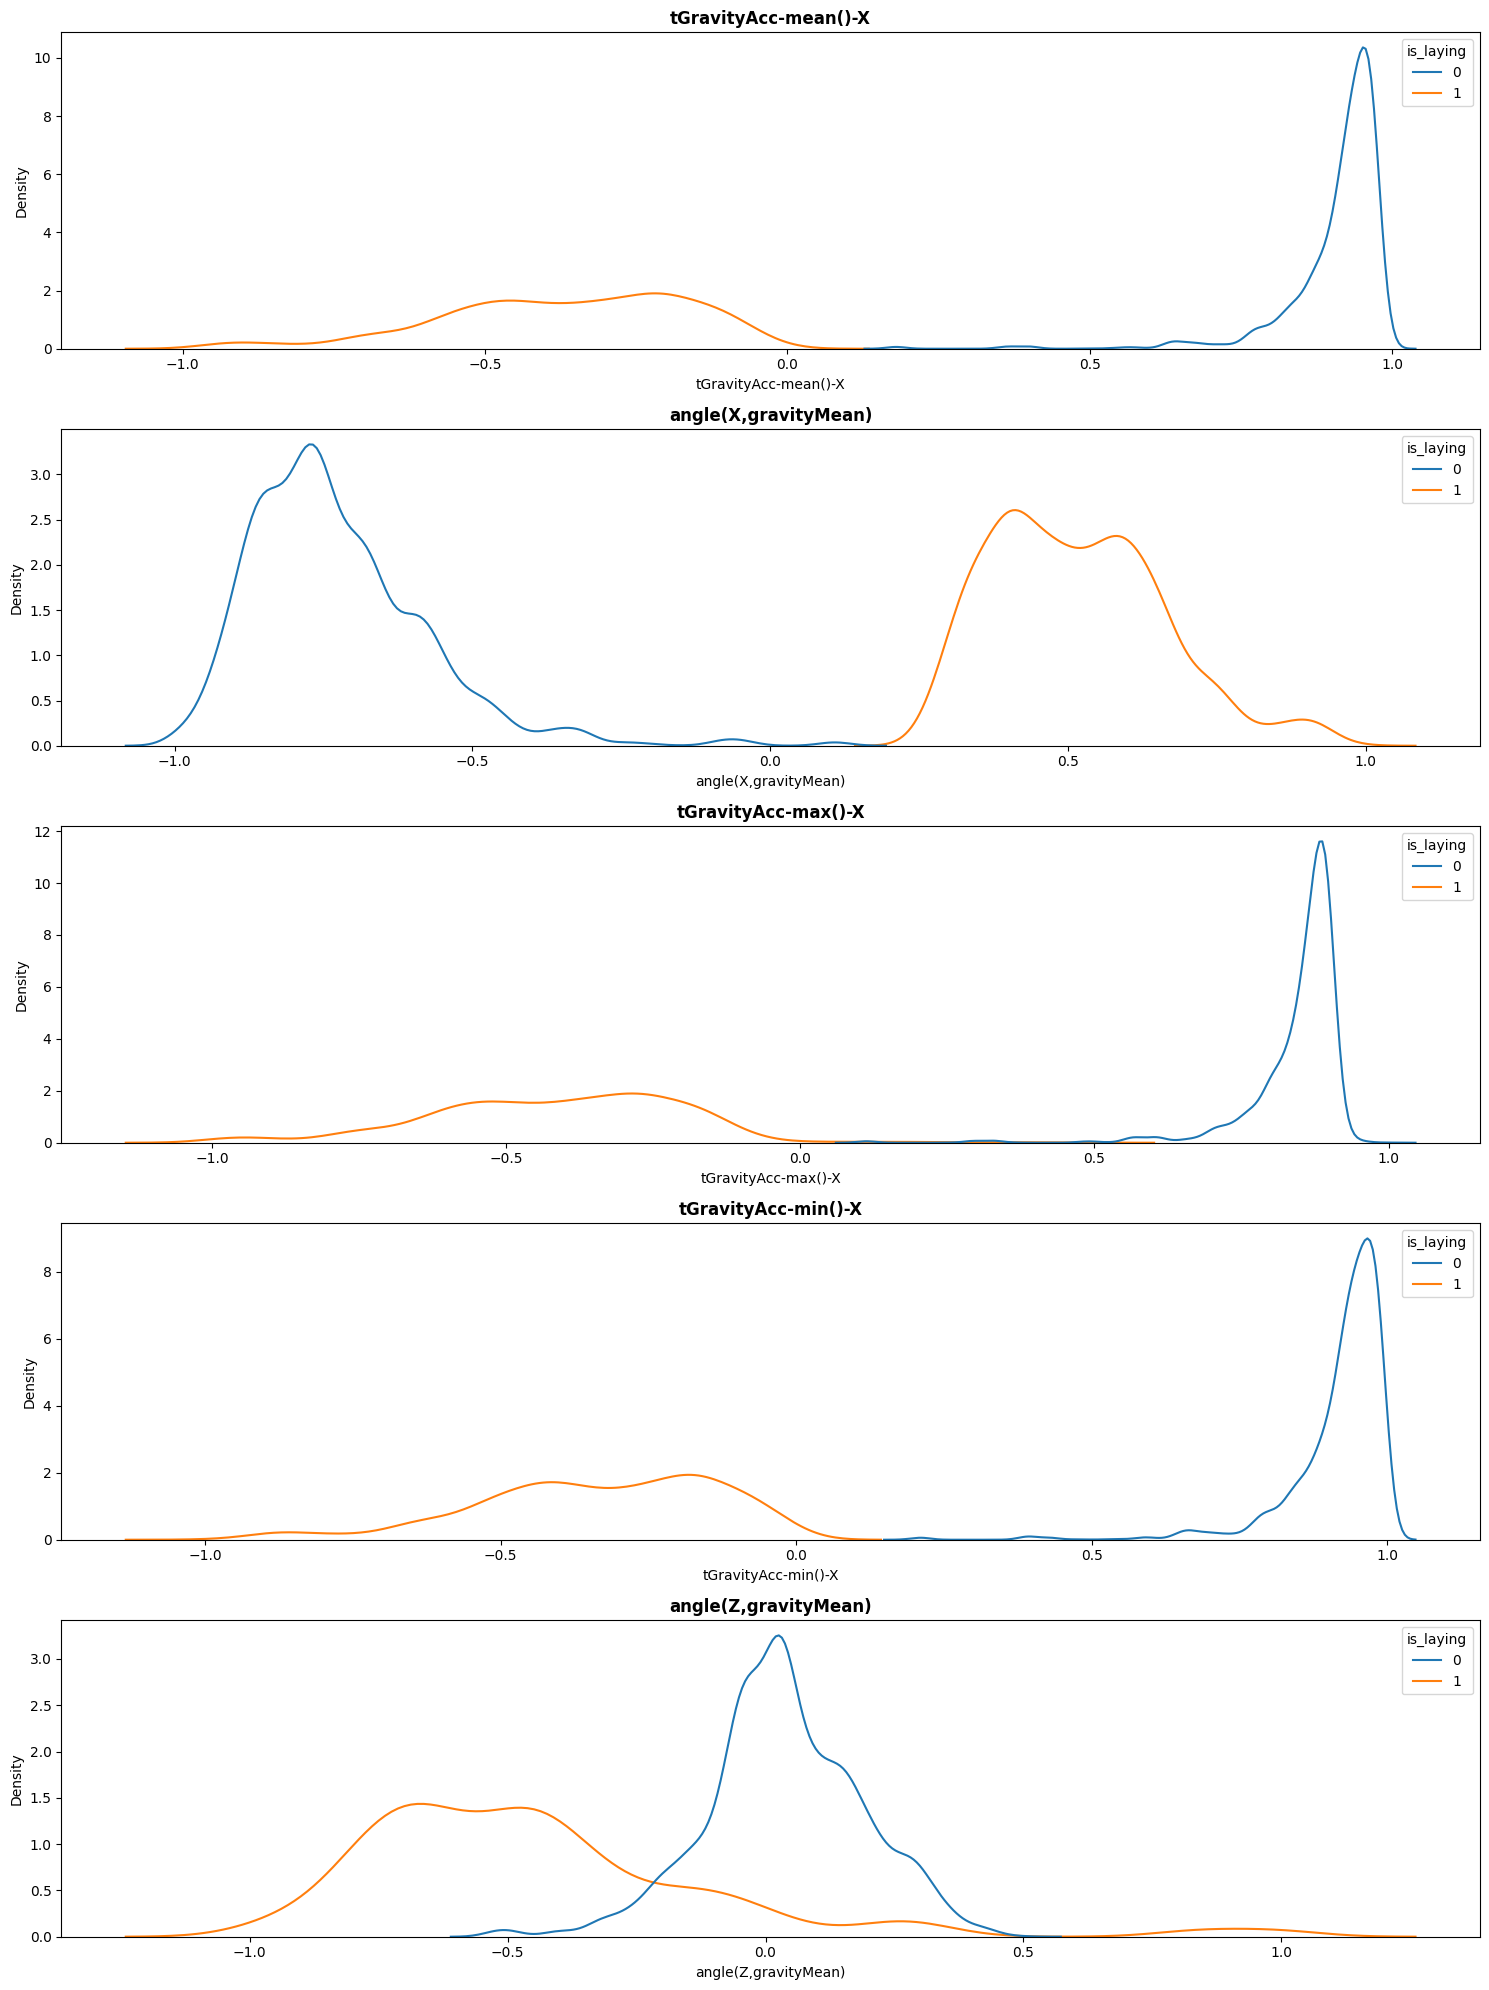

In [77]:
# 중요도 상위 5개 정보에 대한 분석
fig, ax = plt.subplots(5, figsize=(15,20))
for i in range(5):
    var = r5.iloc[i, 0]
    sns.kdeplot(x=var, data=data, hue=target, common_norm=False, ax=ax[i])
    ax[i].set_title(f'{var}', fontweight='bold')
plt.tight_layout()
plt.show()

In [78]:
is_laying_result = pd.merge(features, r5, how='inner', on='feature_name')
is_laying_result

,sensor,agg,axis,feature_name,feature_importance
0,tBodyAcc,mean(),X,tBodyAcc-mean()-X,0.000282
1,tBodyAcc,mean(),Y,tBodyAcc-mean()-Y,0.000347
2,tBodyAcc,mean(),Z,tBodyAcc-mean()-Z,0.000002
3,tBodyAcc,std(),X,tBodyAcc-std()-X,0.001857
4,tBodyAcc,std(),Y,tBodyAcc-std()-Y,0.000000
...,...,...,...,...,...
556,angle,tBodyGyroMean,gravityMean,"angle(tBodyGyroMean,gravityMean)",0.000072
557,angle,tBodyGyroJerkMean,gravityMean,"angle(tBodyGyroJerkMean,gravityMean)",0.000084
558,angle,X,gravityMean,"angle(X,gravityMean)",0.101940
559,angle,Y,gravityMean,"angle(Y,gravityMean)",0.021796


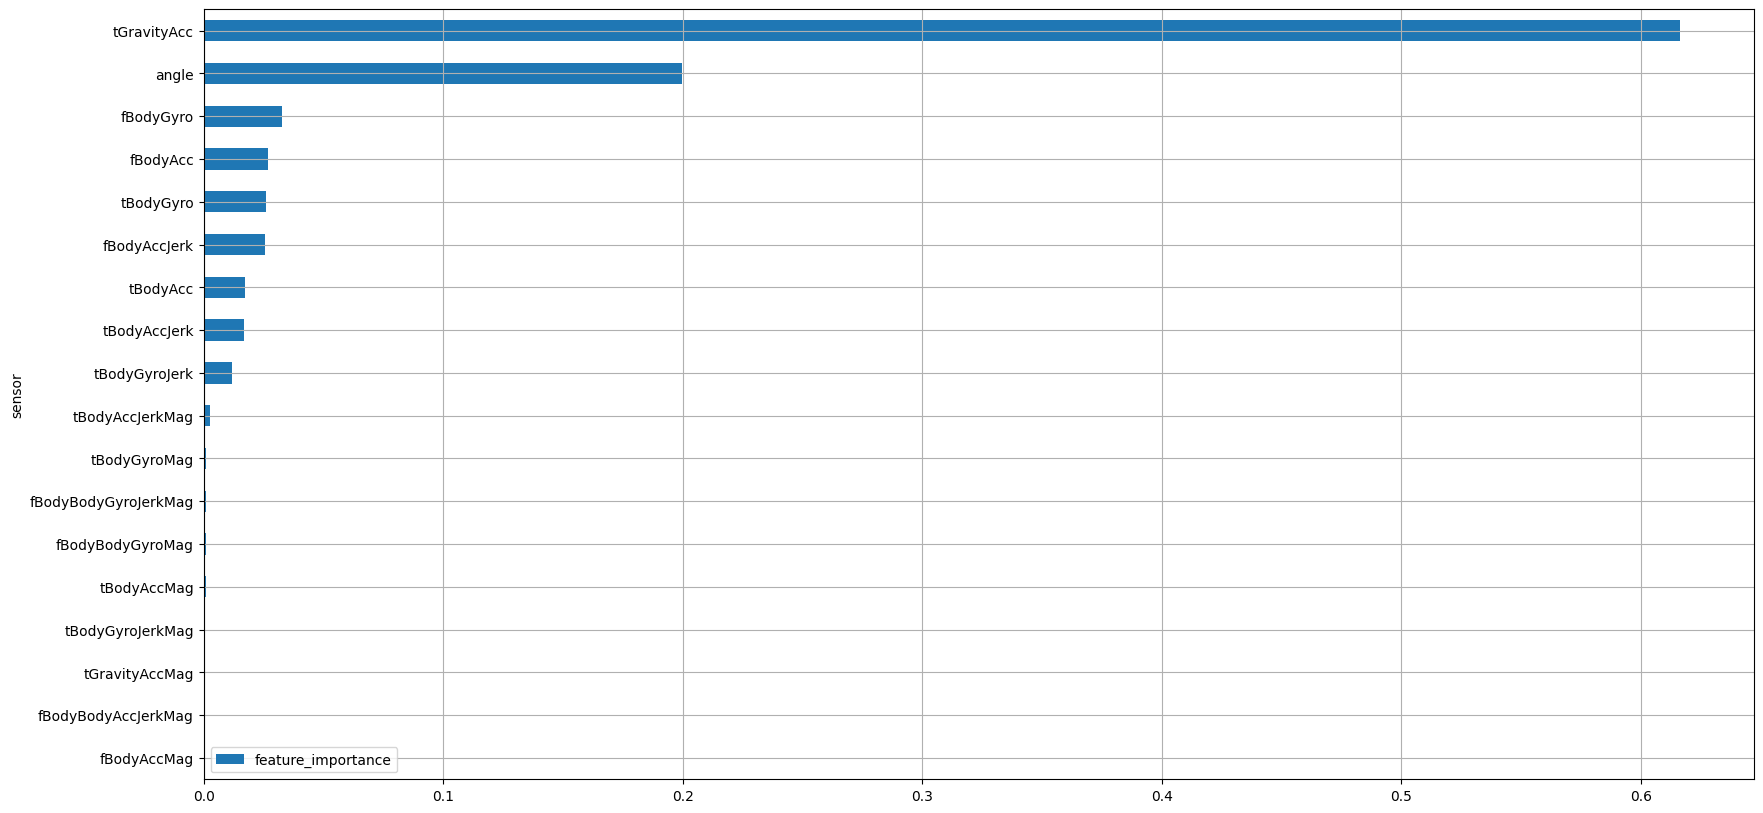

In [79]:
is_laying_result.groupby('sensor')[['feature_importance']].sum().sort_values('feature_importance').plot.barh(figsize=(20,10))
plt.grid()
plt.show()

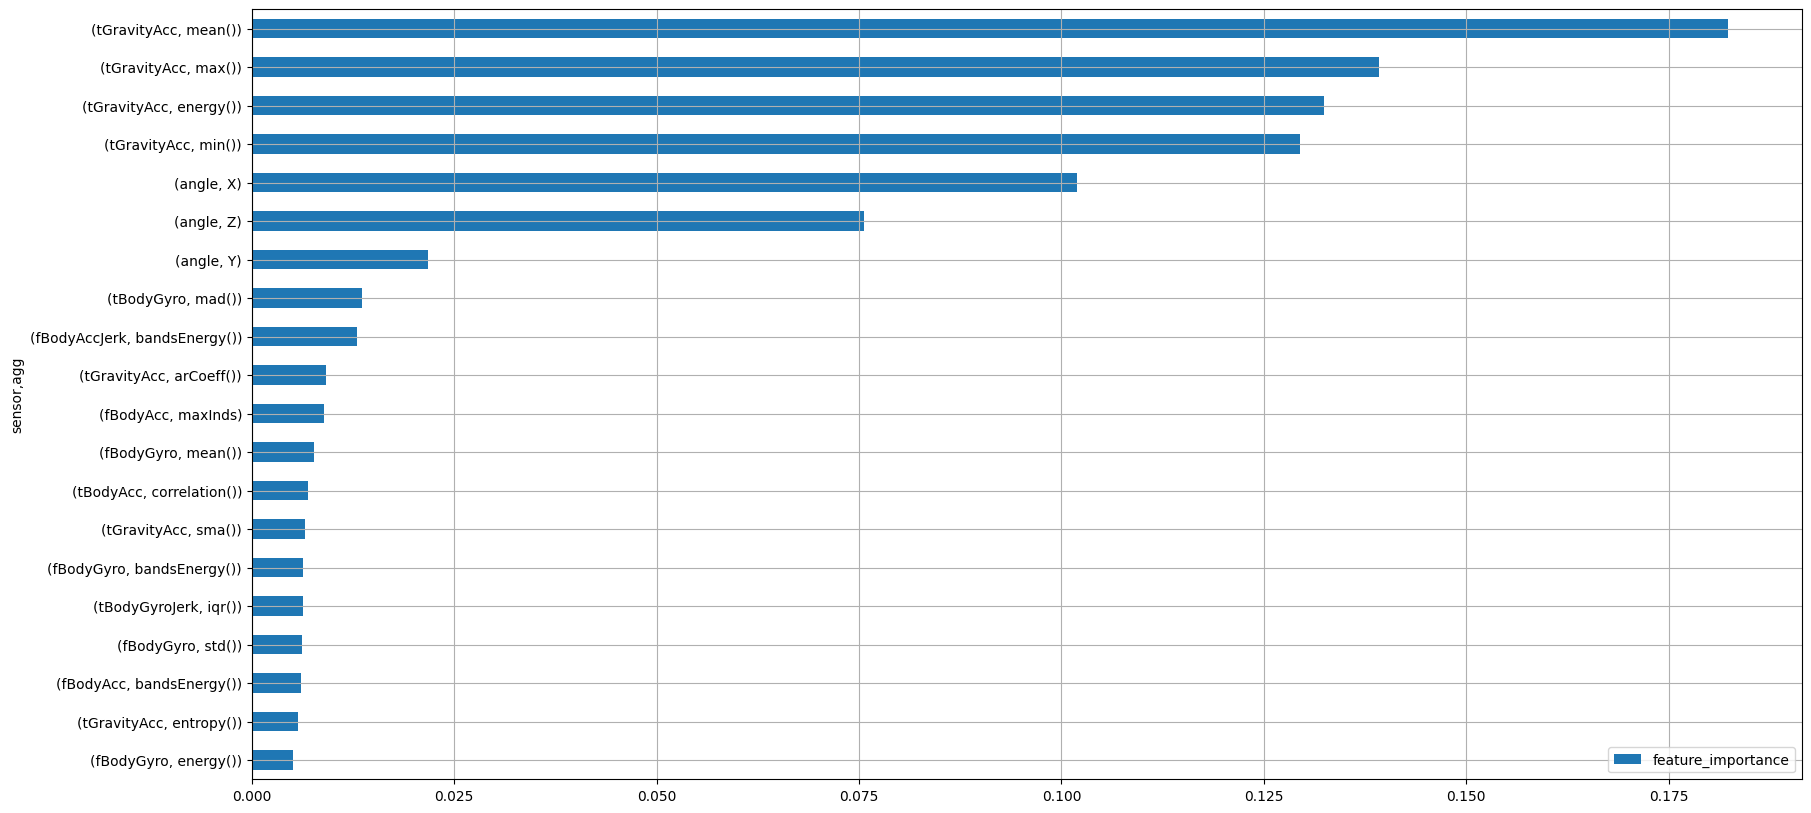

In [80]:
temp = is_laying_result.groupby(['sensor', 'agg'])[['feature_importance']].sum().sort_values('feature_importance')
temp.tail(20).plot.barh(figsize=(20,10))
plt.grid()
plt.show()

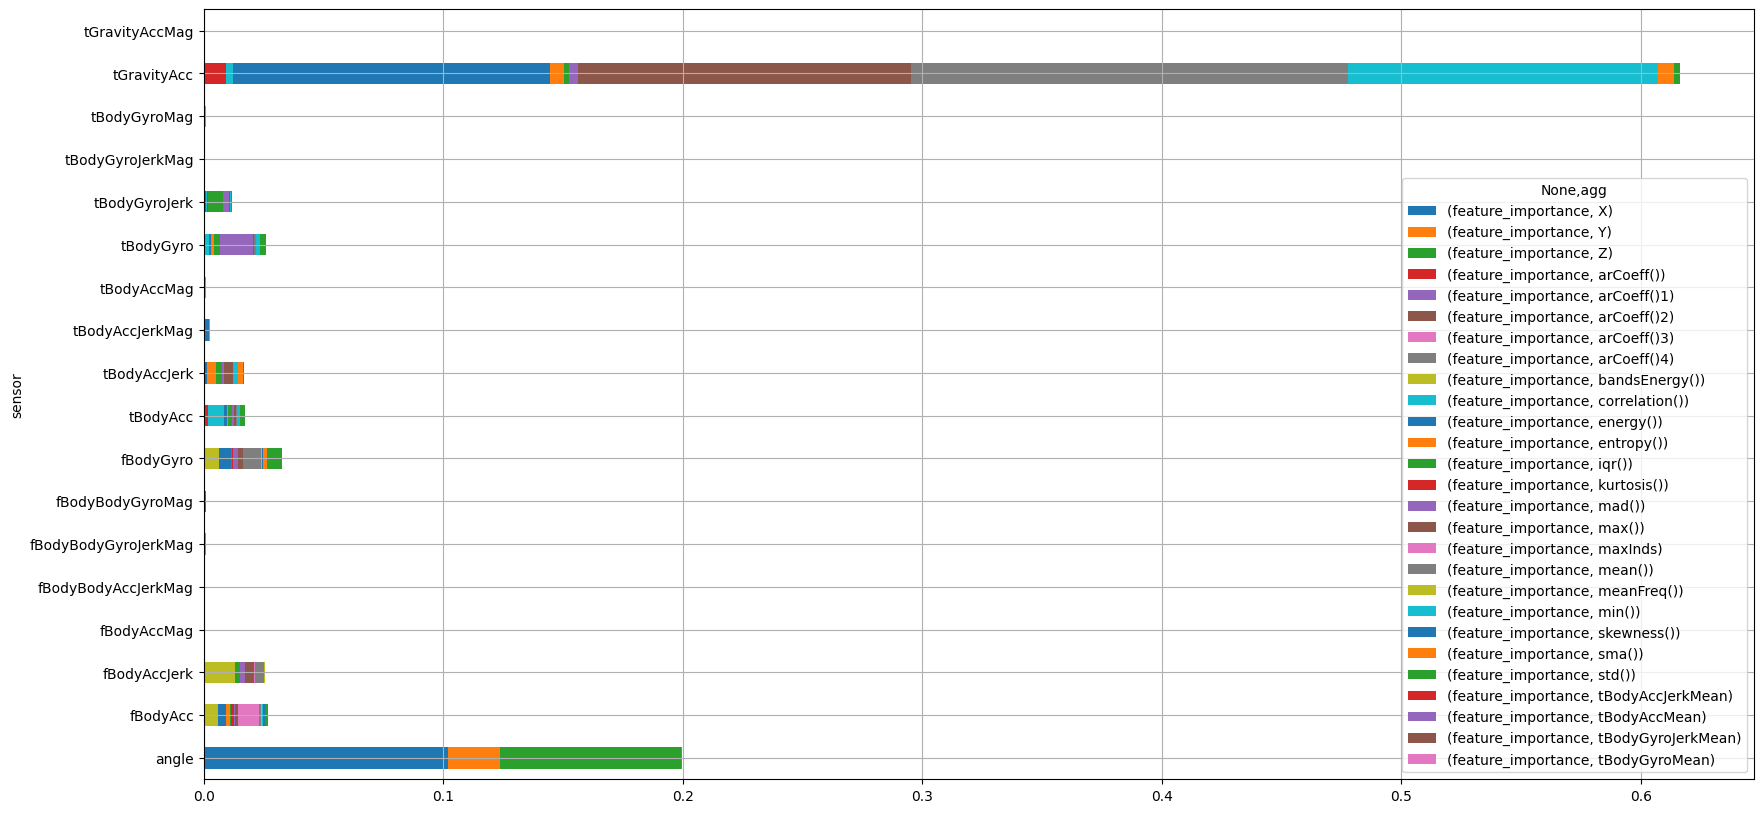

In [81]:
is_laying_result.groupby(['sensor', 'agg'])[['feature_importance']].sum().unstack().plot(kind='barh', stacked=True, figsize=(20,10))
plt.grid()
plt.show()

In [82]:
# 중요도 상위 변수 몇개만 가지고 다시 모델링

# 데이터 분할을 위한 전처리
target = 'is_laying'
non_feature_list.append(target)

x = data[r3.iloc[:10, 0]]
y = data.loc[:, target]

x_train, x_val, y_train, y_val = train_test_split(x, y, test_size = .3, random_state=42)

#생성
model_05 = RandomForestClassifier(random_state=42)

#학습
model_05.fit(x_train, y_train)
pred = model_05.predict(x_val)

#평가
print('accuracy :',accuracy_score(y_val, pred))
print('='*60)
print(confusion_matrix(y_val, pred))
print('='*60)
print(classification_report(y_val, pred))

accuracy : 1.0
[[1431    0]
 [   0  334]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1431
           1       1.00      1.00      1.00       334

    accuracy                           1.00      1765
   macro avg       1.00      1.00      1.00      1765
weighted avg       1.00      1.00      1.00      1765



### (5) 개별 동작 분석 : is_walking


* **세부 요구사항**
    - Target인 Activity를 is_walking 변수로 변경하시오.
        * 값 1 : WALKING
        * 값 0 : 나머지
    - is_walking 을 예측하기 위한 기본 모델을 생성하시오.
        * x, is_walking 을 이용하여 train과 validation으로 데이터 분할
        * 기본 모델링
    - is_walking 을 구분하는데 중요한 변수 상위 5를 분석하시오.
    - is_walking 을 구분하는데 중요한 변수 그룹을 분석하시오.
        * sensor별
        * sensor+agg 별


1) is_walking 추가

In [83]:
data['is_walking'] = data['Activity'].map(lambda x: 1 if x == 'WALKING' else 0)
data

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,"angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity,is_dynamic,is_standing,is_sitting,is_laying,is_walking
0,0.288508,-0.009196,-0.103362,-0.988986,-0.962797,-0.967422,-0.989000,-0.962596,-0.965650,-0.929747,...,0.072790,-0.601120,0.331298,0.165163,STANDING,0,1,0,0,0
1,0.265757,-0.016576,-0.098163,-0.989551,-0.994636,-0.987435,-0.990189,-0.993870,-0.987558,-0.937337,...,0.771524,0.345205,-0.769186,-0.147944,LAYING,0,0,0,1,0
2,0.278709,-0.014511,-0.108717,-0.997720,-0.981088,-0.994008,-0.997934,-0.982187,-0.995017,-0.942584,...,0.021528,-0.833564,0.202434,-0.032755,STANDING,0,1,0,0,0
3,0.289795,-0.035536,-0.150354,-0.231727,-0.006412,-0.338117,-0.273557,0.014245,-0.347916,0.008288,...,-0.072944,-0.695819,0.287154,0.111388,WALKING,1,0,0,0,1
4,0.394807,0.034098,0.091229,0.088489,-0.106636,-0.388502,-0.010469,-0.109680,-0.346372,0.584131,...,-0.887846,-0.705029,0.264952,0.137758,WALKING_DOWNSTAIRS,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5876,0.277194,-0.012389,-0.131974,-0.994046,-0.940578,-0.917337,-0.994261,-0.932830,-0.908088,-0.936219,...,-0.877612,-0.912365,0.114009,0.080146,SITTING,0,0,1,0,0
5877,0.191568,0.013328,-0.105174,-0.126969,-0.121729,-0.327480,-0.192523,-0.109923,-0.295286,0.078644,...,-0.445660,-0.690278,0.303194,-0.044188,WALKING_UPSTAIRS,1,0,0,0,0
5878,0.267981,-0.018348,-0.107440,-0.991303,-0.989881,-0.990313,-0.992386,-0.988852,-0.991237,-0.936099,...,-0.216665,0.620363,-0.437247,-0.571840,LAYING,0,0,0,1,0
5879,0.212787,-0.048130,-0.121001,-0.041373,0.052449,-0.585361,-0.100714,0.023353,-0.554707,0.219814,...,-0.862899,-0.718009,0.292856,0.024920,WALKING_UPSTAIRS,1,0,0,0,0


2) 기본모델 생성

In [84]:
# 데이터 분할을 위한 전처리
target = 'is_walking'
non_feature_list.append(target)

x = data.drop(non_feature_list, axis = 1)
y = data.loc[:, target]

x_train, x_val, y_train, y_val = train_test_split(x, y, test_size = .3, random_state=42)

In [85]:
#생성
model_06 = RandomForestClassifier(random_state=42)

#학습
model_06.fit(x_train, y_train)
pred = model_06.predict(x_val)

#평가
print('accuracy :',accuracy_score(y_val, pred))
print('='*60)
print(confusion_matrix(y_val, pred))
print('='*60)
print(classification_report(y_val, pred))

accuracy : 0.996600566572238
[[1472    1]
 [   5  287]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1473
           1       1.00      0.98      0.99       292

    accuracy                           1.00      1765
   macro avg       1.00      0.99      0.99      1765
weighted avg       1.00      1.00      1.00      1765



In [86]:
r6 = plot_feature_importance(model_06.feature_importances_, list(x_train), False)
r6

Output hidden; open in https://colab.research.google.com to view.

In [87]:
r6.head()

,feature_name,feature_importance
0,tBodyAccMag-arCoeff()1,0.025388
1,fBodyAccMag-std(),0.025234
2,fBodyAccMag-max(),0.021973
3,tBodyGyroJerk-mad()-X,0.020519
4,"tGravityAcc-arCoeff()-X,1",0.019408


3) 변수중요도 상위 5개 분석

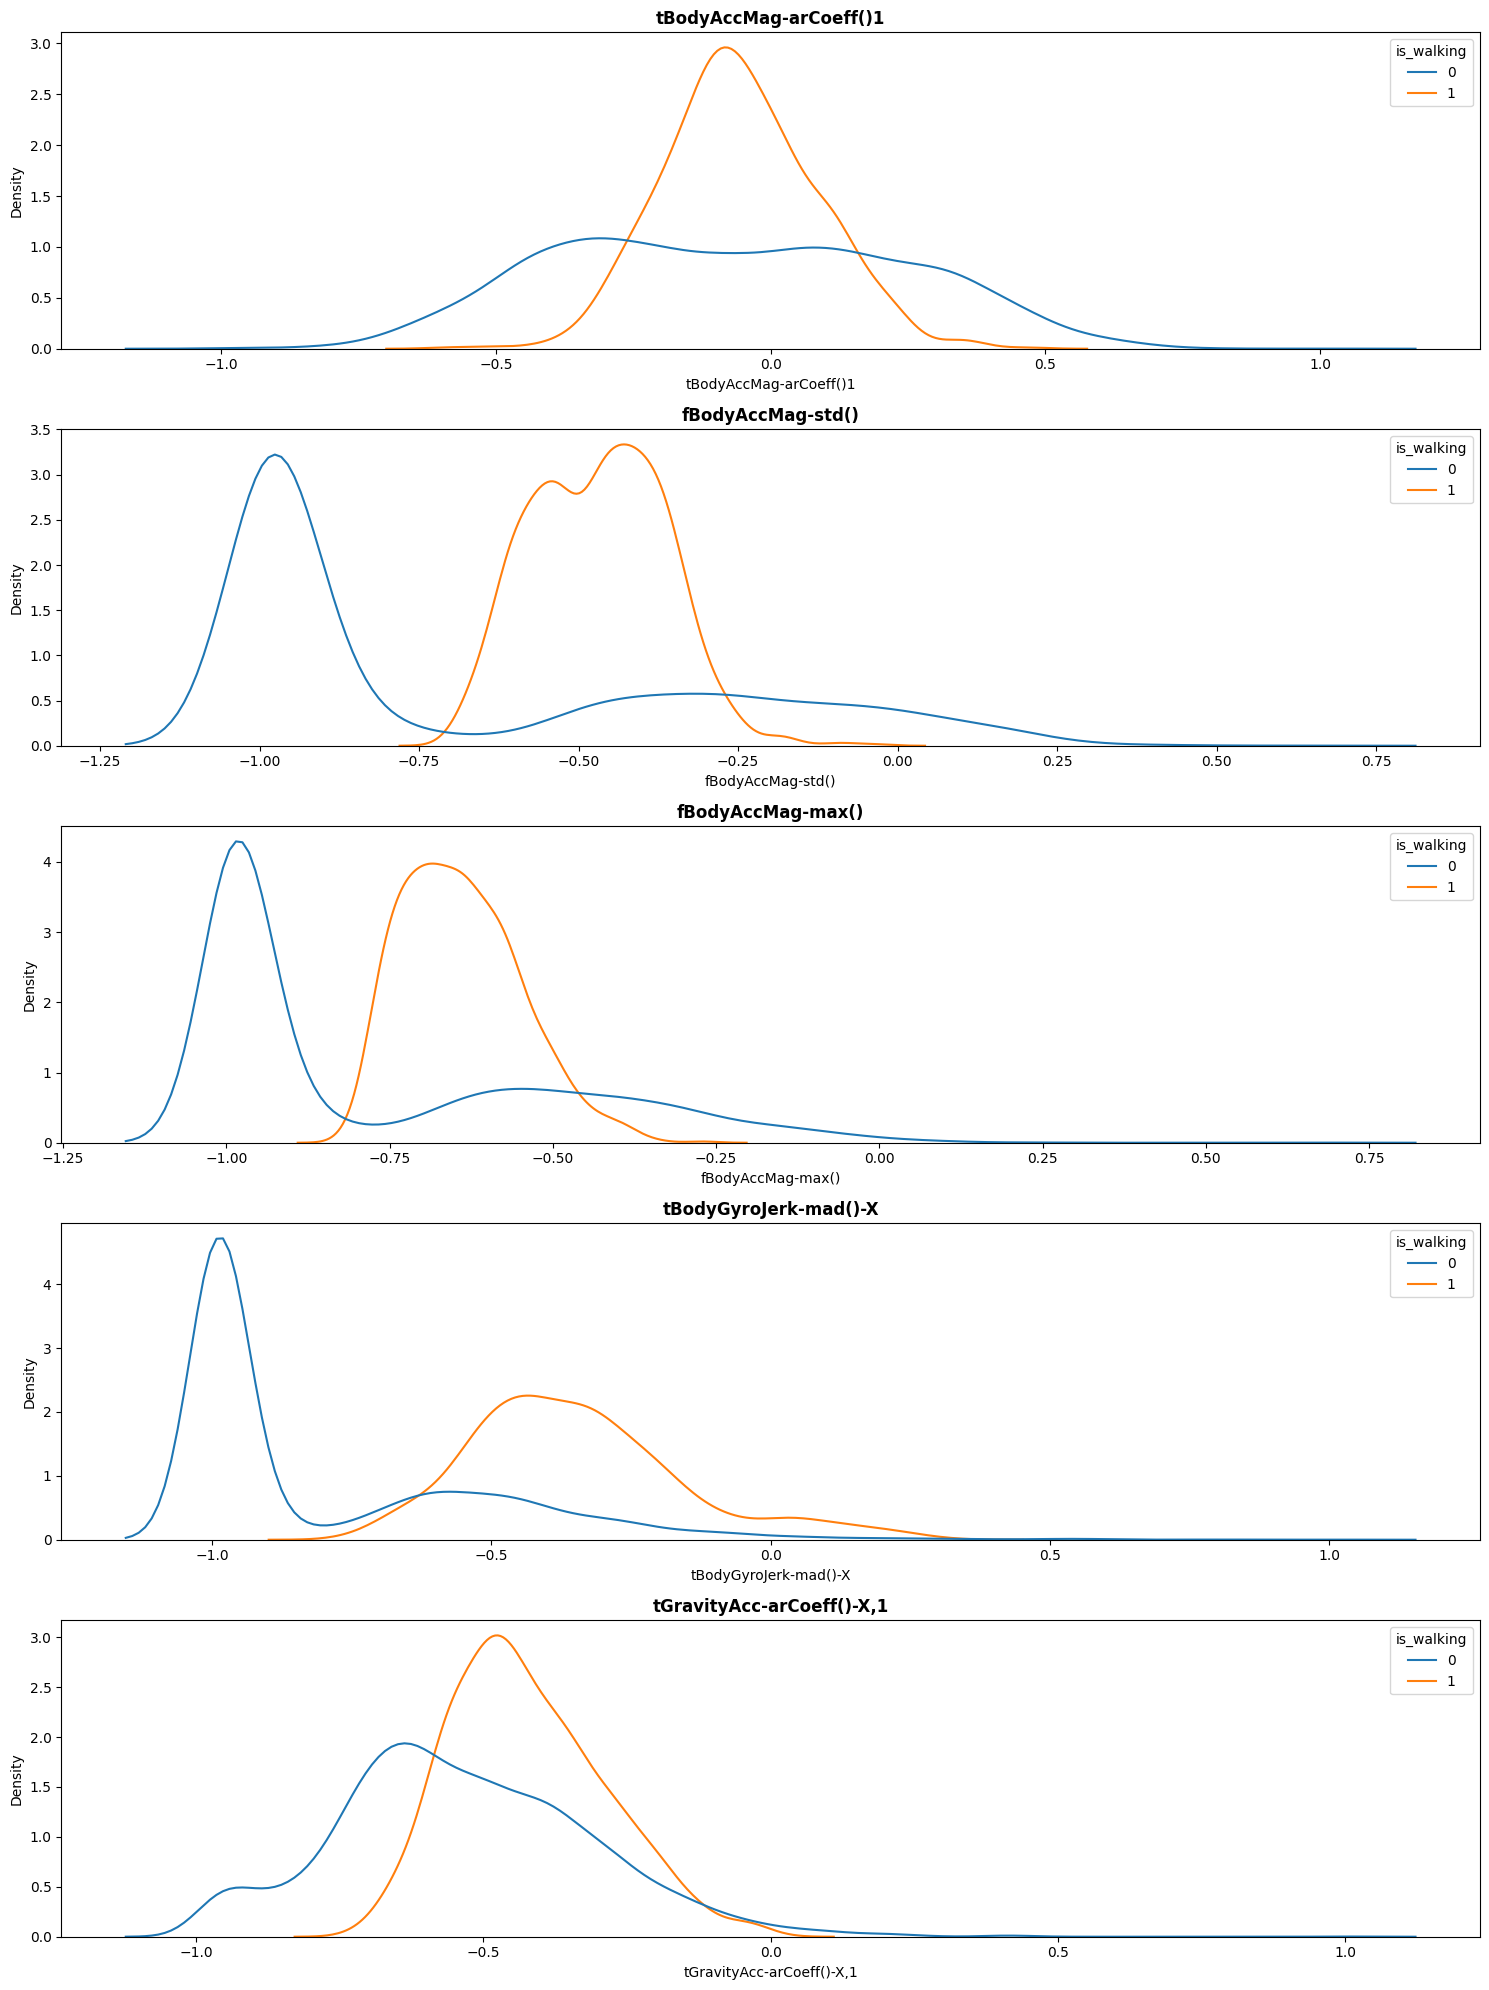

In [88]:
# 중요도 상위 5개 정보에 대한 분석
fig, ax = plt.subplots(5, figsize=(15,20))
for i in range(5):
    var = r6.iloc[i, 0]
    sns.kdeplot(x=var, data=data, hue=target, common_norm=False, ax=ax[i])
    ax[i].set_title(f'{var}', fontweight='bold')
plt.tight_layout()
plt.show()

In [89]:
is_walking_result = pd.merge(features, r6, how='inner', on='feature_name')
is_walking_result

,sensor,agg,axis,feature_name,feature_importance
0,tBodyAcc,mean(),X,tBodyAcc-mean()-X,0.000469
1,tBodyAcc,mean(),Y,tBodyAcc-mean()-Y,0.000257
2,tBodyAcc,mean(),Z,tBodyAcc-mean()-Z,0.000197
3,tBodyAcc,std(),X,tBodyAcc-std()-X,0.007568
4,tBodyAcc,std(),Y,tBodyAcc-std()-Y,0.000149
...,...,...,...,...,...
556,angle,tBodyGyroMean,gravityMean,"angle(tBodyGyroMean,gravityMean)",0.000459
557,angle,tBodyGyroJerkMean,gravityMean,"angle(tBodyGyroJerkMean,gravityMean)",0.000230
558,angle,X,gravityMean,"angle(X,gravityMean)",0.001221
559,angle,Y,gravityMean,"angle(Y,gravityMean)",0.004129


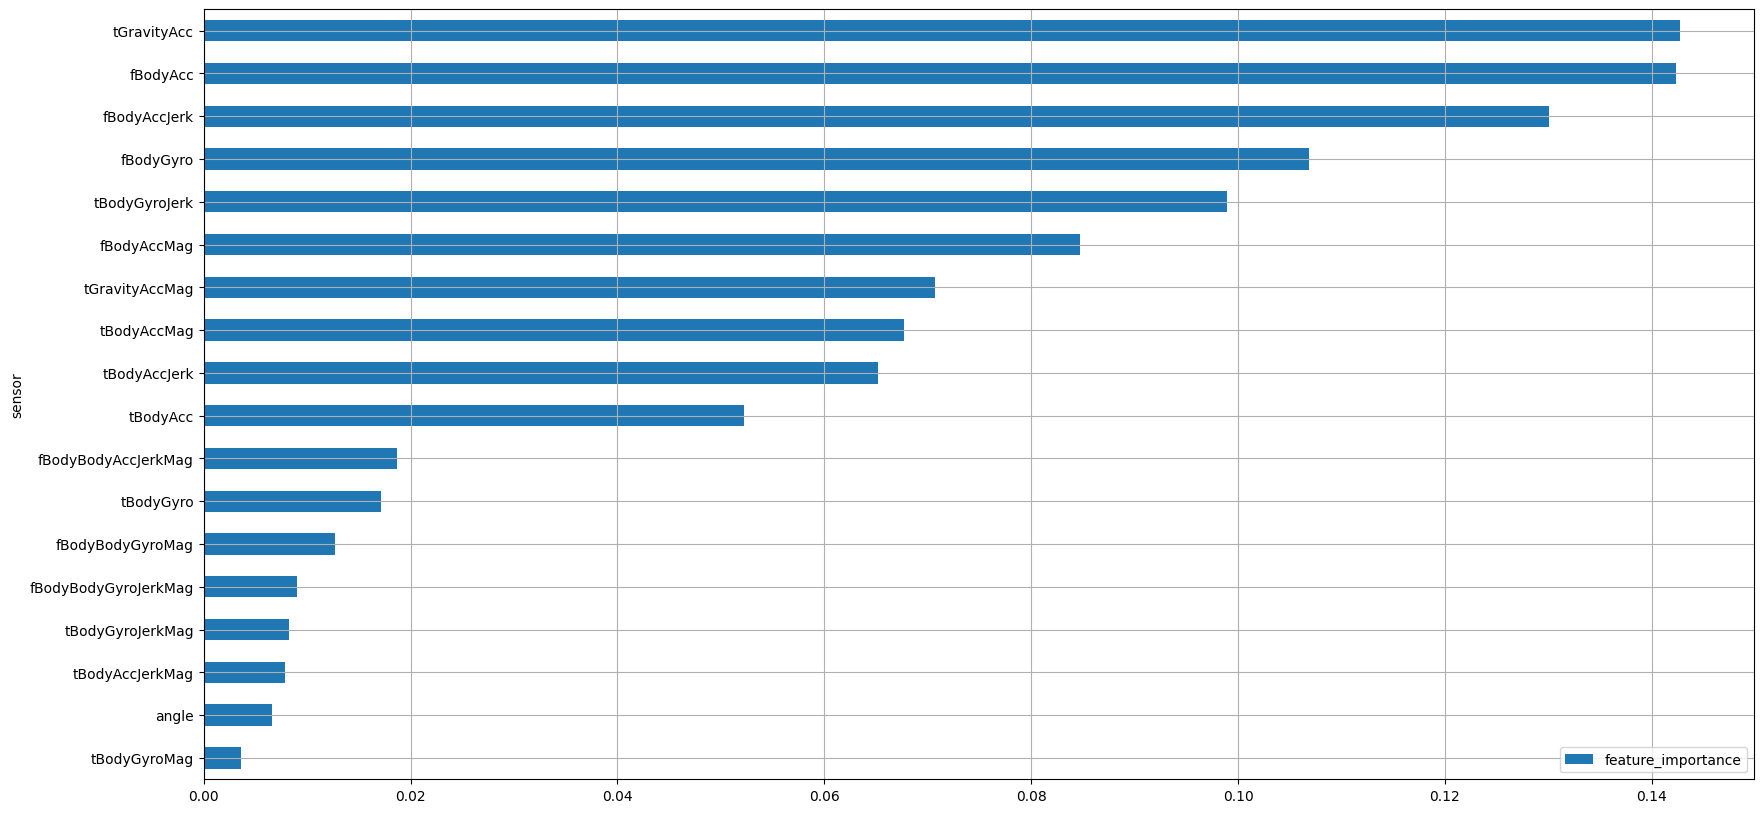

In [90]:
is_walking_result.groupby('sensor')[['feature_importance']].sum().sort_values('feature_importance').plot.barh(figsize=(20,10))
plt.grid()
plt.show()

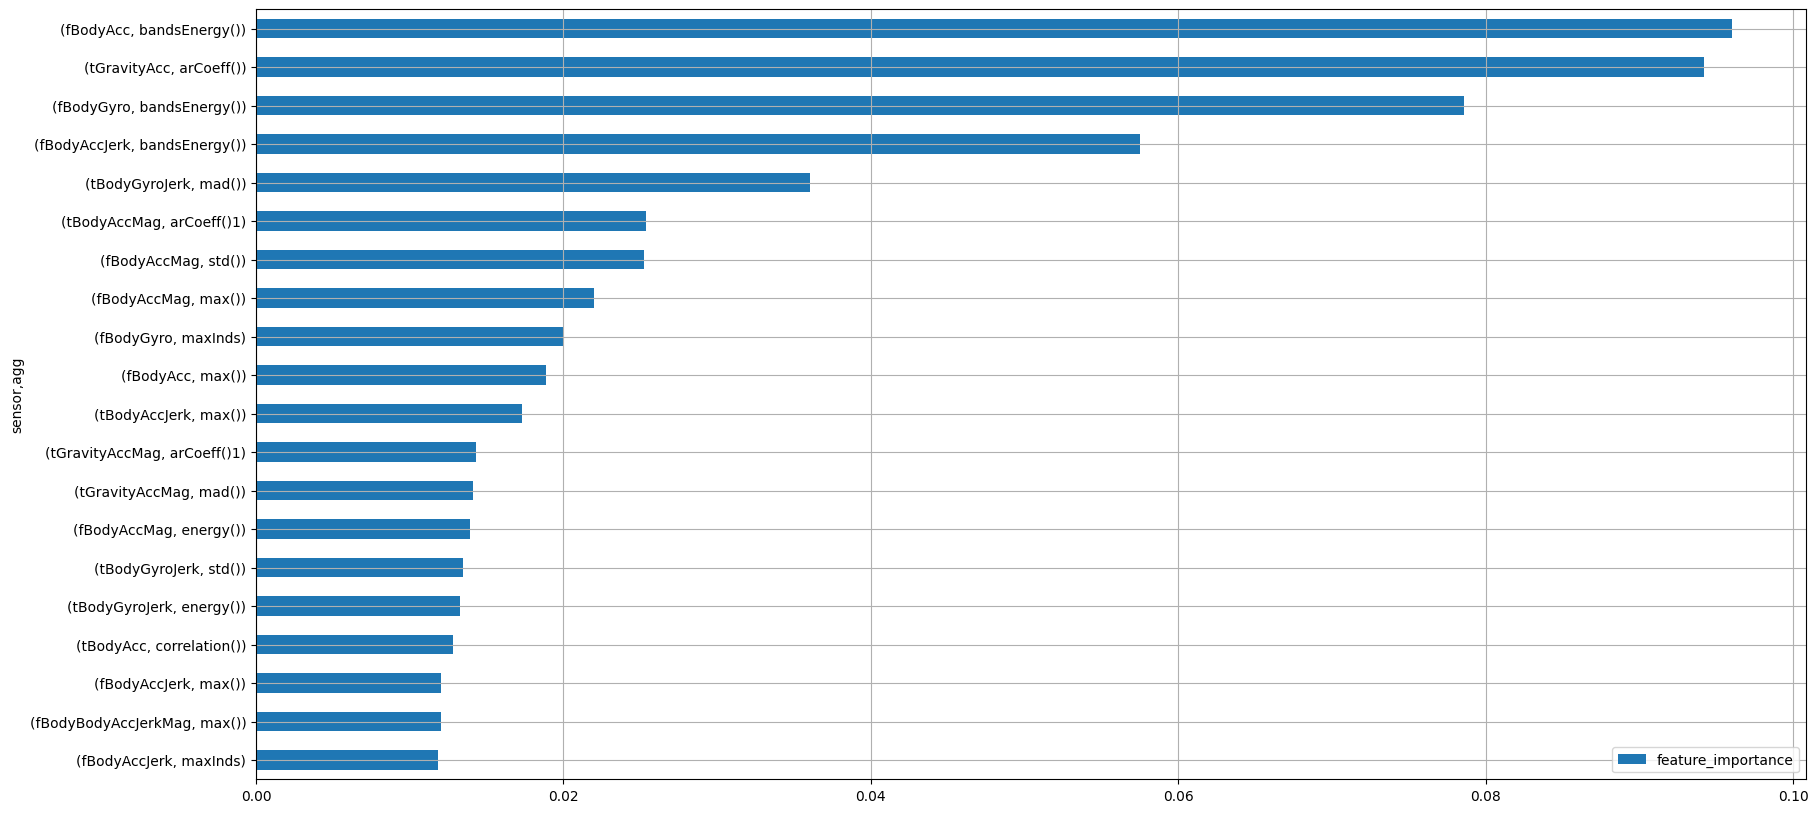

In [91]:
temp = is_walking_result.groupby(['sensor', 'agg'])[['feature_importance']].sum().sort_values('feature_importance')
temp.tail(20).plot.barh(figsize=(20,10))
plt.grid()
plt.show()

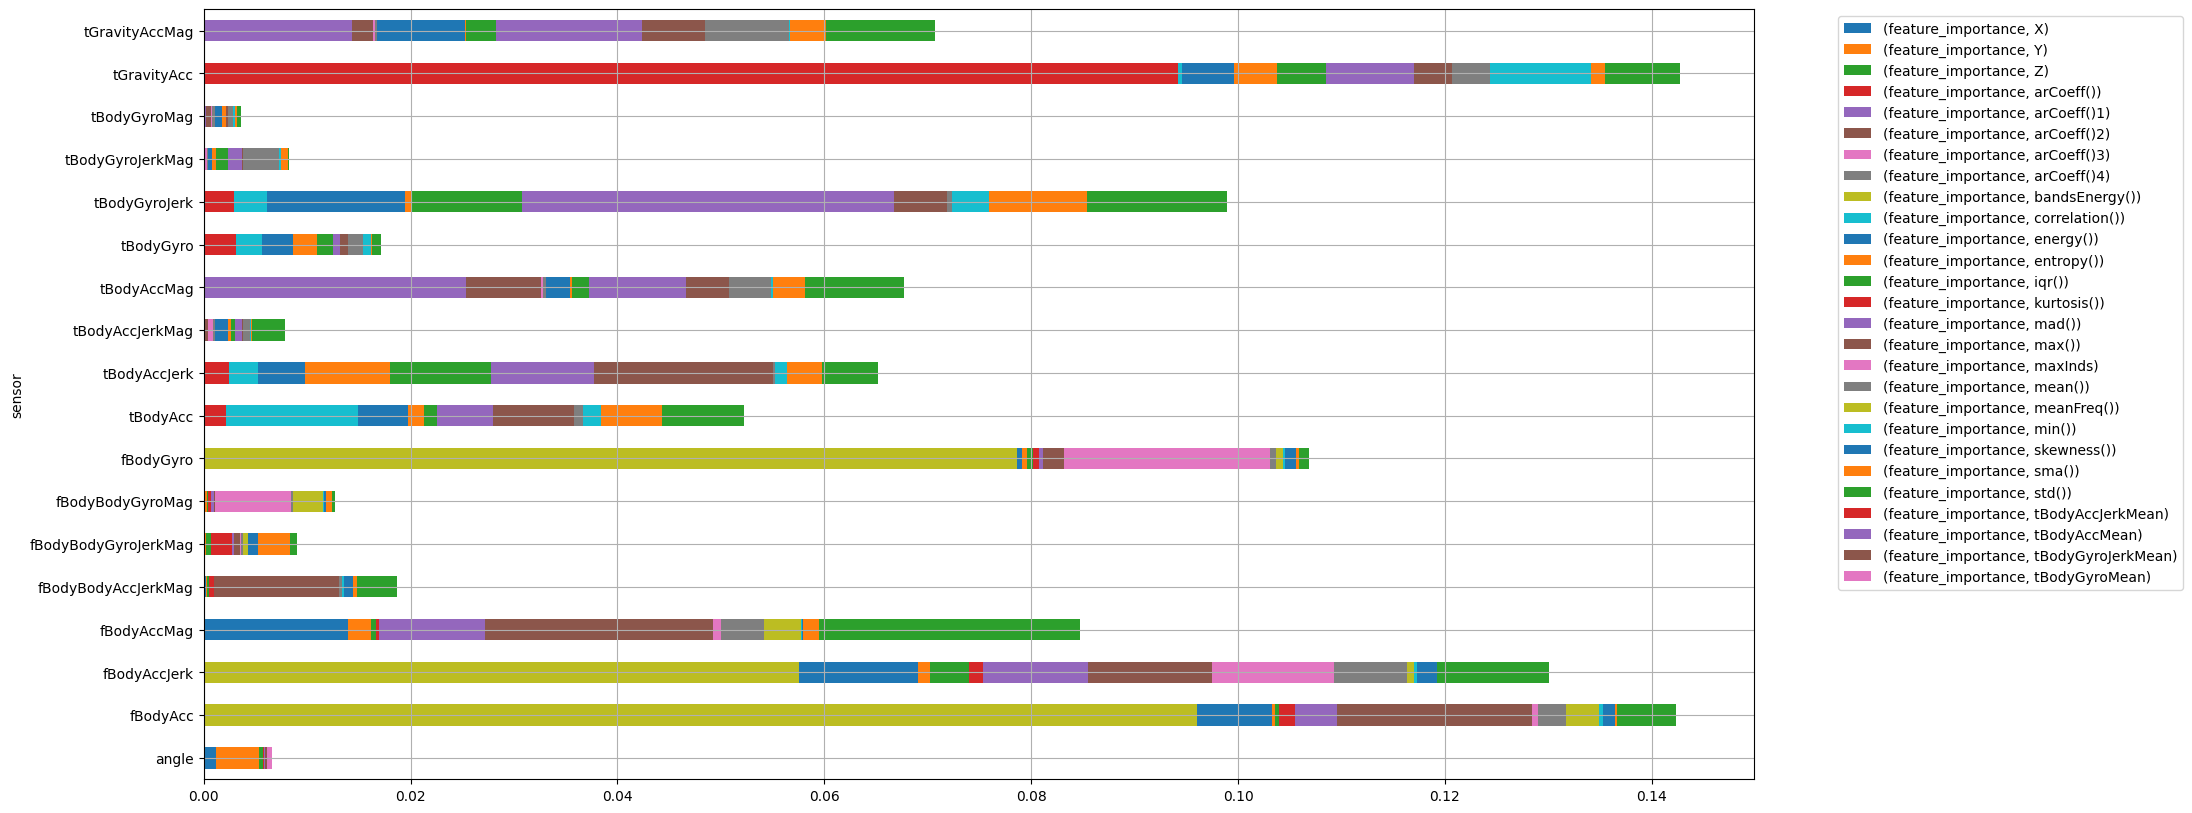

In [92]:
is_walking_result.groupby(['sensor', 'agg'])[['feature_importance']].sum().unstack().plot(kind='barh', stacked=True, figsize=(20,10))
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid()
plt.show()

In [93]:
# 중요도 상위 변수 몇개만 가지고 다시 모델링

# 데이터 분할을 위한 전처리
target = 'is_walking'
non_feature_list.append(target)

x = data[r6.iloc[:10, 0]]
y = data.loc[:, target]

x_train, x_val, y_train, y_val = train_test_split(x, y, test_size = .3, random_state=42)

#생성
model_06 = RandomForestClassifier(random_state=42)

#학습
model_06.fit(x_train, y_train)
pred = model_06.predict(x_val)

#평가
print('accuracy :',accuracy_score(y_val, pred))
print('='*60)
print(confusion_matrix(y_val, pred))
print('='*60)
print(classification_report(y_val, pred))

accuracy : 0.9841359773371104
[[1459   14]
 [  14  278]]
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1473
           1       0.95      0.95      0.95       292

    accuracy                           0.98      1765
   macro avg       0.97      0.97      0.97      1765
weighted avg       0.98      0.98      0.98      1765



### (6) 개별 동작 분석 : is_walking_up


* **세부 요구사항**
    - Target인 Activity를 is_walking_up 변수로 변경하시오.
        * 값 1 : WALKING_UPSTAIRS
        * 값 0 : 나머지
    - is_walking_up 을 예측하기 위한 기본 모델을 생성하시오.
        * x, is_walking_up 을 이용하여 train과 validation으로 데이터 분할
        * 기본 모델링
    - is_walking_up 을 구분하는데 중요한 변수 상위 5를 분석하시오.
    - is_walking_up 을 구분하는데 중요한 변수 그룹을 분석하시오.
        * sensor별
        * sensor+agg 별


1) is_walking_up 추가

In [94]:
data['is_walking_up'] = data['Activity'].map(lambda x: 1 if x == 'WALKING_UPSTAIRS' else 0)
data

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,"angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity,is_dynamic,is_standing,is_sitting,is_laying,is_walking,is_walking_up
0,0.288508,-0.009196,-0.103362,-0.988986,-0.962797,-0.967422,-0.989000,-0.962596,-0.965650,-0.929747,...,-0.601120,0.331298,0.165163,STANDING,0,1,0,0,0,0
1,0.265757,-0.016576,-0.098163,-0.989551,-0.994636,-0.987435,-0.990189,-0.993870,-0.987558,-0.937337,...,0.345205,-0.769186,-0.147944,LAYING,0,0,0,1,0,0
2,0.278709,-0.014511,-0.108717,-0.997720,-0.981088,-0.994008,-0.997934,-0.982187,-0.995017,-0.942584,...,-0.833564,0.202434,-0.032755,STANDING,0,1,0,0,0,0
3,0.289795,-0.035536,-0.150354,-0.231727,-0.006412,-0.338117,-0.273557,0.014245,-0.347916,0.008288,...,-0.695819,0.287154,0.111388,WALKING,1,0,0,0,1,0
4,0.394807,0.034098,0.091229,0.088489,-0.106636,-0.388502,-0.010469,-0.109680,-0.346372,0.584131,...,-0.705029,0.264952,0.137758,WALKING_DOWNSTAIRS,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5876,0.277194,-0.012389,-0.131974,-0.994046,-0.940578,-0.917337,-0.994261,-0.932830,-0.908088,-0.936219,...,-0.912365,0.114009,0.080146,SITTING,0,0,1,0,0,0
5877,0.191568,0.013328,-0.105174,-0.126969,-0.121729,-0.327480,-0.192523,-0.109923,-0.295286,0.078644,...,-0.690278,0.303194,-0.044188,WALKING_UPSTAIRS,1,0,0,0,0,1
5878,0.267981,-0.018348,-0.107440,-0.991303,-0.989881,-0.990313,-0.992386,-0.988852,-0.991237,-0.936099,...,0.620363,-0.437247,-0.571840,LAYING,0,0,0,1,0,0
5879,0.212787,-0.048130,-0.121001,-0.041373,0.052449,-0.585361,-0.100714,0.023353,-0.554707,0.219814,...,-0.718009,0.292856,0.024920,WALKING_UPSTAIRS,1,0,0,0,0,1


2) 기본모델 생성

In [95]:
# 데이터 분할을 위한 전처리
target = 'is_walking_up'
non_feature_list.append(target)

x = data.drop(non_feature_list, axis = 1)
y = data.loc[:, target]

x_train, x_val, y_train, y_val = train_test_split(x, y, test_size = .3,random_state=42)

In [96]:
#생성
model_07 = RandomForestClassifier(random_state=42)

#학습
model_07.fit(x_train, y_train)
pred = model_07.predict(x_val)

#평가
print('accuracy :',accuracy_score(y_val, pred))
print('='*60)
print(confusion_matrix(y_val, pred))
print('='*60)
print(classification_report(y_val, pred))

accuracy : 0.9943342776203966
[[1485    3]
 [   7  270]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1488
           1       0.99      0.97      0.98       277

    accuracy                           0.99      1765
   macro avg       0.99      0.99      0.99      1765
weighted avg       0.99      0.99      0.99      1765



3) 변수중요도 상위 5개 분석

In [97]:
r7 = plot_feature_importance(model_07.feature_importances_, list(x_train), False)
r7

Output hidden; open in https://colab.research.google.com to view.

In [98]:
r7.head()

,feature_name,feature_importance
0,"tGravityAcc-arCoeff()-Z,1",0.044977
1,"tGravityAcc-arCoeff()-Z,2",0.026117
2,tGravityAcc-min()-Y,0.025103
3,tGravityAcc-mean()-Y,0.023510
4,"tGravityAcc-arCoeff()-Z,3",0.021600


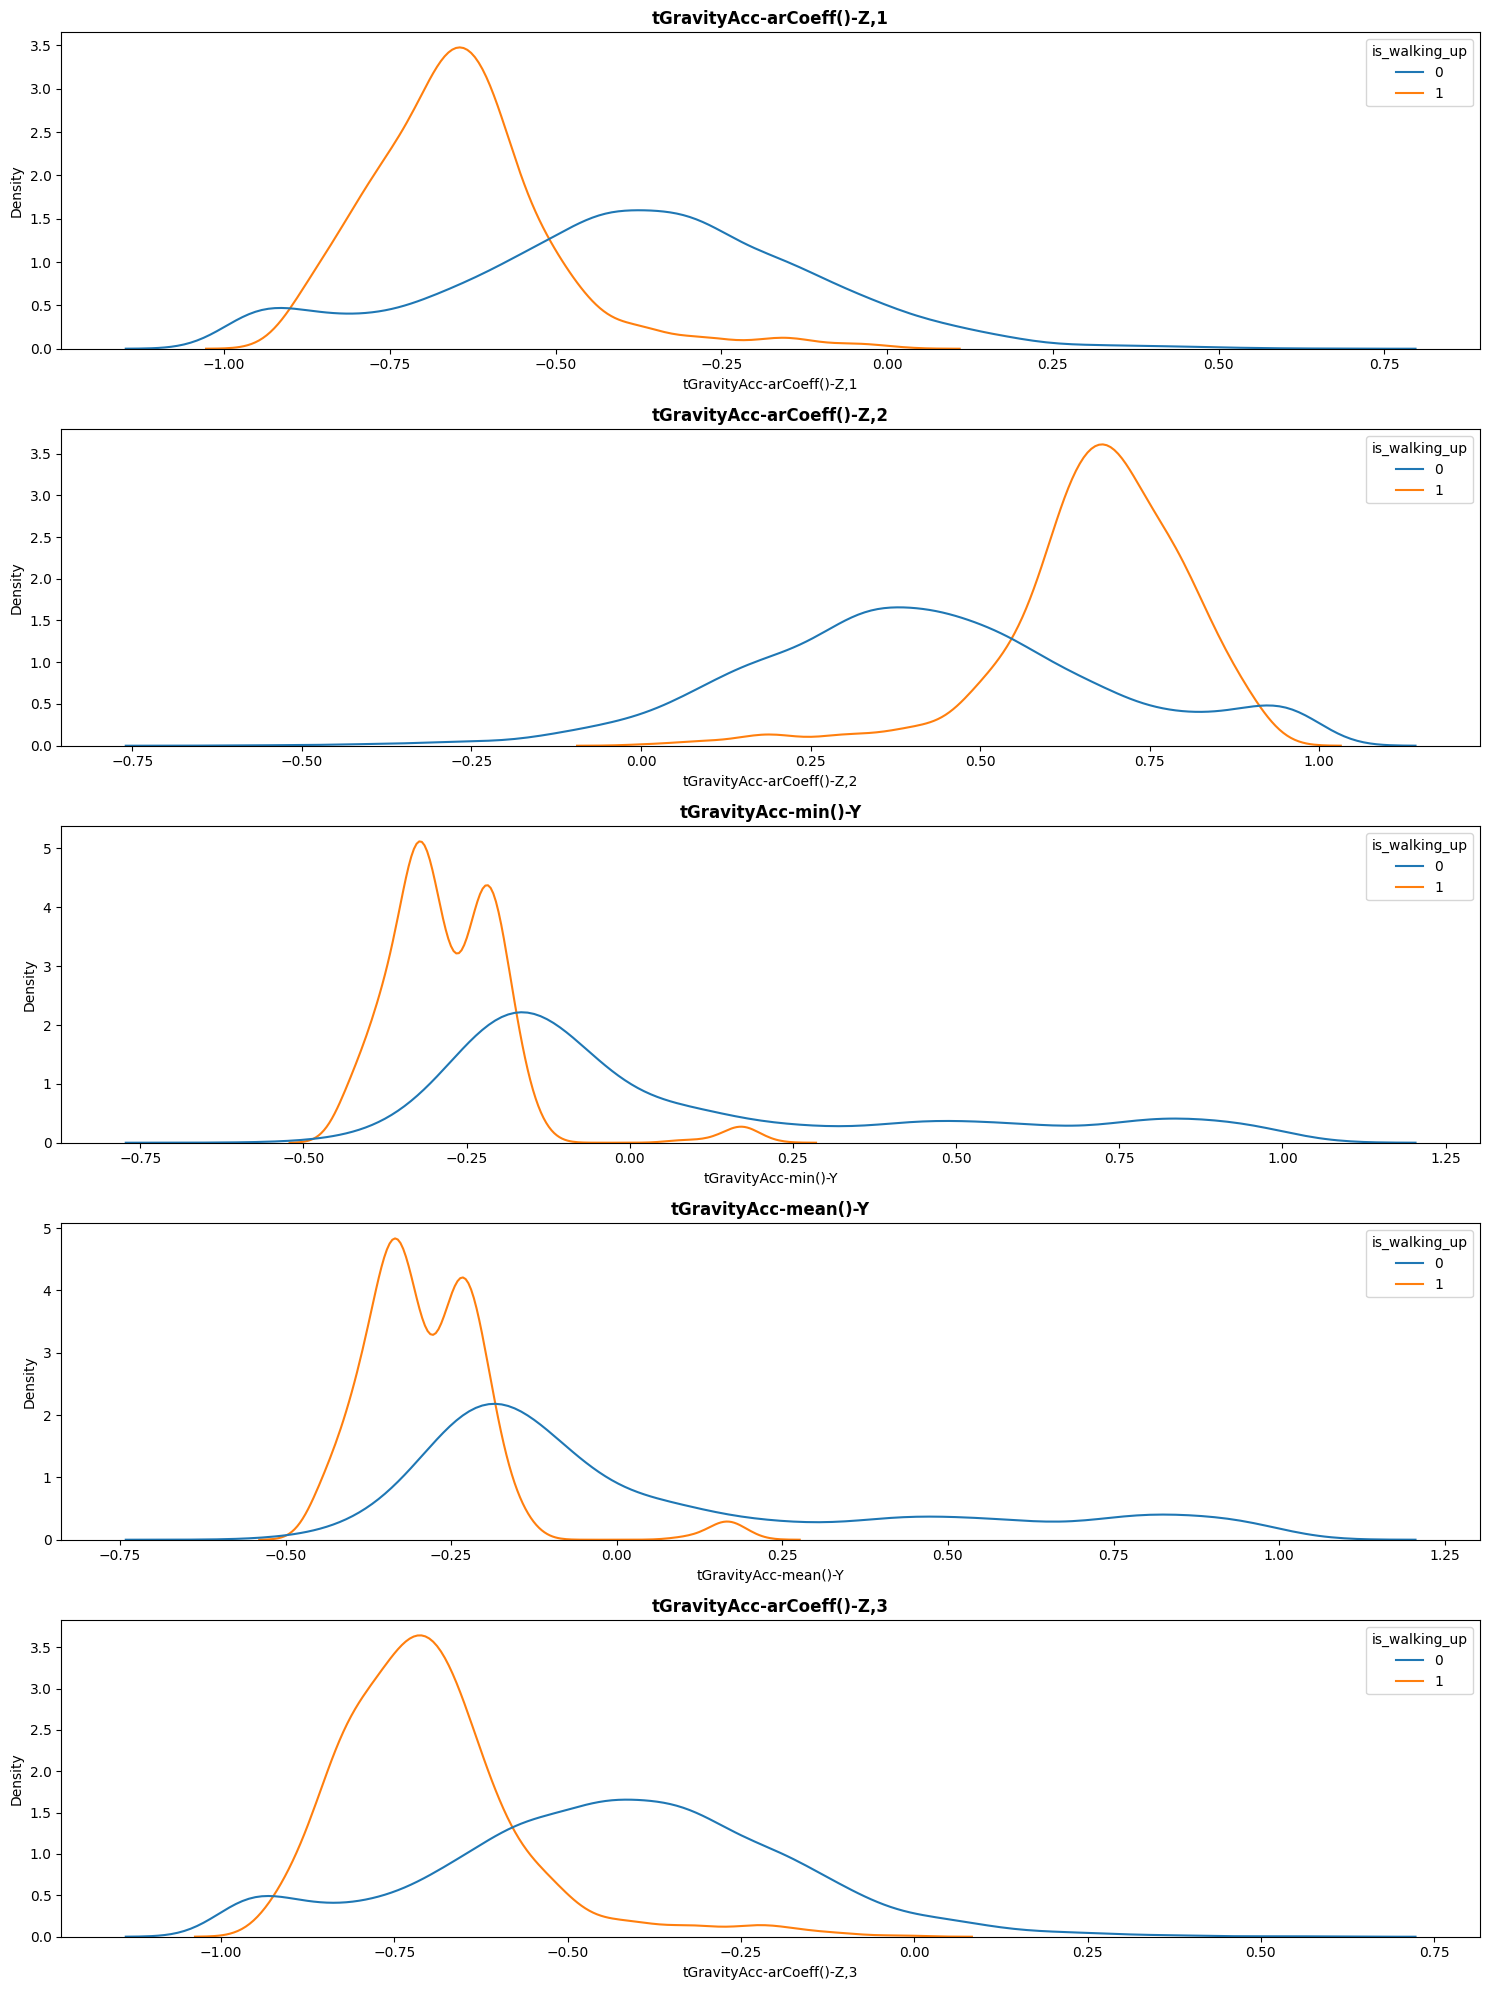

In [99]:
# 중요도 상위 5개 정보에 대한 분석
fig, ax = plt.subplots(5, figsize=(15,20))
for i in range(5):
    var = r7.iloc[i, 0]
    sns.kdeplot(x=var, data=data, hue=target, common_norm=False, ax=ax[i])
    ax[i].set_title(f'{var}', fontweight='bold')
plt.tight_layout()
plt.show()


In [100]:
is_walking_up_result = pd.merge(features, r7, how='inner', on='feature_name')
is_walking_up_result

,sensor,agg,axis,feature_name,feature_importance
0,tBodyAcc,mean(),X,tBodyAcc-mean()-X,0.000190
1,tBodyAcc,mean(),Y,tBodyAcc-mean()-Y,0.000858
2,tBodyAcc,mean(),Z,tBodyAcc-mean()-Z,0.000356
3,tBodyAcc,std(),X,tBodyAcc-std()-X,0.008442
4,tBodyAcc,std(),Y,tBodyAcc-std()-Y,0.000420
...,...,...,...,...,...
556,angle,tBodyGyroMean,gravityMean,"angle(tBodyGyroMean,gravityMean)",0.000793
557,angle,tBodyGyroJerkMean,gravityMean,"angle(tBodyGyroJerkMean,gravityMean)",0.000191
558,angle,X,gravityMean,"angle(X,gravityMean)",0.006986
559,angle,Y,gravityMean,"angle(Y,gravityMean)",0.015373


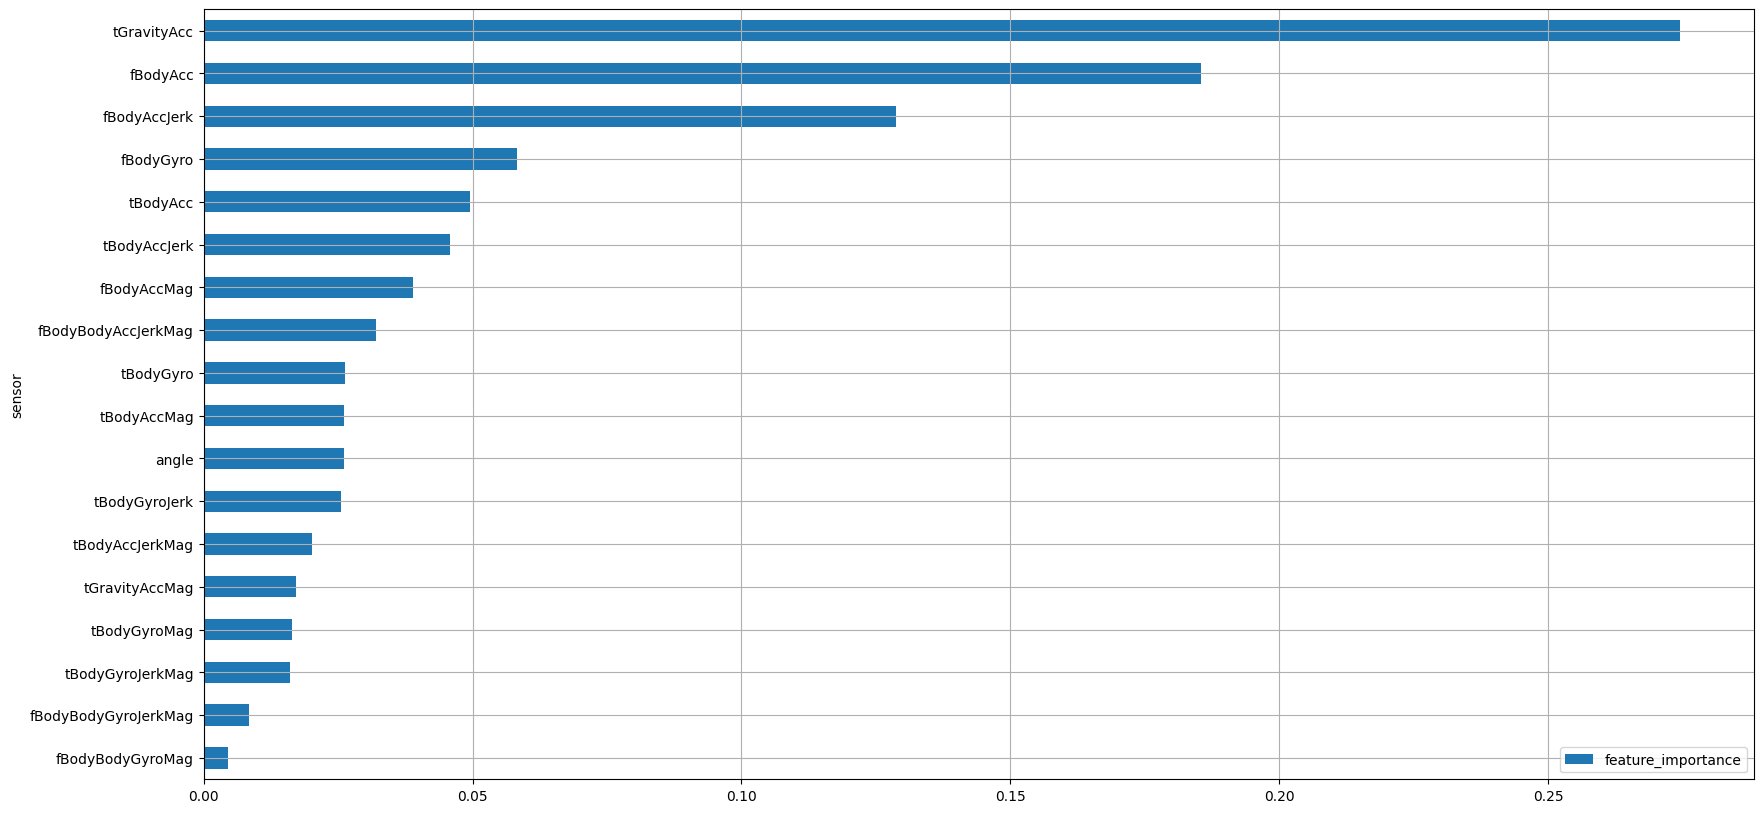

In [101]:
is_walking_up_result.groupby('sensor')[['feature_importance']].sum().sort_values('feature_importance').plot.barh(figsize=(20,10))
plt.grid()
plt.show()

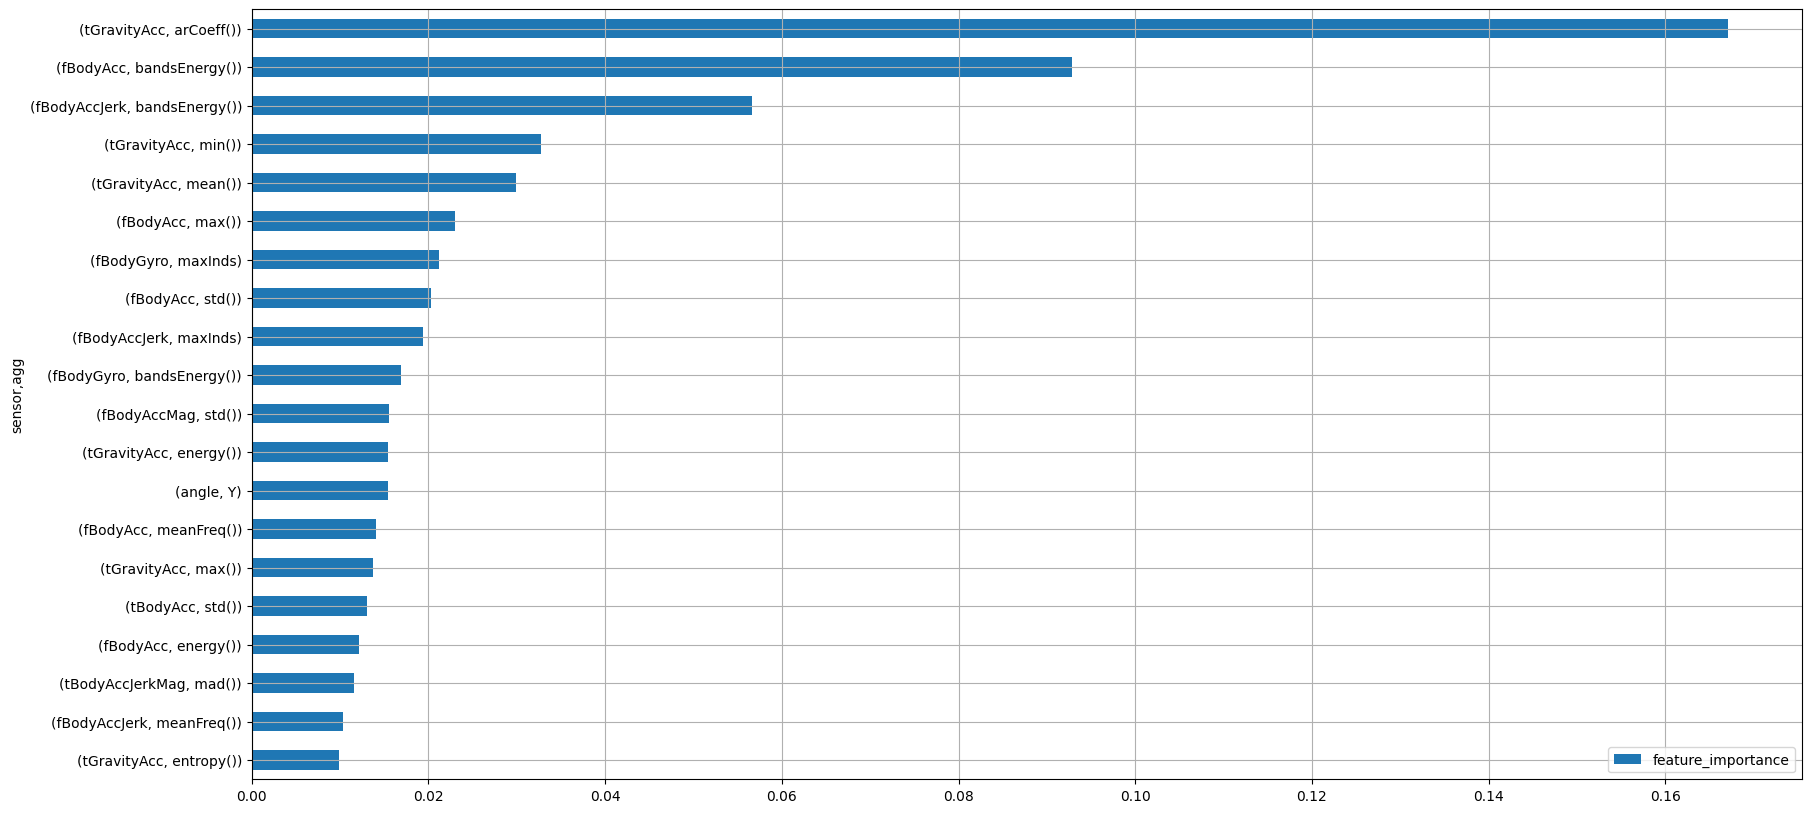

In [102]:
temp = is_walking_up_result.groupby(['sensor', 'agg'])[['feature_importance']].sum().sort_values('feature_importance')
temp.tail(20).plot.barh(figsize=(20,10))
plt.grid()
plt.show()

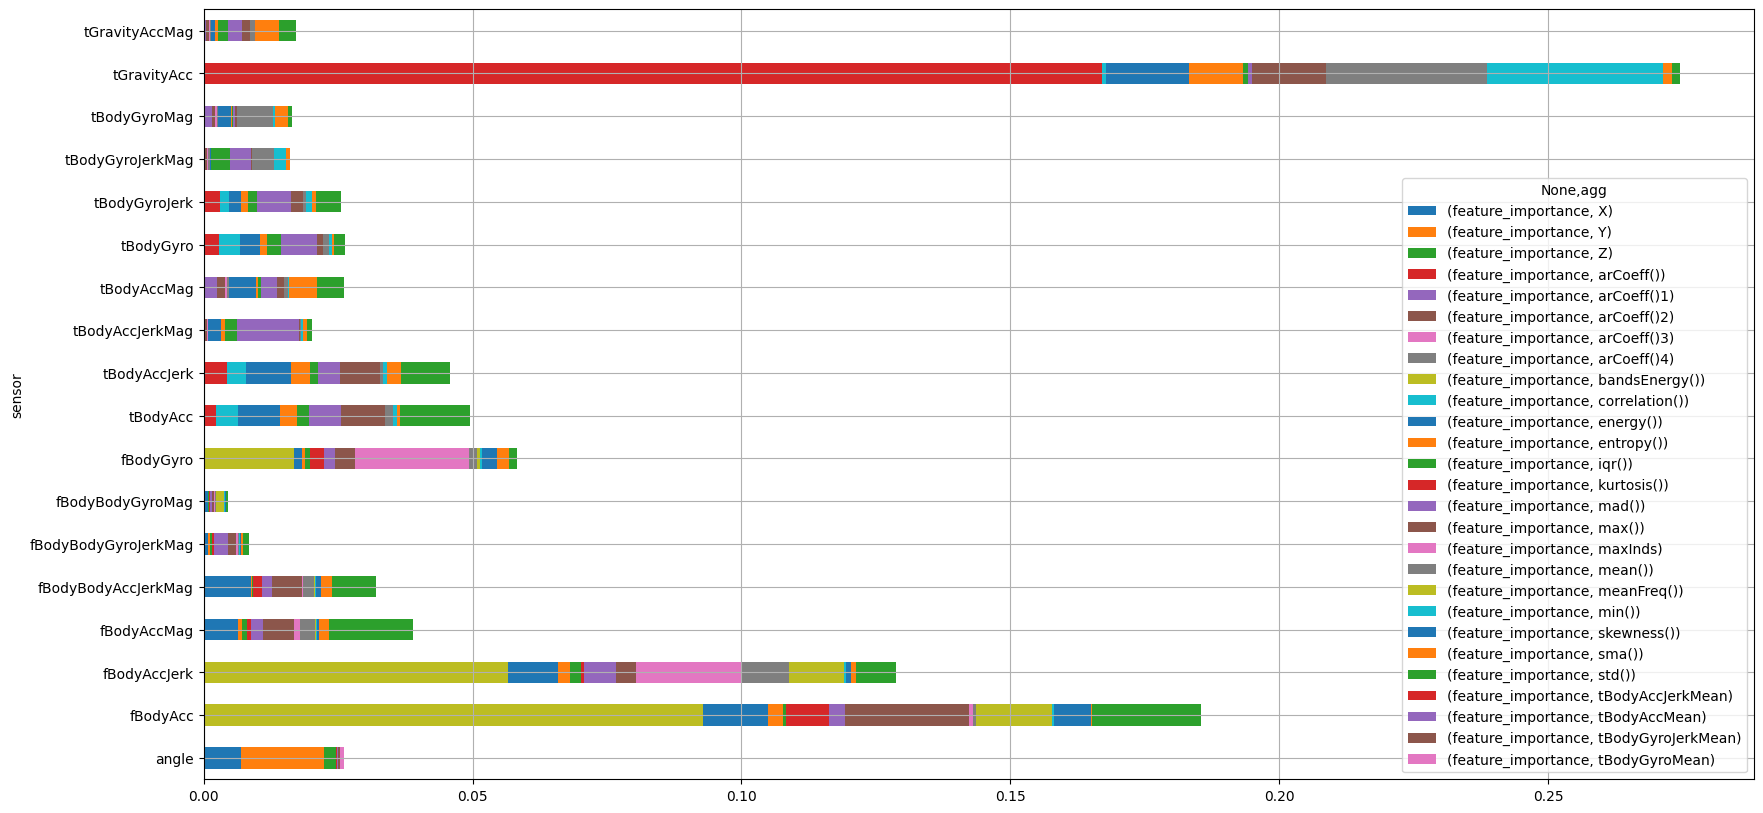

In [103]:
is_walking_up_result.groupby(['sensor', 'agg'])[['feature_importance']].sum().unstack().plot(kind='barh', stacked=True, figsize=(20,10))
plt.grid()
plt.show()

In [104]:
# 중요도 상위 변수 몇개만 가지고 다시 모델링

# 데이터 분할을 위한 전처리
target = 'is_walking_up'
non_feature_list.append(target)

x = data[r7.iloc[:10, 0]]
y = data.loc[:, target]

x_train, x_val, y_train, y_val = train_test_split(x, y, test_size = .3, random_state=42)

#생성
model_07 = RandomForestClassifier(random_state=42)

#학습
model_07.fit(x_train, y_train)
pred = model_07.predict(x_val)

#평가
print('accuracy :',accuracy_score(y_val, pred))
print('='*60)
print(confusion_matrix(y_val, pred))
print('='*60)
print(classification_report(y_val, pred))

accuracy : 0.9886685552407932
[[1478   10]
 [  10  267]]
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1488
           1       0.96      0.96      0.96       277

    accuracy                           0.99      1765
   macro avg       0.98      0.98      0.98      1765
weighted avg       0.99      0.99      0.99      1765



### (7) 개별 동작 분석 : is_walking_down


* **세부 요구사항**
    - Target인 Activity를 is_walking_down 변수로 변경하시오.
        * 값 1 : WALKING_DOWNSTAIRS
        * 값 0 : 나머지
    - is_walking_down 을 예측하기 위한 기본 모델을 생성하시오.
        * x, is_walking_down 을 이용하여 train과 validation으로 데이터 분할
        * 기본 모델링
    - is_walking_down 을 구분하는데 중요한 변수 상위 5를 분석하시오.
    - is_walking_down 을 구분하는데 중요한 변수 그룹을 분석하시오.
        * sensor별
        * sensor+agg 별


1) is_walking_down 추가

In [105]:
data['is_walking_down'] = data['Activity'].map(lambda x: 1 if x == 'WALKING_DOWNSTAIRS' else 0)
data

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,"angle(Y,gravityMean)","angle(Z,gravityMean)",Activity,is_dynamic,is_standing,is_sitting,is_laying,is_walking,is_walking_up,is_walking_down
0,0.288508,-0.009196,-0.103362,-0.988986,-0.962797,-0.967422,-0.989000,-0.962596,-0.965650,-0.929747,...,0.331298,0.165163,STANDING,0,1,0,0,0,0,0
1,0.265757,-0.016576,-0.098163,-0.989551,-0.994636,-0.987435,-0.990189,-0.993870,-0.987558,-0.937337,...,-0.769186,-0.147944,LAYING,0,0,0,1,0,0,0
2,0.278709,-0.014511,-0.108717,-0.997720,-0.981088,-0.994008,-0.997934,-0.982187,-0.995017,-0.942584,...,0.202434,-0.032755,STANDING,0,1,0,0,0,0,0
3,0.289795,-0.035536,-0.150354,-0.231727,-0.006412,-0.338117,-0.273557,0.014245,-0.347916,0.008288,...,0.287154,0.111388,WALKING,1,0,0,0,1,0,0
4,0.394807,0.034098,0.091229,0.088489,-0.106636,-0.388502,-0.010469,-0.109680,-0.346372,0.584131,...,0.264952,0.137758,WALKING_DOWNSTAIRS,1,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5876,0.277194,-0.012389,-0.131974,-0.994046,-0.940578,-0.917337,-0.994261,-0.932830,-0.908088,-0.936219,...,0.114009,0.080146,SITTING,0,0,1,0,0,0,0
5877,0.191568,0.013328,-0.105174,-0.126969,-0.121729,-0.327480,-0.192523,-0.109923,-0.295286,0.078644,...,0.303194,-0.044188,WALKING_UPSTAIRS,1,0,0,0,0,1,0
5878,0.267981,-0.018348,-0.107440,-0.991303,-0.989881,-0.990313,-0.992386,-0.988852,-0.991237,-0.936099,...,-0.437247,-0.571840,LAYING,0,0,0,1,0,0,0
5879,0.212787,-0.048130,-0.121001,-0.041373,0.052449,-0.585361,-0.100714,0.023353,-0.554707,0.219814,...,0.292856,0.024920,WALKING_UPSTAIRS,1,0,0,0,0,1,0


In [106]:
# 데이터 분할을 위한 전처리
target = 'is_walking_down'
non_feature_list.append(target)

x = data.drop(non_feature_list, axis = 1)
y = data.loc[:, target]

x_train, x_val, y_train, y_val = train_test_split(x, y, test_size = .3, random_state=42)

In [107]:
#생성
model_08 = RandomForestClassifier(random_state=42)

#학습
model_08.fit(x_train, y_train)
pred = model_08.predict(x_val)

#평가
print('accuracy :',accuracy_score(y_val, pred))
print('='*60)
print(confusion_matrix(y_val, pred))
print('='*60)
print(classification_report(y_val, pred))

accuracy : 0.9813031161473088
[[1517    9]
 [  24  215]]
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      1526
           1       0.96      0.90      0.93       239

    accuracy                           0.98      1765
   macro avg       0.97      0.95      0.96      1765
weighted avg       0.98      0.98      0.98      1765



In [108]:
r8 = plot_feature_importance(model_08.feature_importances_, list(x_train), False)
r8

Output hidden; open in https://colab.research.google.com to view.

In [109]:
r8.head()

,feature_name,feature_importance
0,tGravityAccMag-std(),0.054439
1,fBodyAccMag-mad(),0.046705
2,tBodyAccMag-std(),0.045353
3,tBodyAcc-energy()-X,0.033338
4,fBodyAccMag-energy(),0.032454


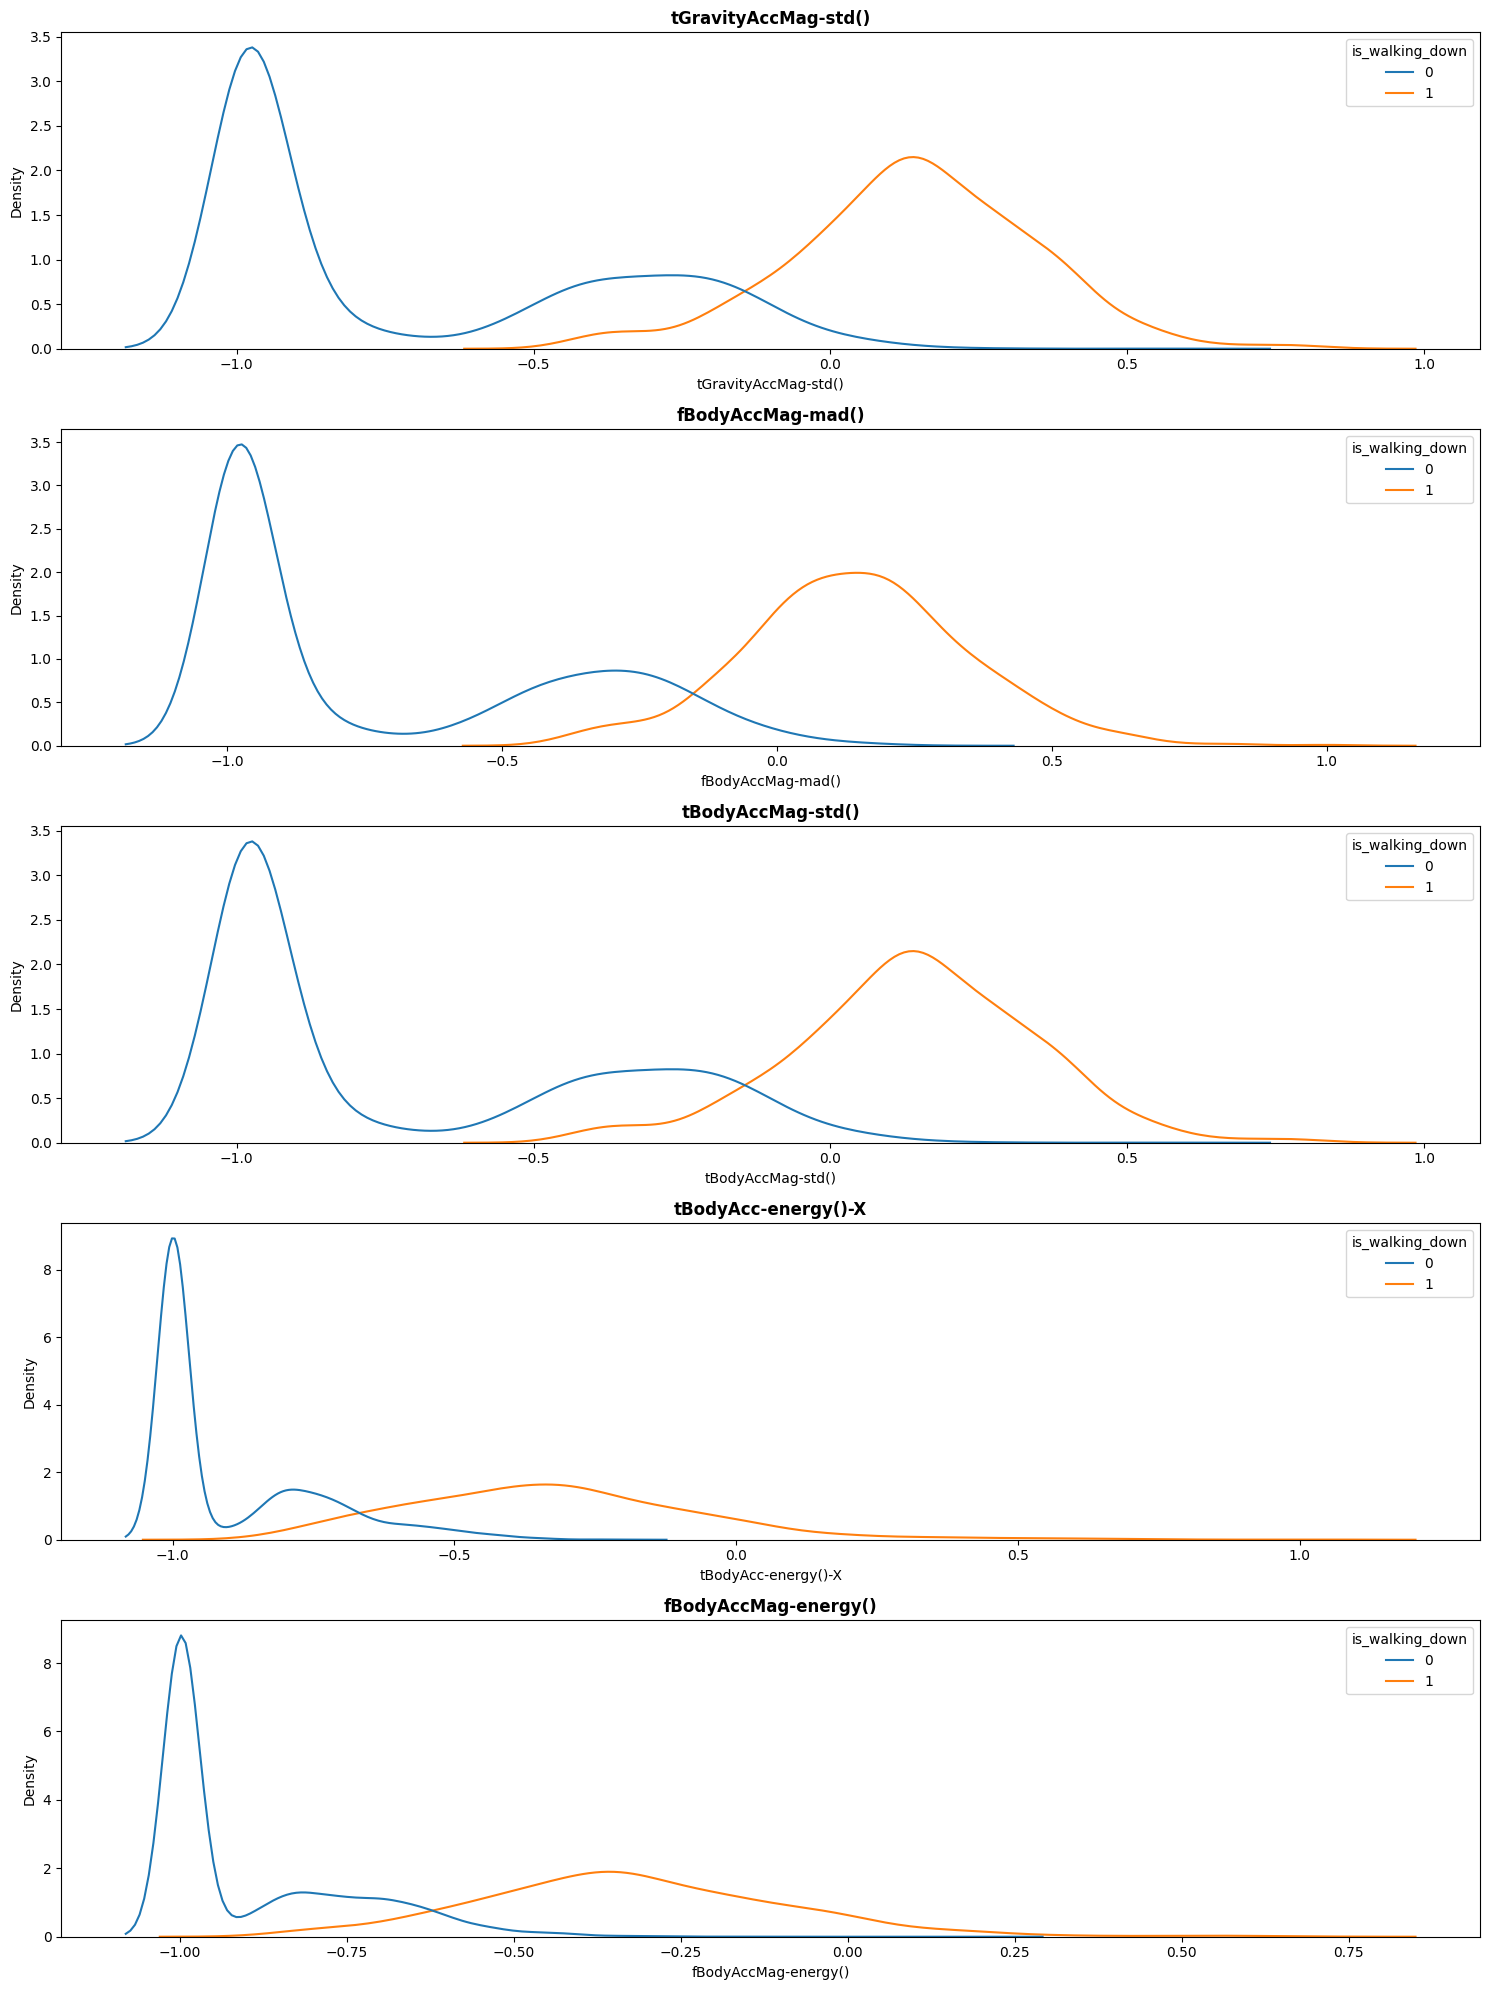

In [110]:
# 중요도 상위 5개 정보에 대한 분석
fig, ax = plt.subplots(5, figsize=(15,20))
for i in range(5):
    var = r8.iloc[i, 0]
    sns.kdeplot(x=var, data=data, hue=target, common_norm=False, ax=ax[i])
    ax[i].set_title(f'{var}', fontweight='bold')
plt.tight_layout()
plt.show()

In [111]:
is_walking_down_result = pd.merge(features, r8, how='inner', on='feature_name')
is_walking_down_result

,sensor,agg,axis,feature_name,feature_importance
0,tBodyAcc,mean(),X,tBodyAcc-mean()-X,0.000378
1,tBodyAcc,mean(),Y,tBodyAcc-mean()-Y,0.000382
2,tBodyAcc,mean(),Z,tBodyAcc-mean()-Z,0.000151
3,tBodyAcc,std(),X,tBodyAcc-std()-X,0.015229
4,tBodyAcc,std(),Y,tBodyAcc-std()-Y,0.000388
...,...,...,...,...,...
556,angle,tBodyGyroMean,gravityMean,"angle(tBodyGyroMean,gravityMean)",0.000322
557,angle,tBodyGyroJerkMean,gravityMean,"angle(tBodyGyroJerkMean,gravityMean)",0.000210
558,angle,X,gravityMean,"angle(X,gravityMean)",0.003343
559,angle,Y,gravityMean,"angle(Y,gravityMean)",0.002439


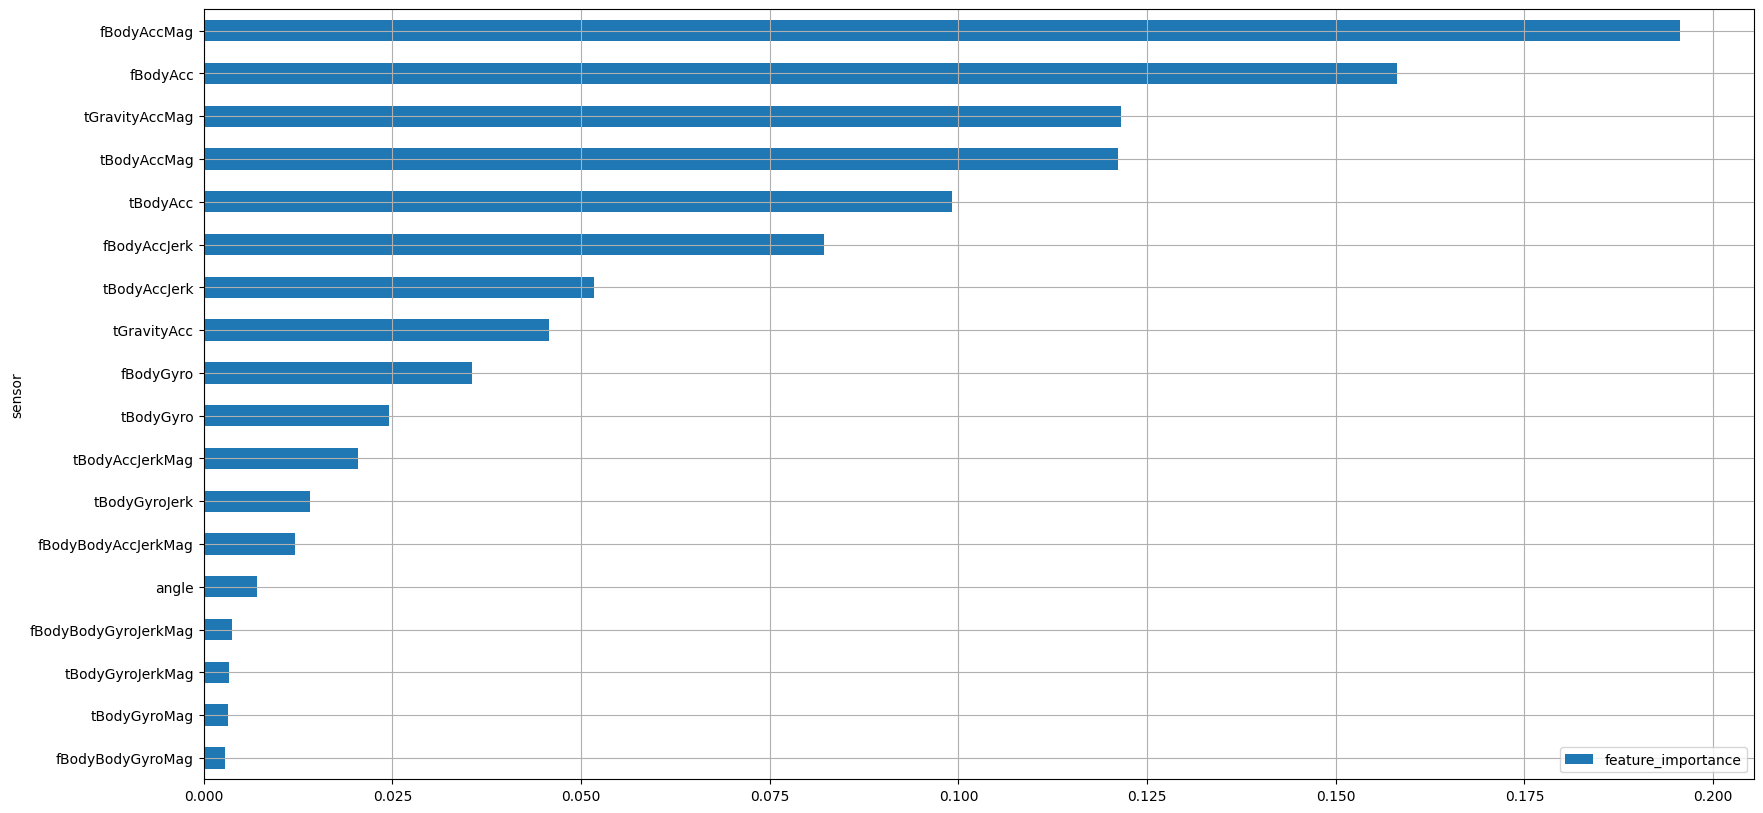

In [112]:
is_walking_down_result.groupby('sensor')[['feature_importance']].sum().sort_values('feature_importance').plot.barh(figsize=(20,10))
plt.grid()
plt.show()

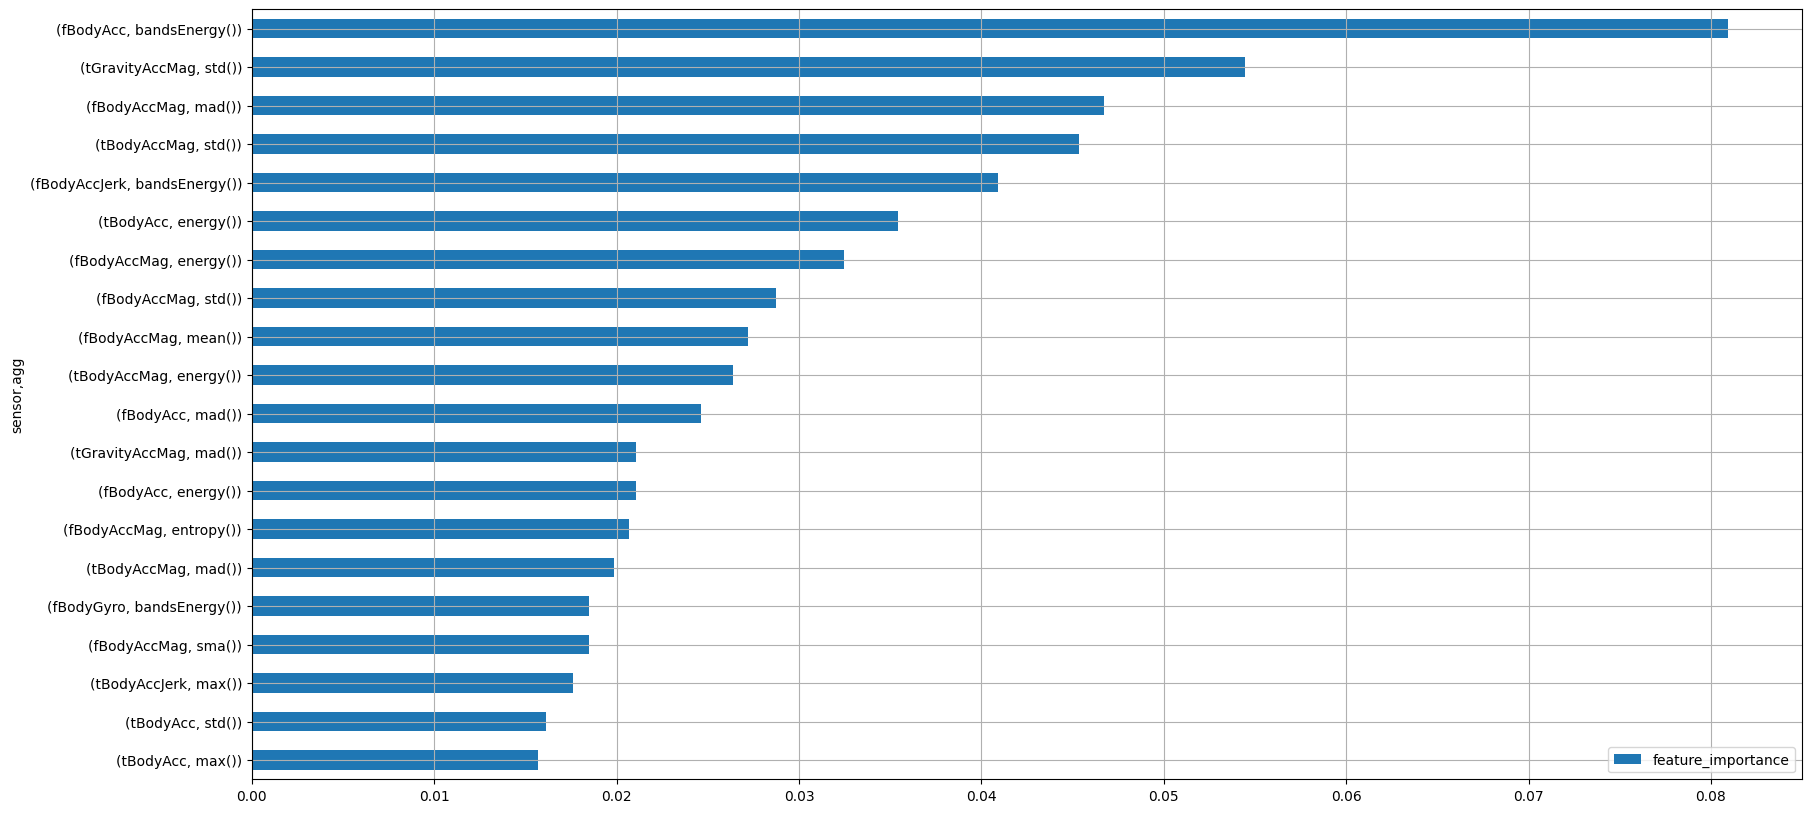

In [113]:
temp = is_walking_down_result.groupby(['sensor', 'agg'])[['feature_importance']].sum().sort_values('feature_importance')
temp.tail(20).plot.barh(figsize=(20,10))
plt.grid()
plt.show()

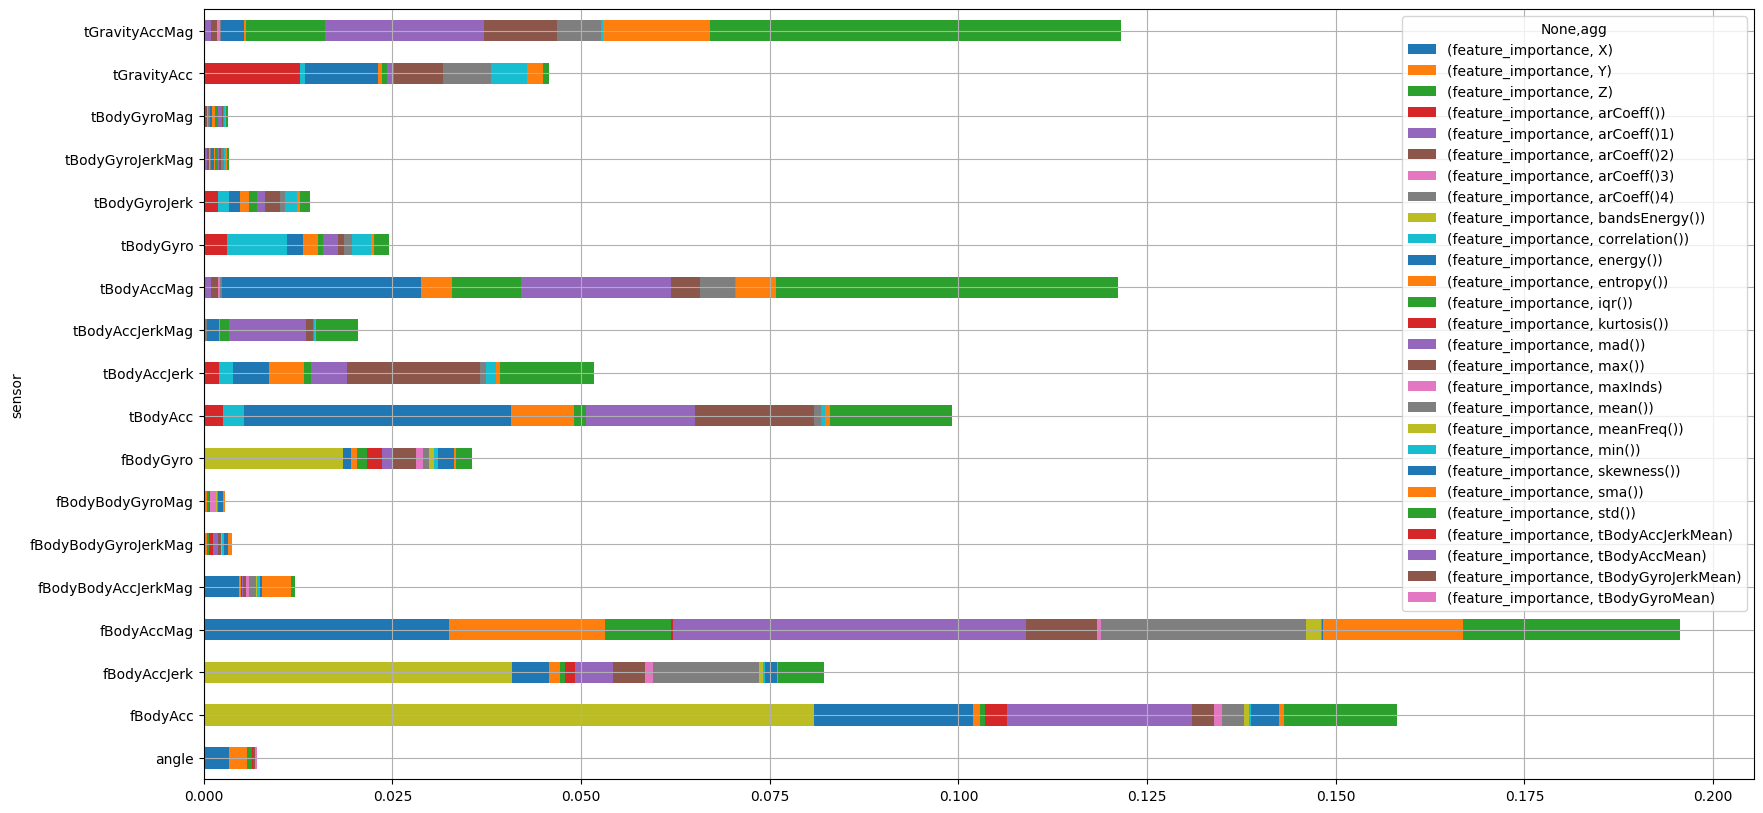

In [114]:
is_walking_down_result.groupby(['sensor', 'agg'])[['feature_importance']].sum().unstack().plot(kind='barh', stacked=True, figsize=(20,10))
plt.grid()
plt.show()

In [115]:
# 중요도 상위 변수 몇개만 가지고 다시 모델링

# 데이터 분할을 위한 전처리
target = 'is_walking_down'
non_feature_list.append(target)

x = data[r8.iloc[:10, 0]]
y = data.loc[:, target]

x_train, x_val, y_train, y_val = train_test_split(x, y, test_size = .3, random_state=42)

#생성
model_08 = RandomForestClassifier(random_state=42)

#학습
model_08.fit(x_train, y_train)
pred = model_08.predict(x_val)

#평가
print('accuracy :',accuracy_score(y_val, pred))
print('='*60)
print(confusion_matrix(y_val, pred))
print('='*60)
print(classification_report(y_val, pred))

accuracy : 0.9620396600566572
[[1502   24]
 [  43  196]]
              precision    recall  f1-score   support

           0       0.97      0.98      0.98      1526
           1       0.89      0.82      0.85       239

    accuracy                           0.96      1765
   macro avg       0.93      0.90      0.92      1765
weighted avg       0.96      0.96      0.96      1765



## 5.특성 중요도 저장하기

* **세부 요구사항**
    - 지금까지 변수 중요도를 다양한 관점에서 뽑고 분석을 해 보았습니다.
        - 관점1 : 6개 행동 구분
        - 관점2 : 동적, 정적 행동 구분
        - 관점3 : Standing 여부 구분
        - 관점4 : Sitting 여부 구분
        - 관점5 : Laying 여부 구분
        - 관점6 : Walking 여부 구분
        - 관점7 : Walking_upstairs 여부 구분
        - 관점8 : Walking_downstairs 여부 구분
    - 모든 관점의 변수 중요도를 하나로 합친 후 저장
        - merge를 이용하여 features와 합칩니다.
        - joblib 패키지의 dump를 이용하여 결과를 저장합니다.

### (1) 하나로 합치기
* 합치기 위해서는 중요도 결과에서 feature_importance 칼럼 이름을 수정해야 합니다.
* pd.merge를 이용해서 하나씩 합치는 작업을 반복 합니다.

In [116]:
fi_analysis = features.copy()

fi_list = [r1, r2, r3, r4, r5, r6, r7, r8]
fi_names = ['fi_all', 'fi_dynamic', 'fi_standing', 'fi_sitting', 'fi_laying', 'fi_walking', 'fi_walking_up', 'fi_walking_down']

idx = 0
for fi in fi_list:
    fi_analysis = pd.merge(fi_analysis, fi, how='inner', on='feature_name')
    fi_analysis = fi_analysis.rename(columns={'feature_importance': fi_names[idx]})
    idx += 1

In [117]:
fi_analysis

,sensor,agg,axis,feature_name,fi_all,fi_dynamic,fi_standing,fi_sitting,fi_laying,fi_walking,fi_walking_up,fi_walking_down
0,tBodyAcc,mean(),X,tBodyAcc-mean()-X,0.000266,0.000029,0.000443,0.000540,0.000282,0.000469,0.000190,0.000378
1,tBodyAcc,mean(),Y,tBodyAcc-mean()-Y,0.000264,0.000035,0.000687,0.001017,0.000347,0.000257,0.000858,0.000382
2,tBodyAcc,mean(),Z,tBodyAcc-mean()-Z,0.000279,0.000030,0.000222,0.000246,0.000002,0.000197,0.000356,0.000151
3,tBodyAcc,std(),X,tBodyAcc-std()-X,0.003377,0.000098,0.005230,0.000867,0.001857,0.007568,0.008442,0.015229
4,tBodyAcc,std(),Y,tBodyAcc-std()-Y,0.000393,0.000038,0.004602,0.000511,0.000000,0.000149,0.000420,0.000388
...,...,...,...,...,...,...,...,...,...,...,...,...
556,angle,tBodyGyroMean,gravityMean,"angle(tBodyGyroMean,gravityMean)",0.000528,0.000000,0.000631,0.000799,0.000072,0.000459,0.000793,0.000322
557,angle,tBodyGyroJerkMean,gravityMean,"angle(tBodyGyroJerkMean,gravityMean)",0.000538,0.000000,0.001468,0.002341,0.000084,0.000230,0.000191,0.000210
558,angle,X,gravityMean,"angle(X,gravityMean)",0.030501,0.000166,0.012541,0.028789,0.101940,0.001221,0.006986,0.003343
559,angle,Y,gravityMean,"angle(Y,gravityMean)",0.021600,0.000000,0.052407,0.023809,0.021796,0.004129,0.015373,0.002439


### (2) 저장하기
* joblib.dump를 이용하시오.
* 저장할 파일의 확장자는 보통 .pkl 입니다.

In [118]:
joblib.dump(data, 'data_df.pkl')

['data_df.pkl']

In [119]:
data2 = joblib.load('data_df.pkl')

In [120]:
fi_analysis.to_csv('fi_analysis.csv', index=False)